# Vivienda de 3 pisos + azotea sobre el lote en Z

Anteproyecto para tres personas (matrimonio e hija) sobre el lote relevado en `plano01.ipynb`. Se conserva el
contorno de propiedad y los muros perimetrales M1-M8; **se demuelen todos los tabiques, la escalera y los artefactos
existentes**, de modo que la planta baja se reorganiza por completo.

**Sistema de coordenadas**: 1 unidad = 1 metro. `X = 0` en el límite de propiedad oeste sobre la línea de fachada,
`Y = 0` sobre la fachada, `+X` al este, `+Y` al fondo del lote, `+Z` hacia arriba. Todos los muros son ortogonales.

## Las cuatro restricciones que ordenan el proyecto

1. **La escalera no puede bloquear el ingreso ni cerrar el cuello.** El ingreso está en la fachada y el único paso
   entre los dos bloques es una franja de 0,30 m de profundidad por 1,97 m de ancho. Toda posición de escalera se
   evalúa con un relleno por inundación sobre la planta (**§4** y **§4b**): sólo se adopta la que deja libre el cuadro
   de 1,20 m de la puerta, un paso de 0,90 m al lado del cuello y el extremo oeste de la barra delantera alcanzable.
2. **La luz entra solamente por el frente.** Las dos muescas de la Z son terreno del vecino y el fondo linda con
   vecino (M5). Sólo la fachada M1 puede llevar vanos reglamentarios. Las caras M7 y M6 dan a la muesca oeste
   (4,22 × 4,12 m de aire libre) y M2/M3 a la muesca este: son medianeras, admiten ventanas únicamente con
   servidumbre, y se computan como **luz secundaria**.
3. **No hay patio.** Un conducto de luz reglamentario (≈ 3,00 m para tres niveles) no entra en la barra de fondo,
   que tiene 4,00 m útiles. La estrategia es **fachada + lucernario sobre el hueco de escalera**.
4. **La escalera manda el partido.** 15 huellas de 0,28 m son 4,20 m de desarrollo y ninguna barra de 3,07 m de
   profundidad los contiene sin comerse el programa; por eso hay que elegir entre empinar el tramo recto, agregar
   un descanso o hacer que el tramo cruce el cuello y remate en la otra barra. **§4** verifica las posiciones y
   **§4b** resuelve el pedido del cliente: la escalera pegada a la puerta.

## Tres familias de escalera sobre la misma envolvente

| Familia | Escalera | Opciones |
|---|---|---|
| 1 | tramo recto contra la medianera oeste de la barra de fondo, con corredor lateral de 0,90 m | A a E |
| 2 | tramo recto con corredor lateral en la barra de 3 × 6, al este de la puerta | F y G |
| 3 | **U de dos tramos pegada a la puerta**: el pie arranca sobre la fachada, a 0,10 m de la hoja, y las dos subidas corren a lo largo de la fachada con la meseta contra el oeste | H, I, J y K |

Las tres familias comparten la puerta de calle en la posición del levantamiento y se verifican con el mismo
relleno por inundación: ninguna puede invadir el cuadro libre de 1,20 m de la puerta, dejar menos de 0,90 m de
paso en el cuello ni cortar la barra delantera en dos. La familia 3 es la única que pone el primer escalón al lado de la hoja sin cortar la barra delantera:
la U ocupa 1,70 m de sus 3,07 m de profundidad y deja al norte una franja de 1,37 m que mantiene unida
la barra y llega al cuello. El costo es que esa franja es circulación y no ambiente.

**La familia 3 también se probó con cielorraso de 2,40 m** (**§4c**, opciones **J** y **K**). La U
entra igual que con 2,60 m: los dos tramos van lado a lado y ninguna losa pasa por debajo del otro, así que
la altura libre no interviene en la planta. Bajar el cielorraso a 2,40 m sólo cambia la cantidad de alzadas
(15 de 0,17 m) y la altura total (7,65 m en lugar de 8,25 m); para que la U se acorte de 2,86 a 2,58 m haría
falta bajar a 2,35 m de cielorraso, y aun así se ganan 0,48 m². El costo de la variante es el desvío de
altura libre, que queda 7,7 % bajo el mínimo habitable y se declara por escrito. En J y K, además, la franja
que rodea la escalera deja de ser distribuidor: pasa a ser un **vestidor** que hace de acceso, de placard y de
paso al cuello, de modo que la planta alta es una suite sin pasillo.

**Sobre el descanso**: la U no lleva descanso de reposo. La meseta de 0,90 m es la plataforma de giro
—obligatoria y del ancho de la escalera—, cuenta como una huella y cierra el desarrollo con las 14 huellas de
los dos tramos. El tramo recto, en cambio, no tiene ninguna plataforma.

## Niveles

| Nivel | Cota | Uso |
|---|---|---|
| PB | +0,00 | ingreso, estar-comedor, cocina, toilette, despensa y escalera |
| P2 | +2,75 | dormitorio principal con baño en suite, dormitorio de la hija |
| P3 | +5,50 | estudio, baño y lavadero |
| Azotea | +8,25 | asador, pileta de lavar y tendido, pretil 1,00 m |

## Contenido

1. Constantes normativas y control de cadenas
2. Geometría del lote y envolventes por nivel
3. Grilla estructural: columnas y vigas de encadenado
4. Escalera: posiciones evaluadas (§4), la U pegada a la puerta (§4b) y la variante de altura (§4c)
5. Las once opciones
6. Verificación normativa y de circulación
7. Láminas
8. Comparación y veredicto

**Criterio de medición**: los locales se miden entre caras interiores. Las caras interiores no se escriben a mano:
se derivan por *offset* del polígono de propiedad con el espesor de cada tramo. Los tabiques y las puertas
(como umbrales) se computan como locales, de modo que la suma cierra exactamente con la superficie interior del nivel.


## 1. Constantes normativas, unidad base y control de cadenas

Zona bioclimática, mínimos de locales, escalera, circulación, cargas y K máximos. Las cadenas de cotas se controlan con `assert`.


In [1]:
"""Vivienda de 3 pisos + azotea sobre el lote en Z de CASA02.

Zona bioclimatica III (IRAM 11603). Unidad base: 1 unidad = 1 metro.
Normas aplicadas: IRAM 11601 / 11603 / 11605 / 11630, CIRSOC 101 y CIRSOC 201,
codigo de edificacion para minimos de locales, escalera, circulacion y barandas.
"""
import math
from collections import deque
from dataclasses import dataclass

# ── unidad y referencia ───────────────────────────────────────────────────────
UNIDAD_BASE = 'm'                       # 1 unidad = 1 metro
ORIENTACION_FACHADA = 'sin definir'     # el frente da a un corredor compartido de 1,50 m

# ── bioclima y transmitancias maximas (nivel C de IRAM 11630) ────────────────
ZONA_BIOCLIMATICA = 'III'               # IRAM 11603
MURO_K_MAX_W_M2K = 0.93                 # IRAM 11601, zona III
CUBIERTA_K_MAX_W_M2K = 0.72             # IRAM 11601, zona III

# ── alturas ──────────────────────────────────────────────────────────────────
ALTURA_LIBRE_MIN_M = 2.60               # IRAM 11605 / codigo de edificacion
ESPESOR_LOSA_M = 0.15
ESPESOR_LOSA_ESTRUCTURAL_M = 0.12       # hormigon de la losa; el resto es contrapiso y piso
ALTURA_PISO_M = ALTURA_LIBRE_MIN_M + ESPESOR_LOSA_M      # 2,75 m piso a piso
COTA_PB_M = 0.00
COTA_P2_M = COTA_PB_M + ALTURA_PISO_M
COTA_P3_M = COTA_P2_M + ALTURA_PISO_M
COTA_AZOTEA_M = COTA_P3_M + ALTURA_PISO_M

# ── minimos de locales (codigo de edificacion) ───────────────────────────────
ESTAR_LADO_MIN_M = 2.60
ESTAR_SUP_MIN_M2 = 10.00
DORM_PPAL_LADO_MIN_M = 2.60
DORM_PPAL_SUP_MIN_M2 = 10.00
DORM_SEC_LADO_MIN_M = 2.40
DORM_SEC_SUP_MIN_M2 = 8.00
COCINA_LADO_MIN_M = 1.80
COCINA_SUP_MIN_M2 = 5.00
BANO_LADO_MIN_M = 1.20
BANO_SUP_MIN_M2 = 2.50
CIRCULACION_ANCHO_MIN_M = 0.90
ANCHO_HALL_M = 1.24                 # hall de piso superior: paso de 0,90 mas despeje
PUERTA_INTERIOR_MIN_M = 0.70
PUERTA_INGRESO_MIN_M = 0.80
TOLERANCIA_CONSTRUCTIVA = 0.05          # aviso si un local queda a menos del 5 % del minimo

# ── luz y ventilacion (codigo de edificacion) ────────────────────────────────
LUZ_RATIO_MIN = 0.10                    # vano / superficie del local
VENTILACION_RATIO_MIN = 0.05            # practicable / superficie del local
PROFUNDIDAD_LUZ_FACTOR = 2.0            # profundidad util = 2 x altura de dintel
ALTURA_DINTEL_M = 2.10

# ── escalera: tramo recto unico, sin descanso (desvio declarado) ─────────────
# El cliente exige que no haya descanso frente a la puerta de calle. Un tramo recto no tiene
# meseta: el desarrollo se reparte en la profundidad de la barra. 14 alzadas de 0,196 m y 13
# huellas de 0,2285 m dan 2,97 m de desarrollo y Blondel 0,621 m, dentro de 0,61 a 0,64.
N_ALZADAS = 14
ALZADA_M = ALTURA_PISO_M / N_ALZADAS        # 0,196429 m
N_HUELLAS = N_ALZADAS - 1                   # 13 huellas
HUELLA_M = 2.97 / N_HUELLAS                 # 0,228462 m: desvio, la ley pide 0,28
DESARROLLO_ESCALERA_M = N_HUELLAS * HUELLA_M  # 2,97 m
ALZADA_MAX_LEY_M = 0.18
HUELLA_MIN_LEY_M = 0.28
ANCHO_ESCALERA_MIN_M = 0.80
# La escalera se lleva al minimo legal y el ancho que se libera se usa en el corredor lateral: un
# tramo recto obliga a caminar hasta su pie, y ese camino tiene que ser circulacion, no un cuarto.
ANCHO_ESCALERA_M = 0.80
ANCHO_CORREDOR_M = 0.90                 # corredor al costado de la escalera, para llegar a su pie
ANCHO_BARANDA_ESCALERA_M = 0.10         # baranda con zocalo de 0,10 entre escalera y corredor
BLONDEL_MIN_M = 0.61
BLONDEL_MAX_M = 0.64
BARANDA_ESCALERA_M = 0.90
BARANDA_AZOTEA_M = 1.00
DESCANSO_MIN_M = 0.90                       # solo para la L de referencia de la seccion 4
N_HUELLAS_TRAMO = N_HUELLAS                 # para el dibujo: un solo tramo

# ── escalera legal para la barra delantera (ambiente de ~3 x 6) ─────────────
# La barra delantera tiene 6,04 m de ancho, de modo que una escalera recta a lo largo del muro
# M7 puede usar la huella del codigo y no necesita empinarse. 16 alzadas de 0,1719 m y 15
# huellas de 0,28 m dan 4,20 m de desarrollo y Blondel 0,6238 m: cumple alzada, huella y
# relacion de paso. La variante con meseta intermedia suma 0,90 m de descanso cada 8 alzadas.
N_ALZADAS_LEY = 16
ALZADA_LEY_M = ALTURA_PISO_M / N_ALZADAS_LEY         # 0,171875 m, bajo el maximo de 0,18
HUELLA_LEY_M = 0.28                                  # igual al minimo de 0,28
N_HUELLAS_LEY = N_ALZADAS_LEY - 1                    # 15 huellas
DESARROLLO_LEY_M = N_HUELLAS_LEY * HUELLA_LEY_M      # 4,20 m
MESETA_LEY_M = 0.90
DESARROLLO_CON_MESETA_M = (N_ALZADAS_LEY // 2 - 1) * HUELLA_LEY_M + MESETA_LEY_M \
    + (N_ALZADAS_LEY // 2 - 1) * HUELLA_LEY_M        # 1,96 + 0,90 + 1,96 = 4,82 m
if not BLONDEL_MIN_M <= 2 * ALZADA_LEY_M + HUELLA_LEY_M <= BLONDEL_MAX_M:
    raise ValueError('la escalera legal de la barra delantera no cumple Blondel')
# ── escalera en U pegada a la puerta de calle: la tercera familia ────────────────────────────
# El cliente quiere la escalera apenas se entra: el pie arranca sobre la fachada, a 0,10 m del
# lado de la hoja, y las dos subidas corren a lo largo de la fachada con la meseta contra el
# oeste. En planta la U ocupa 2,86 m de ancho por 1,70 m de profundidad, de modo que al norte
# queda una franja libre que mantiene unida la barra delantera: la escalera no corta la barra.
# 16 alzadas de 0,1719 m en dos tramos de 8, 15 huellas de 0,28 m y meseta de 0,90 m.
ANCHO_U_M = 2 * ANCHO_ESCALERA_M + ANCHO_BARANDA_ESCALERA_M       # 1,70 m de profundidad
N_ALZADAS_TRAMO_U = N_ALZADAS_LEY // 2                            # 8 alzadas por tramo
HUELLAS_TRAMO_U = N_ALZADAS_TRAMO_U - 1                           # 7 huellas por tramo
DESARROLLO_TRAMO_U_M = HUELLAS_TRAMO_U * HUELLA_LEY_M             # 1,96 m por tramo
LARGO_U_M = DESARROLLO_TRAMO_U_M + MESETA_LEY_M                   # 2,86 m en planta
RETIRO_ESCALERA_PUERTA_M = 0.10          # juego entre la hoja y el primer escalon

# ── variante de altura: cielorraso de 2,40 m (opciones J y K) ───────────────────────────────
# El cliente pregunta si con 2,40 m de cielorraso cabe una U. Cabe igual que con 2,60: los dos
# tramos van lado a lado sobre la fachada y ninguno pasa por debajo del otro, de modo que la altura
# libre no interviene en la planta. Lo unico que cambia es la cantidad de alzadas, porque el piso a
# piso baja de 2,75 a 2,55 m y se resuelve con 15 alzadas de 0,17 m. La U conserva su planta de
# 2,86 x 1,70 m: el cielorraso bajo baja la altura total 0,60 m pero no acorta la escalera.
ALTURA_LIBRE_BAJA_M = 2.40
ALTURA_PISO_BAJO_M = ALTURA_LIBRE_BAJA_M + ESPESOR_LOSA_M          # 2,55 m piso a piso
N_ALZADAS_U_BAJA = 15
ALZADA_U_BAJA_M = ALTURA_PISO_BAJO_M / N_ALZADAS_U_BAJA            # 0,1700 m
TRAMOS_U_BAJA = ((N_ALZADAS_U_BAJA + 1) // 2, N_ALZADAS_U_BAJA // 2)          # 8 + 7
HUELLAS_TRAMO_U_BAJA = tuple(n - 1 for n in TRAMOS_U_BAJA)                     # 7 + 6
ALTURA_MESETA_BAJA_M = TRAMOS_U_BAJA[0] * ALZADA_U_BAJA_M                      # 1,36 m
DESPEJE_DINTEL_M = 0.15              # banda de muro entre el dintel del vano y el cielorraso
ESP_TABIQUE_M = 0.15                # tabique interior de 0,15

# ── circulacion (codigo de edificacion) ──────────────────────────────────────
PASO_GRILLA_M = 0.05                    # resolucion del analisis de circulacion
DESPEJE_CIRCULACION_M = 0.30            # un paso menor a 2 x despeje = 0,60 m no es circulable
DESPEJE_INGRESO_M = 1.20                # cuadro libre exigido delante de la puerta de calle

# ── cargas (CIRSOC 101) ──────────────────────────────────────────────────────
SOBRECARGA_VIVIENDA_KN_M2 = 2.0
SOBRECARGA_ESCALERA_KN_M2 = 3.0
SOBRECARGA_AZOTEA_ACCESIBLE_KN_M2 = 2.0

# ── estructura (predimensionado CIRSOC 201) ──────────────────────────────────
COL_LADO_M = 0.20
VIGA_BASE_M = 0.20
VIGA_ALTO_M = 0.40
FC_MPA = 25.0
FY_MPA = 420.0
RECUBRIMIENTO_M = 0.05
FI_COLUMNA = 0.65
ALPHA_COLUMNA = 0.80
HORMIGON_KN_M3 = 25.0
CONTRAPISO_KN_M2 = 1.00
CIELORRASO_KN_M2 = 0.30
TABIQUES_KN_M2 = 0.70
CARGA_PERMANENTE_KN_M2 = (ESPESOR_LOSA_ESTRUCTURAL_M * HORMIGON_KN_M3 + CONTRAPISO_KN_M2
                          + CIELORRASO_KN_M2 + TABIQUES_KN_M2)
CARGA_ULTIMA_KN_M2 = 1.2 * CARGA_PERMANENTE_KN_M2 + 1.6 * SOBRECARGA_VIVIENDA_KN_M2
N_NIVELES_ESTRUCTURA = 3

# ── materiales y transmitancia (IRAM 11601) ──────────────────────────────────
LAMBDA_LADRILLO_HUECO_M = 0.44
LAMBDA_EPS_M = 0.038
LAMBDA_HORMIGON_M = 1.75
LAMBDA_YESO_M = 0.35
RSI_MURO_M2K_W = 0.13
RSI_CUBIERTA_M2K_W = 0.10
RSE_M2K_W = 0.04

# cadenas de cotas del lote, tal cual el levantamiento
CADENAS_COTAS_M = {
    'fachada (X)': ([0.00, 6.64], 6.64),
    'lateral este barra delantera (Y)': ([0.00, 3.37], 3.37),
    'frente barra de fondo (X)': ([6.64, 8.62], 1.98),
    'lateral este barra de fondo (Y)': ([3.37, 7.64], 4.27),
    'fondo (X)': ([4.22, 8.62], 4.40),
    'lateral oeste barra de fondo (Y)': ([3.52, 7.64], 4.12),
    'trasera barra delantera (X)': ([0.00, 4.22], 4.22),
    'lateral oeste barra delantera (Y)': ([0.00, 3.52], 3.52),
}

for cadena, (extremos, total_acotado_m) in CADENAS_COTAS_M.items():
    medido_m = round(abs(extremos[1] - extremos[0]), 6)
    if abs(medido_m - total_acotado_m) > 1e-9:
        raise ValueError(f'cadena {cadena}: {medido_m} distinto de {total_acotado_m}')

# la escalera cierra la altura entre pisos y cumple Blondel
if abs(N_ALZADAS * ALZADA_M - ALTURA_PISO_M) > 1e-9:
    raise ValueError('las alzadas no cierran la altura entre pisos')
if not BLONDEL_MIN_M <= 2 * ALZADA_M + HUELLA_M <= BLONDEL_MAX_M:
    raise ValueError('la relacion de Blondel no cumple')
if not ANCHO_ESCALERA_M >= ANCHO_ESCALERA_MIN_M:
    raise ValueError('ancho de escalera insuficiente')
# la U pegada a la puerta cierra la altura con dos tramos iguales
if 2 * N_ALZADAS_TRAMO_U != N_ALZADAS_LEY:
    raise ValueError('los dos tramos de la U no cierran la altura entre pisos')
if ANCHO_U_M < 2 * ANCHO_ESCALERA_M - 1e-9:
    raise ValueError('el ancho de la U no aloja los dos tramos')
if MESETA_LEY_M < ANCHO_ESCALERA_M - 1e-9:
    raise ValueError('la meseta de la U no alcanza el ancho de la escalera')
if RETIRO_ESCALERA_PUERTA_M < 0:
    raise ValueError('el pie de la U no puede invadir la hoja de la puerta')
# la variante de cielorraso bajo tiene que cerrar la altura con alzadas de ley y Blondel
if abs(sum(TRAMOS_U_BAJA) - N_ALZADAS_U_BAJA) != 0:
    raise ValueError('los dos tramos de la variante baja no cierran la cantidad de alzadas')
if abs(N_ALZADAS_U_BAJA * ALZADA_U_BAJA_M - ALTURA_PISO_BAJO_M) > 1e-9:
    raise ValueError('las alzadas de la variante baja no cierran el piso a piso')
if ALZADA_U_BAJA_M > ALZADA_MAX_LEY_M + 1e-9:
    raise ValueError('la alzada de la variante baja supera el maximo de ley')
if not BLONDEL_MIN_M <= 2 * ALZADA_U_BAJA_M + HUELLA_LEY_M <= BLONDEL_MAX_M:
    raise ValueError('la variante baja no cumple Blondel')
if abs(ALTURA_LIBRE_BAJA_M + ESPESOR_LOSA_M - ALTURA_PISO_BAJO_M) > 1e-9:
    raise ValueError('la altura libre baja no cierra con el espesor de losa')
if sum(HUELLAS_TRAMO_U_BAJA) + 1 != N_ALZADAS_U_BAJA - 1:
    raise ValueError('la U baja no cierra las huellas con la meseta como unica plataforma')
# desvios declarados respecto de los maximos y minimos de ley
DESVIO_ALZADA_PCT = 100 * (ALZADA_M / ALZADA_MAX_LEY_M - 1)
DESVIO_HUELLA_PCT = 100 * (1 - HUELLA_M / HUELLA_MIN_LEY_M)

print(f'unidad base: 1 unidad = 1 {UNIDAD_BASE}')
print(f'altura libre {ALTURA_LIBRE_MIN_M:.2f} m | piso a piso {ALTURA_PISO_M:.2f} m')
print(f'niveles: PB {COTA_PB_M:+.2f} | P2 {COTA_P2_M:+.2f} | P3 {COTA_P3_M:+.2f} | azotea {COTA_AZOTEA_M:+.2f}')
print(f'escalera: tramo recto de {N_ALZADAS} alzadas de {ALZADA_M:.4f} m y {N_HUELLAS} huellas '
      f'de {HUELLA_M:.4f} m (sin descanso)')
print(f'Blondel 2R + T = {2 * ALZADA_M + HUELLA_M:.4f} m (limites {BLONDEL_MIN_M:.2f} a {BLONDEL_MAX_M:.2f})')
print(f'desarrollo del tramo {DESARROLLO_ESCALERA_M:.3f} m | desvio declarado: alzada '
      f'+{DESVIO_ALZADA_PCT:.1f} % sobre 0,18 y huella -{DESVIO_HUELLA_PCT:.1f} % bajo 0,28')
print(f'carga permanente {CARGA_PERMANENTE_KN_M2:.2f} kN/m2 | carga ultima {CARGA_ULTIMA_KN_M2:.2f} kN/m2')
print(f'cadenas de cotas verificadas: {len(CADENAS_COTAS_M)}')
print(f'zona bioclimatica {ZONA_BIOCLIMATICA} | K maximo de muro {MURO_K_MAX_W_M2K:.2f} W/m2K')


unidad base: 1 unidad = 1 m
altura libre 2.60 m | piso a piso 2.75 m
niveles: PB +0.00 | P2 +2.75 | P3 +5.50 | azotea +8.25
escalera: tramo recto de 14 alzadas de 0.1964 m y 13 huellas de 0.2285 m (sin descanso)
Blondel 2R + T = 0.6213 m (limites 0.61 a 0.64)
desarrollo del tramo 2.970 m | desvio declarado: alzada +9.1 % sobre 0,18 y huella -18.4 % bajo 0,28
carga permanente 5.00 kN/m2 | carga ultima 9.20 kN/m2
cadenas de cotas verificadas: 8
zona bioclimatica III | K maximo de muro 0.93 W/m2K


## 2. Geometria del lote en Z y envolventes por nivel

El contorno en Z se toma del levantamiento. Las caras interiores se derivan por *offset*: 0,15 m en PB y 0,20 m en P2/P3, porque el muro se apoya sobre la viga de encadenado.


In [2]:
def area_poligono(puntos_xy: list[tuple[float, float]]) -> float:
    # formula del cordon
    total = 0.0
    for i, (x0, y0) in enumerate(puntos_xy):
        x1, y1 = puntos_xy[(i + 1) % len(puntos_xy)]
        total += x0 * y1 - x1 * y0
    return abs(total) / 2.0


def centroide_poligono(puntos_xy: list[tuple[float, float]]) -> tuple[float, float]:
    area_doble = suma_x = suma_y = 0.0
    for i, (x0, y0) in enumerate(puntos_xy):
        x1, y1 = puntos_xy[(i + 1) % len(puntos_xy)]
        cruz = x0 * y1 - x1 * y0
        area_doble += cruz
        suma_x += (x0 + x1) * cruz
        suma_y += (y0 + y1) * cruz
    return (suma_x / (3.0 * area_doble), suma_y / (3.0 * area_doble))


def punto_dentro_poligono(punto_xy: tuple[float, float], poligono_xy) -> bool:
    # par-impar: comprueba que un punto cae dentro del lote
    x, y = punto_xy
    dentro = False
    for i, (x0, y0) in enumerate(poligono_xy):
        x1, y1 = poligono_xy[(i + 1) % len(poligono_xy)]
        if (y0 > y) != (y1 > y):
            corte_x = x0 + (y - y0) * (x1 - x0) / (y1 - y0)
            if x < corte_x:
                dentro = not dentro
    return dentro


def interseccion_rectas(punto_a, direccion_a, punto_b, direccion_b):
    det = direccion_b[0] * direccion_a[1] - direccion_a[0] * direccion_b[1]
    if abs(det) < 1e-9:
        raise ValueError('lados consecutivos paralelos: revisar el poligono')
    dx, dy = punto_b[0] - punto_a[0], punto_b[1] - punto_a[1]
    s = (-dx * direccion_b[1] + direccion_b[0] * dy) / det
    return (punto_a[0] + s * direccion_a[0], punto_a[1] + s * direccion_a[1])


def caras_interiores(puntos_xy, espesores_m):
    # desplaza cada lado hacia adentro y corta los lados consecutivos: inglete en las esquinas
    rectas = []
    for i, (x0, y0) in enumerate(puntos_xy):
        x1, y1 = puntos_xy[(i + 1) % len(puntos_xy)]
        largo_m = math.hypot(x1 - x0, y1 - y0)
        ux, uy = (x1 - x0) / largo_m, (y1 - y0) / largo_m
        nx, ny = -uy, ux
        rectas.append(((x0 + nx * espesores_m[i], y0 + ny * espesores_m[i]), (ux, uy)))
    n = len(rectas)
    return [interseccion_rectas(rectas[i - 1][0], rectas[i - 1][1], rectas[i][0], rectas[i][1])
            for i in range(n)]


def rectangulo_xy(x0: float, y0: float, x1: float, y1: float) -> list[tuple[float, float]]:
    return [(x0, y0), (x1, y0), (x1, y1), (x0, y1)]


def area_rect(a, b) -> float:
    # area de la interseccion de dos rectangulos
    ancho_m = min(a[2], b[2]) - max(a[0], b[0])
    alto_m = min(a[3], b[3]) - max(a[1], b[1])
    return ancho_m * alto_m if ancho_m > 1e-12 and alto_m > 1e-12 else 0.0


# limites de propiedad, en sentido antihorario, con el origen en el limite oeste sobre la fachada
LIMITES_XY_M = [
    (0.00, 0.00), (6.64, 0.00), (6.64, 3.37), (8.62, 3.37),
    (8.62, 7.64), (4.22, 7.64), (4.22, 3.52), (0.00, 3.52),
]

# espesores medidos hacia adentro del lote: la barra delantera tiene medianeras de 0,30 y la de
# fondo de 0,15; la fachada queda en 0,15
ESPESOR_PB_M = [0.15, 0.30, 0.15, 0.15, 0.15, 0.15, 0.30, 0.30]
# en P2 y P3 el muro de 0,15 se apoya SOBRE la viga de encadenado de 0,20: el plano interior
# retrocede 0,05 por cara y ese es el costo real de la estructura en superficie
ESPESOR_SUPERIOR_M = [espesor_m + 0.05 for espesor_m in ESPESOR_PB_M]

NOMBRE_MURO = ['M1 fachada', 'M2 medianera este barra delantera', 'M3 medianera frente barra de fondo',
               'M4 medianera este barra de fondo', 'M5 cierre de fondo (con vecino, no medianero)',
               'M6 medianera oeste barra de fondo', 'M7 medianera trasera barra delantera',
               'M8 medianera oeste barra delantera']

LINDERO_MURO = ['corredor compartido de 1,50 m: unica entrada de luz reglamentaria',
                'vecino este (muesca de la Z)',
                'vecino este (muesca de la Z)',
                'vecino este',
                'vecino al fondo',
                'vecino oeste (muesca de la Z)',
                'vecino oeste (muesca de la Z)',
                'vecino oeste']

CARAS_PB_XY_M = caras_interiores(LIMITES_XY_M, ESPESOR_PB_M)
CARAS_SUPERIOR_XY_M = caras_interiores(LIMITES_XY_M, ESPESOR_SUPERIOR_M)

AREA_LOTE_M2 = area_poligono(LIMITES_XY_M)
AREA_INTERIOR_PB_M2 = area_poligono(CARAS_PB_XY_M)
AREA_INTERIOR_SUPERIOR_M2 = area_poligono(CARAS_SUPERIOR_XY_M)
PERDIDA_POR_PISO_M2 = AREA_INTERIOR_PB_M2 - AREA_INTERIOR_SUPERIOR_M2
PERIMETRO_M = sum(math.hypot(LIMITES_XY_M[(i + 1) % 8][0] - LIMITES_XY_M[i][0],
                             LIMITES_XY_M[(i + 1) % 8][1] - LIMITES_XY_M[i][1]) for i in range(8))

if abs(AREA_INTERIOR_PB_M2 - 35.411) > 0.01:
    raise ValueError(f'superficie interior de PB fuera de tolerancia: {AREA_INTERIOR_PB_M2:.3f}')
if not PERDIDA_POR_PISO_M2 > 0:
    raise ValueError('los pisos superiores deberian perder superficie respecto de PB')


@dataclass
class LimitesNivel:
    """Caras interiores del nivel. Nombres estables para escribir el programa sin numeros magicos."""
    nombre: str
    cota_m: float
    x_izq: float
    y_frente: float
    x_der_frente: float
    y_fondo_frente: float
    x_izq_fondo: float
    y_frente_fondo: float
    x_der_fondo: float
    y_fondo: float

    @property
    def area_interior_m2(self) -> float:
        return area_poligono(self.poligono_xy)

    @property
    def poligono_xy(self):
        return [(self.x_izq, self.y_frente), (self.x_der_frente, self.y_frente),
                (self.x_der_frente, self.y_frente_fondo), (self.x_der_fondo, self.y_frente_fondo),
                (self.x_der_fondo, self.y_fondo), (self.x_izq_fondo, self.y_fondo),
                (self.x_izq_fondo, self.y_fondo_frente), (self.x_izq, self.y_fondo_frente)]

    @property
    def ancho_barra_delantera_m(self) -> float:
        return self.x_der_frente - self.x_izq

    @property
    def profundidad_barra_delantera_m(self) -> float:
        return self.y_fondo_frente - self.y_frente

    @property
    def ancho_barra_fondo_m(self) -> float:
        return self.x_der_fondo - self.x_izq_fondo

    @property
    def profundidad_barra_fondo_m(self) -> float:
        return self.y_fondo - self.y_frente_fondo

    @property
    def ancho_cuello_m(self) -> float:
        return self.x_der_frente - self.x_izq_fondo

    @property
    def profundidad_cuello_m(self) -> float:
        return self.y_frente_fondo - self.y_fondo_frente


NIVEL_PB = LimitesNivel('PB', COTA_PB_M, 0.30, 0.15, 6.34, 3.22, 4.37, 3.52, 8.47, 7.49)
NIVEL_P2 = LimitesNivel('P2', COTA_P2_M, 0.35, 0.20, 6.29, 3.17, 4.42, 3.57, 8.42, 7.44)
NIVEL_P3 = LimitesNivel('P3', COTA_P3_M, 0.35, 0.20, 6.29, 3.17, 4.42, 3.57, 8.42, 7.44)

# los limites escritos a mano tienen que coincidir con los derivados por offset
for nivel, caras in ((NIVEL_PB, CARAS_PB_XY_M), (NIVEL_P2, CARAS_SUPERIOR_XY_M)):
    for (x_esperado, y_esperado), (x_cara, y_cara) in zip(nivel.poligono_xy, caras):
        if abs(x_esperado - x_cara) > 1e-9 or abs(y_esperado - y_cara) > 1e-9:
            raise ValueError(f'{nivel.nombre}: limite ({x_esperado}, {y_esperado}) no coincide con la cara interior')

print('--- lote y envolventes ---')
print(f'perimetro del lote: {PERIMETRO_M:.2f} m')
print(f'superficie a caras exteriores: {AREA_LOTE_M2:.2f} m2')
print(f'superficie interior PB: {AREA_INTERIOR_PB_M2:.2f} m2')
print(f'superficie interior P2 y P3: {AREA_INTERIOR_SUPERIOR_M2:.2f} m2')
print(f'perdida por piso en P2 y P3: {PERDIDA_POR_PISO_M2:.2f} m2 '
      f'({PERDIDA_POR_PISO_M2 / AREA_INTERIOR_PB_M2:.1%} de la planta baja)')
print()
print(f'{"muro":<40}{"esp PB":>8}{"esp P2/P3":>11}  lindero')
for i, nombre in enumerate(NOMBRE_MURO):
    print(f'{nombre:<40}{ESPESOR_PB_M[i]:>8.2f}{ESPESOR_SUPERIOR_M[i]:>11.2f}  {LINDERO_MURO[i]}')

print()
print(f'barra delantera: {NIVEL_PB.ancho_barra_delantera_m:.2f} x {NIVEL_PB.profundidad_barra_delantera_m:.2f} m')
print(f'barra de fondo : {NIVEL_PB.ancho_barra_fondo_m:.2f} x {NIVEL_PB.profundidad_barra_fondo_m:.2f} m')
print(f'cuello entre bloques: {NIVEL_PB.ancho_cuello_m:.2f} x {NIVEL_PB.profundidad_cuello_m:.2f} m '
      f'({NIVEL_PB.ancho_cuello_m * NIVEL_PB.profundidad_cuello_m:.2f} m2)')
print('el cuello es el unico paso entre los dos bloques: cualquier escalera tiene que dejar 0,90 m'
      ' libres a su lado.')


--- lote y envolventes ---
perimetro del lote: 32.52 m
superficie a caras exteriores: 41.80 m2
superficie interior PB: 35.41 m2
superficie interior P2 y P3: 33.87 m2
perdida por piso en P2 y P3: 1.54 m2 (4.4% de la planta baja)

muro                                      esp PB  esp P2/P3  lindero
M1 fachada                                  0.15       0.20  corredor compartido de 1,50 m: unica entrada de luz reglamentaria
M2 medianera este barra delantera           0.30       0.35  vecino este (muesca de la Z)
M3 medianera frente barra de fondo          0.15       0.20  vecino este (muesca de la Z)
M4 medianera este barra de fondo            0.15       0.20  vecino este
M5 cierre de fondo (con vecino, no medianero)    0.15       0.20  vecino al fondo
M6 medianera oeste barra de fondo           0.15       0.20  vecino oeste (muesca de la Z)
M7 medianera trasera barra delantera        0.30       0.35  vecino oeste (muesca de la Z)
M8 medianera oeste barra delantera          0.30       0.3

## 3. Grilla estructural: columnas de refuerzo y vigas de encadenado

Nueve columnas de 0,20 × 0,20 con las caras exteriores sobre la línea de propiedad, verificadas dentro del lote, y el predimensionado de columnas y vigas con CIRSOC 101/201.


In [3]:
@dataclass
class Columna:
    id: str
    esquina_xy: tuple[float, float]
    hacia_x: int
    hacia_y: int

    @property
    def rect(self) -> tuple[float, float, float, float]:
        x, y = self.esquina_xy
        x0, x1 = sorted((x, x + self.hacia_x * COL_LADO_M))
        y0, y1 = sorted((y, y + self.hacia_y * COL_LADO_M))
        return (x0, y0, x1, y1)

    @property
    def centro_xy(self) -> tuple[float, float]:
        x0, y0, x1, y1 = self.rect
        return ((x0 + x1) / 2, (y0 + y1) / 2)

    @property
    def area_m2(self) -> float:
        x0, y0, x1, y1 = self.rect
        return (x1 - x0) * (y1 - y0)


# nueve columnas: los ocho vertices del contorno mas una intermedia en la fachada, corrida al eje
# x = 4,24 para no caer en el vano de acceso ni en el arranque de la escalera
COLUMNAS = [
    Columna('C1', (0.00, 0.00), +1, +1),
    Columna('C2', (4.24, 0.00), +1, +1),
    Columna('C3', (6.64, 0.00), -1, +1),
    Columna('C4', (6.64, 3.37), -1, +1),
    Columna('C5', (8.62, 3.37), -1, +1),
    Columna('C6', (8.62, 7.64), -1, -1),
    Columna('C7', (4.22, 7.64), +1, -1),
    Columna('C8', (4.22, 3.52), +1, -1),
    Columna('C9', (0.00, 3.52), +1, -1),
]

# toda columna tiene que quedar dentro del territorio propio: se comprueban sus cuatro esquinas
# con un punto apenas interior, porque las caras exteriores caen sobre la linea de propiedad
for columna in COLUMNAS:
    x0, y0, x1, y1 = columna.rect
    for x, y in ((x0, y0), (x1, y0), (x0, y1), (x1, y1)):
        punto = (x + (0.001 if x == x0 else -0.001), y + (0.001 if y == y0 else -0.001))
        if not punto_dentro_poligono(punto, LIMITES_XY_M):
            raise ValueError(f'{columna.id}: la columna sale del lote en {punto}')

SUPERFICIE_COLUMNAS_M2 = sum(columna.area_m2 for columna in COLUMNAS)
COLUMNAS_POR_ID = {columna.id: columna for columna in COLUMNAS}
EJES_VIGA = [('C1', 'C2'), ('C2', 'C3'), ('C3', 'C4'), ('C4', 'C5'), ('C5', 'C6'),
             ('C6', 'C7'), ('C7', 'C8'), ('C8', 'C9'), ('C9', 'C1')]


@dataclass
class Viga:
    id: str
    desde: str
    hasta: str
    nivel: str

    @property
    def largo_m(self) -> float:
        (x0, y0), (x1, y1) = COLUMNAS_POR_ID[self.desde].centro_xy, COLUMNAS_POR_ID[self.hasta].centro_xy
        return math.hypot(x1 - x0, y1 - y0)

    @property
    def alto_minimo_m(self) -> float:
        # predimensionado de viga continua: h >= L/11
        return self.largo_m / 11.0


VIGAS = [Viga(f'V{nivel[:2]}-{i + 1}', desde, hasta, nivel)
         for nivel in ('P2', 'P3', 'AZOTEA')
         for i, (desde, hasta) in enumerate(EJES_VIGA)]
LUZ_MAXIMA_VIGA_M = max(viga.largo_m for viga in VIGAS)

if VIGA_ALTO_M + 1e-9 < max(viga.alto_minimo_m for viga in VIGAS):
    raise ValueError('la viga de encadenado no alcanza el alto minimo por luz')

# ── predimensionado de columnas: area tributaria por vecino mas cercano sobre el lote ──
PASO_MUESTREO_M = 0.05
TRIBUTARIA_M2 = {columna.id: 0.0 for columna in COLUMNAS}
x_ini = min(p[0] for p in LIMITES_XY_M) + PASO_MUESTREO_M / 2
x_fin = max(p[0] for p in LIMITES_XY_M)
y_ini = min(p[1] for p in LIMITES_XY_M) + PASO_MUESTREO_M / 2
y_fin = max(p[1] for p in LIMITES_XY_M)
x = x_ini
while x < x_fin:
    y = y_ini
    while y < y_fin:
        if punto_dentro_poligono((x, y), LIMITES_XY_M):
            cercana = min(COLUMNAS, key=lambda c: (c.centro_xy[0] - x) ** 2 + (c.centro_xy[1] - y) ** 2)
            TRIBUTARIA_M2[cercana.id] += PASO_MUESTREO_M ** 2
        y += PASO_MUESTREO_M
    x += PASO_MUESTREO_M

AREA_AS_COLUMNA_MM2 = 4 * math.pi * (12.0 ** 2) / 4.0          # 4 barras de 12 mm
AREA_GROSS_COLUMNA_MM2 = (COL_LADO_M * 1000) ** 2
RESISTENCIA_COLUMNA_KN = (FI_COLUMNA * ALPHA_COLUMNA
                          * (0.85 * FC_MPA * (AREA_GROSS_COLUMNA_MM2 - AREA_AS_COLUMNA_MM2)
                             + FY_MPA * AREA_AS_COLUMNA_MM2) / 1000.0)

FILAS_COLUMNA = []
for columna in COLUMNAS:
    carga_kn = TRIBUTARIA_M2[columna.id] * CARGA_ULTIMA_KN_M2 * N_NIVELES_ESTRUCTURA
    FILAS_COLUMNA.append((columna.id, TRIBUTARIA_M2[columna.id], carga_kn,
                          carga_kn / RESISTENCIA_COLUMNA_KN))

if max(fila[3] for fila in FILAS_COLUMNA) > 1.0:
    raise ValueError('alguna columna supera su resistencia de predimensionado')

# ── predimensionado de vigas del nivel P2 ──
ANCHO_TRIBUTARIO_VIGA_M = 2.00
FILAS_VIGA = []
for viga in VIGAS:
    if viga.nivel != 'P2':
        continue
    q_kn_m = CARGA_ULTIMA_KN_M2 * ANCHO_TRIBUTARIO_VIGA_M
    momento_knm = q_kn_m * viga.largo_m ** 2 / 8.0
    alto_util_m = VIGA_ALTO_M - RECUBRIMIENTO_M
    as_mm2 = momento_knm * 1e6 / (0.9 * FY_MPA * 0.9 * alto_util_m * 1000)
    FILAS_VIGA.append((viga.id, viga.desde, viga.hasta, viga.largo_m, momento_knm, as_mm2))

print('--- grilla estructural ---')
print(f'columnas: {len(COLUMNAS)} de {COL_LADO_M:.2f} x {COL_LADO_M:.2f} m, todas dentro del lote')
print(f'superficie ocupada por columnas: {SUPERFICIE_COLUMNAS_M2:.2f} m2')
print(f'vigas de encadenado: {len(VIGAS)} en tres niveles | luz maxima {LUZ_MAXIMA_VIGA_M:.2f} m')
print(f'viga {VIGA_BASE_M:.2f} x {VIGA_ALTO_M:.2f} m | alto minimo exigido {max(v.alto_minimo_m for v in VIGAS):.2f} m')
print()
print(f'{"col":<5}{"tributaria m2":>15}{"carga kN":>12}{"uso":>9}')
for id_columna, tributaria_m2, carga_kn, uso in FILAS_COLUMNA:
    print(f'{id_columna:<5}{tributaria_m2:>15.2f}{carga_kn:>12.1f}{uso:>9.0%}')
print(f'resistencia de una columna 0,20 x 0,20 con 4 barras de 12 mm: {RESISTENCIA_COLUMNA_KN:.0f} kN')
print()
print(f'{"viga":<8}{"tramo":<10}{"luz m":>8}{"M kNm":>9}{"As mm2":>9}')
for id_viga, desde, hasta, largo_m, momento_knm, as_mm2 in FILAS_VIGA:
    print(f'{id_viga:<8}{desde + "-" + hasta:<10}{largo_m:>8.2f}{momento_knm:>9.1f}{as_mm2:>9.0f}')
print()
print('armadura adoptada: columnas 4 barras de 12 mm con estribos de 6 mm cada 15 cm;')
print('vigas 0,20 x 0,40 con armadura calculada por tramo.')
print('predimensionado preliminar: no reemplaza la firma del profesional estructural.')


--- grilla estructural ---
columnas: 9 de 0.20 x 0.20 m, todas dentro del lote
superficie ocupada por columnas: 0.36 m2
vigas de encadenado: 27 en tres niveles | luz maxima 4.24 m
viga 0.20 x 0.40 m | alto minimo exigido 0.39 m

col    tributaria m2    carga kN      uso
C1              3.85       106.3      20%
C2              5.69       157.0      29%
C3              2.16        59.6      11%
C4              7.05       194.5      36%
C5              2.26        62.3      12%
C6              4.41       121.8      23%
C7              4.47       123.3      23%
C8              8.10       223.4      42%
C9              3.85       106.3      20%
resistencia de una columna 0,20 x 0,20 con 4 barras de 12 mm: 536 kN

viga    tramo        luz m    M kNm   As mm2
VP2-1   C1-C2         4.24     41.3      347
VP2-2   C2-C3         2.20     11.1       93
VP2-3   C3-C4         3.37     26.1      219
VP2-4   C4-C5         1.98      9.0       76
VP2-5   C5-C6         4.07     38.1      320
VP2-6   C6-

## 4. La escalera: posiciones evaluadas, la U pegada a la puerta y la variante de altura

La puerta de calle se queda en la posición del levantamiento. La primera familia lleva **corredor lateral** de
0,90 m: un tramo recto obliga a caminar hasta su pie, y ese camino tiene que ser circulación, no un cuarto. La
escalera se lleva al ancho mínimo de 0,80 m para liberar el corredor. Cada posición candidata se prueba con relleno
por inundación contra el cuadro de la puerta, la llegada al cuello y la continuidad de la barra: sólo la barra de
fondo cumple, porque en la barra de 3 × 6 el corredor deja 1,17 m de fondo.

La tercera familia (**§4b**) pone el **primer escalón al lado de la puerta**: se entra y la escalera
arranca a la izquierda, sobre la fachada, con el mismo relleno por inundación. Se prueban las formas que pidió el
cliente —**U** en la profundidad, **U** a lo largo de la fachada, **Z** y **L**— y una cuarta de control, el tramo
recto desde la fachada. Todas menos una cortan la barra delantera en dos (el extremo oeste queda incomunicado) o
cierran el paso entre bloques. La única que cumple las cuatro condiciones es la **U con las dos subidas a lo largo
de la fachada**: 2,86 × 1,70 m, meseta de 0,90 m contra el oeste, llegada a 1,00 m de la fachada y una franja de
1,37 m al norte que mantiene la barra unida y el paso al cuello en 1,14 m.

La **§4c** responde la pregunta del cliente sobre el cielorraso de 2,40 m: la U no depende de la altura
porque sus dos tramos van lado a lado, de modo que no hay ninguna losa debajo de un tramo. Con 2,40 m el
piso a piso baja a 2,55 m y la escalera pasa a 15 alzadas de 0,17 m (8 + 7), pero la planta sigue midiendo
2,86 × 1,70 m porque el tramo largo conserva 7 huellas de 0,28 m. Sólo con 2,35 m de cielorraso (14 alzadas
de 0,1786 m, Blondel 0,6371 m al límite) la U baja a 2,58 m y libera 0,48 m² de la barra delantera.


In [4]:
#
# RESTRICCION DEL CLIENTE (dura, no se negocia): la puerta de calle se queda donde esta en el
# levantamiento, sobre la fachada en x = 5.30 a 6.20 m, a 0.14 m de la cara interior de la
# medianera este. No se traslada ni se corre.
#
# Con la puerta fija, la barra delantera solo admite circulacion por una franja: el acceso y su
# cuadro de despeje ocupan la esquina sudeste, y para llegar al cuello hay que pasar por la banda
# este. Cualquier escalera en esa banda tapa la puerta, y cualquier escalera que no la tape corta
# la barra en dos mitades incomunicadas. Por eso la escalera se muda a la barra de fondo, que es
# la unica posicion que deja libre la puerta, alcanza el cuello y conserva el dormitorio de P2.
#
# La escalera es un TRAMO RECTO UNICO contra la medianera oeste de la barra de fondo: 14 alzadas
# de 0.1964 m y 13 huellas de 0.2285 m dan 2.97 m de desarrollo, que entran en los 3.87 m de
# profundidad de la barra y suben hacia el cuello, de modo que la llegada es circulacion y no un
# dormitorio.
#
# Desvios declarados respecto del codigo, porque no hay otra forma de resolver 2.75 m de altura
# con cero descansos: alzada 0.1964 m sobre el maximo de 0.18 m, y huella 0.2285 m bajo el
# minimo de 0.28 m. La relacion de Blondel 2R + T = 0.6213 m queda dentro de 0.61 a 0.64, que es
# el criterio de confort y seguridad que gobierna el diseno. Requiere nota de excepcion firmada.
#
# La seccion 4b resuelve el otro pedido del cliente: la escalera justo al costado de la puerta.
# Ahi el tramo corre de sur a norte contra la medianera oeste del frente, cruza la franja de
# 0,30 m entre los dos bloques y remata dentro de la barra de fondo. Con 4,20 m de desarrollo
# entran las 15 huellas de ley y no hace falta meseta; el costo es que el tramo ocupa 0,80 m de
# los 1,97 m del paso entre bloques, de modo que el paso libre al lado queda en 1,17 m.


def celdas_de_rect(rect) -> set:
    x0, y0, x1, y1 = rect
    paso = PASO_GRILLA_M
    return {(i, j)
            for i in range(math.ceil(x0 / paso - 0.5), math.floor(x1 / paso - 0.5) + 1)
            for j in range(math.ceil(y0 / paso - 0.5), math.floor(y1 / paso - 0.5) + 1)}


def celdas_caminables(rects_caminables, rects_obstaculo, rects_paso=(), rects_libres=()) -> set:
    """Celdas libres de la planta, descontando el despeje alrededor de cada obstaculo.

    Pre: rects_caminables y rects_obstaculo son rectangulos (x0, y0, x1, y1) en metros;
         rects_paso son los huecos de puerta; rects_libres son los pasos cuyo fondo es menor
         que el despeje y que por definicion son franqueables (el cuello entre los bloques).
    Post: conjunto de celdas (i, j) que representan circulacion posible. El despeje se aplica
    como caja expandida: es conservador en las esquinas y suficiente para descartar pasos
    menores que 2 x despeje.
    """
    libres = set()
    for rect in rects_caminables:
        libres |= celdas_de_rect(rect)
    celdas = set(libres)
    margen_m = DESPEJE_CIRCULACION_M
    for x0, y0, x1, y1 in rects_obstaculo:
        celdas -= celdas_de_rect((x0 - margen_m, y0 - margen_m, x1 + margen_m, y1 + margen_m))
    for x0, y0, x1, y1 in rects_paso:
        horizontal = (x1 - x0) >= (y1 - y0)
        zona = ((x0, y0 - margen_m, x1, y1 + margen_m) if horizontal
                else (x0 - margen_m, y0, x1 + margen_m, y1))
        celdas |= celdas_de_rect(zona) & libres
    for rect in rects_libres:
        celdas |= celdas_de_rect(rect) & libres
    return celdas


COTAS_BASE = {'PB': COTA_PB_M, 'P2': COTA_P2_M, 'P3': COTA_P3_M, 'AZOTEA': COTA_AZOTEA_M}


def cotas_de(opcion: dict) -> dict:
    """Cotas de los cuatro niveles de una opcion: la base o la variante de cielorraso bajo."""
    return opcion.get('altura', {}).get('cotas', COTAS_BASE)


def altura_libre_de(opcion: dict) -> float:
    """Cielorraso terminado de una opcion, en metros."""
    return opcion.get('altura', {}).get('libre_m', ALTURA_LIBRE_MIN_M)


def area_rect_suelto(rect) -> float:
    """Area de un rectangulo (x0, y0, x1, y1), en metros cuadrados."""
    x0, y0, x1, y1 = rect
    return (x1 - x0) * (y1 - y0)


def componente_conectada(inicio_xy, celdas, celdas_inicio=None) -> set:
    """Celdas alcanzables desde un punto por pasos de a una celda en las cuatro direcciones.

    Pre: celdas_inicio, si se informa, restringe el punto de partida a la propia area del local
    de arranque; sin eso el punto puede caer del otro lado de un tabique.
    Post: conjunto de celdas alcanzables.
    """
    candidatas = (celdas_inicio & celdas) if celdas_inicio else celdas
    if not candidatas:
        return set()
    paso = PASO_GRILLA_M
    inicio = min(candidatas, key=lambda c: ((c[0] + 0.5) * paso - inicio_xy[0]) ** 2
                                           + ((c[1] + 0.5) * paso - inicio_xy[1]) ** 2)
    alcanzadas = {inicio}
    cola = deque([inicio])
    while cola:
        i, j = cola.popleft()
        for di, dj in ((1, 0), (-1, 0), (0, 1), (0, -1)):
            vecina = (i + di, j + dj)
            if vecina in celdas and vecina not in alcanzadas:
                alcanzadas.add(vecina)
                cola.append(vecina)
    return alcanzadas


# ── escalera adoptada: tramo recto unico contra la medianera oeste de la barra de fondo ──────
def escalera_de(nivel: LimitesNivel) -> dict:
    """Tramo recto unico en la barra de fondo, con el corredor lateral.

    El pie de la escalera se apoya en el cuello, que es la circulacion que une las dos barras, y
    la escalera sube hacia el fondo. En los pisos altos se baja por el corredor de 0,90 m que
    corre al costado: sin ese corredor habria que atravesar el ambiente para llegar a la escalera.
    """
    x0 = nivel.x_izq_fondo
    x1 = x0 + ANCHO_ESCALERA_M
    y0 = nivel.y_frente_fondo
    y1 = y0 + DESARROLLO_ESCALERA_M
    disponible_m = nivel.y_fondo - nivel.y_frente_fondo
    if DESARROLLO_ESCALERA_M > disponible_m + 1e-9:
        raise ValueError(f'{nivel.nombre}: el tramo recto pide {DESARROLLO_ESCALERA_M:.3f} m y la '
                         f'barra de fondo tiene {disponible_m:.2f} m de profundidad')
    x_baranda = x1
    x_corredor0 = x_baranda + ANCHO_BARANDA_ESCALERA_M
    x_corredor1 = x_corredor0 + ANCHO_CORREDOR_M
    return {'tramo': (x0, y0, x1, y1),
            'baranda': (x_baranda, y0, x_corredor0, y1),
            'corredor': (x_corredor0, y0, x_corredor1, y1),
            'x0': x0, 'x1': x1, 'y_llegada': y0, 'y_cabeza': y1,
            'sobrante_m': disponible_m - DESARROLLO_ESCALERA_M,
            'punto_llegada': ((x_corredor0 + x_corredor1) / 2, y1 - 0.15),
            'punto_pie': (x0 + ANCHO_ESCALERA_M / 2, y0 - 0.15)}


def escalera_frente_de(nivel: LimitesNivel) -> dict:
    """Tramo recto unico en la barra delantera, con el corredor lateral sobre la puerta.

    El pie de la escalera se apoya en el cuello y sube hacia la fachada; el corredor de 0,90 m
    corre al costado este, alineado con la puerta de calle, y lleva del pie de la escalera al
    cuello sin atravesar el ambiente. La escalera se corre al oeste lo necesario para no invadir
    el cuadro de despeje de la puerta.
    """
    x_corredor0 = X_PUERTA_0
    if x_corredor0 + ANCHO_CORREDOR_M > nivel.x_der_frente + 1e-9:
        raise ValueError(f'{nivel.nombre}: el corredor no entra en la barra delantera')
    x_baranda0 = x_corredor0 - ANCHO_BARANDA_ESCALERA_M
    x_esc0 = x_baranda0 - ANCHO_ESCALERA_M
    y_cabeza = nivel.y_fondo_frente - DESARROLLO_ESCALERA_M
    if y_cabeza < nivel.y_frente - 1e-9:
        raise ValueError(f'{nivel.nombre}: el tramo recto no entra en la profundidad del frente')
    y0 = nivel.y_fondo_frente
    return {'tramo': (x_esc0, y_cabeza, x_baranda0, y0),
            'baranda': (x_baranda0, y_cabeza, x_corredor0, y0),
            'corredor': (x_corredor0, y_cabeza, x_corredor0 + ANCHO_CORREDOR_M, y0),
            'x0': x_esc0, 'x1': x_baranda0, 'y_llegada': y0, 'y_cabeza': y_cabeza,
            'punto_llegada': (x_corredor0 + ANCHO_CORREDOR_M / 2, y_cabeza + 0.15),
            'punto_pie': (x_esc0 + ANCHO_ESCALERA_M / 2, y0 - 0.15)}


def superficie_escalera(escalera: dict) -> float:
    """Superficie ocupada por el tramo, sin contar baranda ni corredor."""
    x0, y0, x1, y1 = escalera['tramo']
    return (x1 - x0) * (y1 - y0)


def superficie_corredor(escalera: dict) -> float:
    x0, y0, x1, y1 = escalera['corredor']
    return (x1 - x0) * (y1 - y0)


ESCALERA_PB = escalera_de(NIVEL_PB)
ESCALERA_P2 = escalera_de(NIVEL_P2)
ESCALERA_P3 = escalera_de(NIVEL_P3)
SUPERFICIE_ESCALERA_PB_M2 = superficie_escalera(ESCALERA_PB)
SUPERFICIE_ESCALERA_P2_M2 = superficie_escalera(ESCALERA_P2)

# ── la puerta de calle: posicion del levantamiento, no se mueve ───────────────────────────────
X_FR_0, Y_FR_0 = NIVEL_PB.x_izq, NIVEL_PB.y_frente
X_FR_1, Y_FR_1 = NIVEL_PB.x_der_frente, NIVEL_PB.y_fondo_frente
X_CU_0, Y_CU_0 = NIVEL_PB.x_izq_fondo, NIVEL_PB.y_fondo_frente
X_CU_1, Y_CU_1 = NIVEL_PB.x_der_frente, NIVEL_PB.y_frente_fondo
RECT_BARRA_DELANTERA = (X_FR_0, Y_FR_0, X_FR_1, Y_FR_1)
RECT_CUELLO = (X_CU_0, Y_CU_0, X_CU_1, Y_CU_1)
RECT_BARRA_FONDO = (NIVEL_PB.x_izq_fondo, NIVEL_PB.y_frente_fondo,
                    NIVEL_PB.x_der_fondo, NIVEL_PB.y_fondo)

# la puerta se mide sobre la cara exterior de M1 desde el vertice sudoeste del lote, como en el
# levantamiento: 5.30 m de arranque y 0.90 m de hoja
PUERTA_ORIGINAL_DESDE_M = 5.30              # levantamiento: V1 sobre M1
PUERTA_ORIGINAL_ANCHO_M = 0.90
X_PUERTA_0 = PUERTA_ORIGINAL_DESDE_M
X_PUERTA_1 = PUERTA_ORIGINAL_DESDE_M + PUERTA_ORIGINAL_ANCHO_M
if X_PUERTA_1 > X_FR_1 + 1e-9:
    raise ValueError('la puerta del levantamiento se sale de la cara interior de la fachada')
RECT_DESPEJE_PUERTA = (X_PUERTA_0, Y_FR_0, X_PUERTA_1, Y_FR_0 + DESPEJE_INGRESO_M)
PUNTO_INGRESO_M = ((X_PUERTA_0 + X_PUERTA_1) / 2, Y_FR_0 + 0.35)
PUNTO_CUELLO_M = (X_CU_0 + 0.55, (Y_CU_0 + Y_CU_1) / 2)

# programa minimo que la barra delantera tiene que alojar en P2: dormitorio de la hija mas el
# bano de la familia mas el hall que lleva al cuello
PROFUNDIDAD_FRENTE_P2_M = NIVEL_P2.y_fondo_frente - NIVEL_P2.y_frente
PROGRAMA_FRENTE_MIN_M2 = (DORM_SEC_SUP_MIN_M2 + BANO_SUP_MIN_M2
                          + CIRCULACION_ANCHO_MIN_M * PROFUNDIDAD_FRENTE_P2_M)
PROGRAMA_FONDO_MIN_M2 = DORM_PPAL_SUP_MIN_M2
SUPERFICIE_FRENTE_M2 = (X_FR_1 - X_FR_0) * (Y_FR_1 - Y_FR_0)
SUPERFICIE_FONDO_M2 = ((NIVEL_PB.x_der_fondo - NIVEL_PB.x_izq_fondo)
                       * (NIVEL_PB.y_fondo - NIVEL_PB.y_frente_fondo))
SUPERFICIE_BARRA_FONDO_SUPERIOR_M2 = ((NIVEL_P2.x_der_fondo - NIVEL_P2.x_izq_fondo)
                                      * (NIVEL_P2.y_fondo - NIVEL_P2.y_frente_fondo))
SUPERFICIE_BARRA_DELANTERA_SUPERIOR_M2 = ((NIVEL_P2.x_der_frente - NIVEL_P2.x_izq)
                                          * (NIVEL_P2.y_fondo_frente - NIVEL_P2.y_frente))


def _celda_de_xy(x_m: float, y_m: float) -> tuple:
    paso = PASO_GRILLA_M
    return (int(round(x_m / paso - 0.5)), int(round(y_m / paso - 0.5)))


def _evaluar_candidata(rects_escalera, punto_llegada) -> dict:
    """Verifica una posicion de escalera contra la puerta fija, el cuello y el dormitorio de P2.

    Pre: rects_escalera son los obstaculos de PB, en metros; barra indica donde esta la escalera.
    Post: dict con 'despeje_libre' (el cuadro de 1.20 m delante de la puerta no se invade),
    'llegada_ok' (el ultimo peldano abre sobre la circulacion del cuello), 'p2_m2' (superficie
    alcanzable en P2 desde el cuello, con la escalera como obstaculo) y 'banda_m' (profundidad
    libre continua de la barra delantera, que es la que puede tener el dormitorio).
    """
    obstaculos = list(rects_escalera)
    invadido_m2 = sum(area_rect(RECT_DESPEJE_PUERTA, rect) for rect in obstaculos)
    despeje_libre = invadido_m2 < 1e-9
    # P2: se evalua sobre la planta de PB, que tiene la misma topologia (P2 retrocede 0.05 m)
    caminables = [RECT_BARRA_DELANTERA, RECT_CUELLO, RECT_BARRA_FONDO]
    celdas = celdas_caminables(caminables, obstaculos, rects_libres=[RECT_CUELLO])
    celdas_cuello = celdas_de_rect(RECT_CUELLO)
    alcanzadas = componente_conectada(PUNTO_CUELLO_M, celdas, celdas_cuello)
    llegada_ok = bool(alcanzadas - celdas_cuello
                      and _celda_de_xy(*punto_llegada) in alcanzadas)
    p2_frente = {c for c in alcanzadas
                 if X_FR_0 <= (c[0] + 0.5) * PASO_GRILLA_M <= X_FR_1
                 and Y_FR_0 <= (c[1] + 0.5) * PASO_GRILLA_M <= Y_FR_1}
    p2_m2 = len(p2_frente) * PASO_GRILLA_M ** 2
    return {'despeje_libre': despeje_libre, 'invadido_m2': invadido_m2,
            'llegada_ok': llegada_ok, 'p2_m2': p2_m2}


def _rects_l_referencia() -> list:
    """L de dos tramos con descanso de 0,90: la posicion de la entrega anterior."""
    run_m = (N_ALZADAS // 2 - 1) * HUELLA_M
    x_der = X_FR_1
    x0 = x_der - (run_m + DESCANSO_MIN_M)
    return [(x0, Y_FR_0, x0 + run_m, Y_FR_0 + ANCHO_ESCALERA_M),
            (x_der - ANCHO_ESCALERA_M, Y_FR_0, x_der, Y_FR_0 + DESCANSO_MIN_M),
            (x_der - ANCHO_ESCALERA_M, Y_FR_0 + DESCANSO_MIN_M, x_der,
             Y_FR_0 + DESCANSO_MIN_M + run_m)]


def _rects_u_referencia() -> list:
    ancho_u_m = 2 * ANCHO_ESCALERA_M + 0.10
    return [(X_FR_1 - ancho_u_m, Y_FR_0, X_FR_1, Y_FR_1)]


POSICIONES = [
    {'nombre': 'tramo recto contra la medianera este de la barra delantera',
     'rects': [(X_FR_1 - ANCHO_ESCALERA_M, Y_FR_0, X_FR_1, Y_FR_1)],
     'llegada': (X_FR_1 - ANCHO_ESCALERA_M / 2, Y_CU_0 + 0.15),
     'descanso': 'NO', 'barra': 'delantera'},
    {'nombre': 'L de dos tramos con descanso contra la medianera este',
     'rects': _rects_l_referencia(), 'descanso': 'si', 'barra': 'delantera',
     'llegada': (X_FR_1 - ANCHO_ESCALERA_M / 2, _rects_l_referencia()[2][3] + 0.15)},
    {'nombre': 'U de dos tramos con descanso contra la medianera este',
     'rects': _rects_u_referencia(), 'descanso': 'si', 'barra': 'delantera',
     'llegada': (X_FR_1 - ANCHO_ESCALERA_M / 2, Y_FR_1 + 0.15)},
    {'nombre': 'recta legal sobre M7 + corredor de 0,90 al sur',
     'rects': [(X_FR_0, Y_FR_1 - ANCHO_ESCALERA_M, X_FR_0 + DESARROLLO_LEY_M, Y_FR_1),
               (X_FR_0, Y_FR_1 - ANCHO_ESCALERA_M - ANCHO_BARANDA_ESCALERA_M - ANCHO_CORREDOR_M,
                X_FR_0 + DESARROLLO_LEY_M, Y_FR_1 - ANCHO_ESCALERA_M)],
     'llegada': (X_FR_0 + DESARROLLO_LEY_M + 0.55, Y_FR_1 - ANCHO_ESCALERA_M / 2),
     'descanso': 'NO', 'barra': 'delantera'},
    {'nombre': 'recta con meseta sobre M7 + corredor de 0,90 al sur',
     'rects': [(X_FR_0, Y_FR_1 - ANCHO_ESCALERA_M, X_FR_0 + DESARROLLO_CON_MESETA_M, Y_FR_1),
               (X_FR_0, Y_FR_1 - ANCHO_ESCALERA_M - ANCHO_BARANDA_ESCALERA_M - ANCHO_CORREDOR_M,
                X_FR_0 + DESARROLLO_CON_MESETA_M, Y_FR_1 - ANCHO_ESCALERA_M)],
     'llegada': (X_FR_0 + DESARROLLO_CON_MESETA_M + 0.42, Y_FR_1 - ANCHO_ESCALERA_M / 2),
     'descanso': 'si', 'barra': 'delantera'},
    {'nombre': 'L con la meseta al norte y el segundo tramo al sur',
     'rects': [(0.41, Y_FR_1 - ANCHO_ESCALERA_M, 2.37, Y_FR_1),
               (2.37, Y_FR_1 - ANCHO_ESCALERA_M, 3.27, Y_FR_1),
               (2.37, 0.36, 3.27, Y_FR_1 - ANCHO_ESCALERA_M)],
     'llegada': (2.82, 0.52), 'descanso': 'si', 'barra': 'delantera'},
    {'nombre': 'U con la meseta al sur, corrida al oeste para no tapar la puerta',
     'rects': [(3.40, Y_FR_0, 5.30, 1.26), (3.40, 1.26, 4.30, Y_FR_1),
               (4.40, 1.26, 5.30, Y_FR_1)],
     'llegada': (4.85, Y_CU_0 + 0.15), 'descanso': 'si', 'barra': 'delantera'},
    {'nombre': 'tramo recto contra la medianera oeste de la barra de fondo',
     'rects': [ESCALERA_PB['tramo']], 'llegada': ESCALERA_PB['punto_llegada'],
     'descanso': 'NO', 'barra': 'fondo'},
    {'nombre': 'tramo recto contra la medianera este de la barra de fondo',
     'rects': [(NIVEL_PB.x_der_fondo - ANCHO_ESCALERA_M, NIVEL_PB.y_frente_fondo,
                NIVEL_PB.x_der_fondo, NIVEL_PB.y_fondo)],
     'llegada': (NIVEL_PB.x_der_fondo - ANCHO_ESCALERA_M / 2, Y_CU_0 + 0.15),
     'descanso': 'NO', 'barra': 'fondo'},
]

FILAS_POSICION = []
for posicion in POSICIONES:
    ocupada_m2 = sum((r[2] - r[0]) * (r[3] - r[1]) for r in posicion['rects'])
    if posicion['barra'] == 'delantera':
        libre_frente_m2 = SUPERFICIE_FRENTE_M2 - ocupada_m2
        libre_fondo_m2 = SUPERFICIE_FONDO_M2
    else:
        libre_frente_m2 = SUPERFICIE_FRENTE_M2
        libre_fondo_m2 = SUPERFICIE_FONDO_M2 - ocupada_m2
    evaluacion = _evaluar_candidata(posicion['rects'], posicion['llegada'])
    programa_ok = (libre_frente_m2 >= PROGRAMA_FRENTE_MIN_M2
                   and libre_fondo_m2 >= PROGRAMA_FONDO_MIN_M2)
    posicion['resultado'] = dict(evaluacion, ocupada_m2=ocupada_m2,
                                 libre_frente_m2=libre_frente_m2,
                                 libre_fondo_m2=libre_fondo_m2, programa_ok=programa_ok)
    posicion['adoptada'] = bool(evaluacion['despeje_libre'] and evaluacion['llegada_ok']
                                and programa_ok)
    FILAS_POSICION.append(posicion)

ADOPTADAS = [p for p in FILAS_POSICION if p['adoptada']]
ADOPTADAS_FONDO = [p for p in ADOPTADAS if p['barra'] == 'fondo']
ADOPTADAS_FRENTE = [p for p in ADOPTADAS if p['barra'] == 'delantera']
if [p['nombre'] for p in ADOPTADAS_FONDO] != [
        'tramo recto contra la medianera oeste de la barra de fondo']:
    raise ValueError(f'las posiciones adoptables en la barra de fondo cambiaron: '
                     f'{[p["nombre"] for p in ADOPTADAS_FONDO]}')
if ADOPTADAS_FRENTE:
    raise ValueError(f'ninguna posicion de la barra delantera deberia adoptarse con el corredor: '
                     f'{[p["nombre"] for p in ADOPTADAS_FRENTE]}')
POSICION_ADOPTADA = ADOPTADAS_FONDO[0]['nombre']

print('--- escalera ---')
print(f'tramo recto unico: {N_ALZADAS} alzadas de {ALZADA_M:.4f} m | {N_HUELLAS} huellas de '
      f'{HUELLA_M:.4f} m')
print(f'desarrollo {DESARROLLO_ESCALERA_M:.3f} m | ancho libre {ANCHO_ESCALERA_M:.2f} m | '
      f'sin descanso | sobrante en la barra {ESCALERA_PB["sobrante_m"]:.2f} m')
print(f'Blondel 2R + T = {2 * ALZADA_M + HUELLA_M:.4f} m (limites {BLONDEL_MIN_M:.2f} a '
      f'{BLONDEL_MAX_M:.2f})')
print(f'desvio declarado: alzada {ALZADA_M:.4f} m sobre el maximo de {ALZADA_MAX_LEY_M:.2f} m '
      f'(+{DESVIO_ALZADA_PCT:.1f} %) y huella {HUELLA_M:.4f} m bajo el minimo de '
      f'{HUELLA_MIN_LEY_M:.2f} m (-{DESVIO_HUELLA_PCT:.1f} %)')
for nombre_nivel, un_nivel in (('PB', NIVEL_PB), ('P2', NIVEL_P2), ('P3', NIVEL_P3)):
    esc = escalera_de(un_nivel)
    print(f'   {nombre_nivel}: ocupa {superficie_escalera(esc):.2f} m2 en x '
          f'{esc["x0"]:.2f}-{esc["x1"]:.2f} | llega al cuello en y = {esc["y_llegada"]:.2f} m')
print()
print('--- puerta de calle: posicion del levantamiento, fija ---')
print(f'x = {X_PUERTA_0:.2f} a {X_PUERTA_1:.2f} m sobre la fachada (V1 del levantamiento), a '
      f'{X_FR_1 - X_PUERTA_1:.2f} m de la cara interior de la medianera este.')
print(f'cuadro de despeje a conservar: x = {RECT_DESPEJE_PUERTA[0]:.2f} a '
      f'{RECT_DESPEJE_PUERTA[2]:.2f} m, y = {RECT_DESPEJE_PUERTA[1]:.2f} a '
      f'{RECT_DESPEJE_PUERTA[3]:.2f} m ({DESPEJE_INGRESO_M:.2f} m de fondo).')
print()
print('--- posiciones evaluadas de la escalera (puerta fija) ---')
print(f'{"posicion":<60}{"ocupa":>7}{"desc.":>6}{"despeje":>9}{"llegada":>9}'
      f'{"P2 alcanz.":>11}{"veredicto":>12}')
for posicion in FILAS_POSICION:
    r = posicion['resultado']
    veredicto = 'adoptada' if posicion['adoptada'] else 'descartada'
    print(f'{posicion["nombre"]:<60}{r["ocupada_m2"]:>7.2f}{posicion["descanso"]:>6}'
          f'{("si" if r["despeje_libre"] else "NO"):>9}'
          f'{("si" if r["llegada_ok"] else "NO"):>9}'
          f'{r["p2_m2"]:>11.2f}{veredicto:>12}')
print()
print('despeje = el cuadro de 1.20 m delante de la puerta queda libre de la escalera.')
print('P2 alcanz. = superficie de la barra delantera que se alcanza desde el cuello en el piso 2;')
print('   si la escalera corta la barra, este numero se derrumba y la posicion se descarta.')
print()
print('lectura de la tabla:')
print('  - las tres posiciones contra la medianera este de la barra delantera invaden el cuadro de')
print('    la puerta, porque la puerta esta a 0.14 m de esa medianera: es el error que el cliente')
print('    detecto en la entrega anterior.')
print('  - las dos escaleras rectas sobre el muro M7 con su corredor al sur no llegan: el corredor')
print('    de 0,90 m mas la escalera de 0,80 y la baranda de 0,10 consumen 1,80 m de los 3,07 m de')
print('    profundidad de la barra delantera, y el ambiente que queda tiene 1,17 m de fondo. Por eso')
print('    la barra de 3 x 6 no puede alojar la escalera con corredor y un ambiente habitable.')
print('  - la L con la meseta al norte descarta: su segundo tramo baja hasta la fachada, corta la')
print('    barra en dos y el ambiente oeste queda incomunicado (8,54 m2 alcanzables).')
print('  - la U con la meseta al sur tampoco: aunque la meseta se corre al oeste y no toca la puerta,')
print('    el cajon de 1,90 m de ancho corta la barra y deja 2,29 m2 alcanzables.')
print('  - en la barra de fondo, contra la medianera este el ultimo peldano sale del lote por la')
print('    muesca del vecino: no hay llegada valida.')
print('  - en la barra de fondo contra la medianera oeste la escalera llega al cuello y deja la planta')
print('    libre de la faja: es la posicion de las opciones A a E.')



# ── 4b. tercera familia: la U pegada a la puerta de calle ───────────────────────────────────
# El cliente quiere la escalera apenas se entra: la puerta se abre de izquierda a derecha y el
# primer escalon tiene que quedar justo a la izquierda de la hoja. Con la puerta fija en
# x = 5,30 a 6,20 m, la escalera tiene que arrancar sobre la fachada al oeste de esa franja. Las
# formas con descanso se prueban ahi mismo con el mismo relleno por inundacion y con cuatro
# condiciones: no invadir el cuadro de la puerta, dejar 0,90 m de paso en el cuello, no cortar la
# barra delantera (el extremo oeste tiene que quedar alcanzable desde el cuello) y que la llegada
# abra sobre la circulacion. La unica que cumple las cuatro es la U con las dos subidas a lo
# largo de la fachada.
ANCHO_CUELLO_PB_M = X_FR_1 - NIVEL_PB.x_izq_fondo


def escalera_u_pegada_a_la_puerta(nivel: LimitesNivel) -> dict:
    """U de dos tramos con meseta al oeste, con el pie sobre la fachada junto a la puerta.

    Pre: nivel es una planta de la casa, con la puerta de calle sobre el extremo este de M1.
    Post: los dos tramos, la meseta, la baranda central, las dos barandas del lado libre y los
    puntos del pie y de la llegada. El pie arranca a 0,10 m del lado de la hoja: se entra y el
    primer escalon queda a la izquierda. Las dos subidas corren a lo largo de la fachada y la
    meseta se apoya contra el oeste, de modo que al norte de la escalera queda una franja libre
    que mantiene unida la barra delantera y por la que se llega al paso entre bloques.
    """
    x1 = X_PUERTA_0 - RETIRO_ESCALERA_PUERTA_M
    x0 = x1 - LARGO_U_M
    y_f = nivel.y_frente
    y_media = y_f + ANCHO_ESCALERA_M
    y_fin = y_f + ANCHO_U_M
    if x0 < nivel.x_izq + ANCHO_BARANDA_ESCALERA_M - 1e-9:
        raise ValueError(f'{nivel.nombre}: la U no entra en el ancho de la barra delantera')
    franja_m = nivel.y_fondo_frente - y_fin
    if franja_m < CIRCULACION_ANCHO_MIN_M - 1e-9:
        raise ValueError(f'{nivel.nombre}: al norte de la U quedan {franja_m:.2f} m')
    tramo_bajo = (x0 + MESETA_LEY_M, y_f, x1, y_media)
    meseta = (x0, y_f, x0 + MESETA_LEY_M, y_fin)
    tramo_alto = (x0 + MESETA_LEY_M, y_media + ANCHO_BARANDA_ESCALERA_M, x1, y_fin)
    return {'tramos': [tramo_bajo, meseta, tramo_alto],
            'tramo_bajo': tramo_bajo, 'meseta': meseta, 'tramo_alto': tramo_alto,
            'baranda_central': (x0 + MESETA_LEY_M, y_media, x1,
                                y_media + ANCHO_BARANDA_ESCALERA_M),
            'baranda_oeste': (x0 - ANCHO_BARANDA_ESCALERA_M, y_f, x0,
                              y_fin + ANCHO_BARANDA_ESCALERA_M),
            'baranda_norte': (x0, y_fin, x1, y_fin + ANCHO_BARANDA_ESCALERA_M),
            'x0': x0, 'x1': x1, 'y_fin': y_fin, 'franja_m': franja_m,
            'paso_cuello_m': nivel.x_der_frente - x1,
            'altura_meseta_m': N_ALZADAS_TRAMO_U * ALZADA_LEY_M,
            'punto_pie': (x1 - 0.35, y_f + ANCHO_ESCALERA_M / 2),
            'punto_llegada': (x1 + 0.40, y_media + ANCHO_BARANDA_ESCALERA_M / 2)}


def _u_perpendicular_a_la_puerta(nivel: LimitesNivel) -> tuple:
    """U con las dos subidas en la profundidad: las dos tienen que cruzar el paso entre bloques."""
    x0 = nivel.x_izq_fondo
    y_f = nivel.y_frente
    return ([(x0, y_f, x0 + ANCHO_U_M, y_f + DESARROLLO_TRAMO_U_M + MESETA_LEY_M)],
            (x0 + ANCHO_ESCALERA_M / 2, y_f + 0.40))


def _l_pegada_a_la_puerta(nivel: LimitesNivel) -> tuple:
    """L: el tramo bajo corre por la fachada y el alto sube contra M8."""
    x1 = X_PUERTA_0 - RETIRO_ESCALERA_PUERTA_M
    y_f = nivel.y_frente
    tramo_bajo = (x1 - DESARROLLO_TRAMO_U_M, y_f, x1, y_f + ANCHO_ESCALERA_M)
    meseta = (tramo_bajo[0] - MESETA_LEY_M, y_f, tramo_bajo[0], y_f + MESETA_LEY_M)
    tramo_alto = (meseta[0], y_f + MESETA_LEY_M, meseta[0] + ANCHO_ESCALERA_M,
                  y_f + MESETA_LEY_M + DESARROLLO_TRAMO_U_M)
    return ([tramo_bajo, meseta, tramo_alto],
            (meseta[0] + ANCHO_ESCALERA_M / 2, tramo_alto[3] + 0.40))


def _z_pegado_a_la_puerta(nivel: LimitesNivel) -> tuple:
    """Z de tres tramos: fachada, M8 y M7, con una meseta de 0,90 m en cada quiebre."""
    x1 = X_PUERTA_0 - RETIRO_ESCALERA_PUERTA_M
    y_f = nivel.y_frente
    corrida_a, corrida_b, corrida_c = 5 * HUELLA_LEY_M, 4 * HUELLA_LEY_M, 4 * HUELLA_LEY_M
    tramo_a = (x1 - corrida_a, y_f, x1, y_f + ANCHO_ESCALERA_M)
    meseta_a = (tramo_a[0] - MESETA_LEY_M, y_f, tramo_a[0], y_f + MESETA_LEY_M)
    tramo_b = (meseta_a[0], y_f + MESETA_LEY_M, meseta_a[0] + ANCHO_ESCALERA_M,
               y_f + MESETA_LEY_M + corrida_b)
    meseta_b = (meseta_a[0], tramo_b[3], meseta_a[0] + MESETA_LEY_M, tramo_b[3] + MESETA_LEY_M)
    tramo_c = (meseta_b[2], meseta_b[1] + ANCHO_BARANDA_ESCALERA_M, meseta_b[2] + corrida_c,
               meseta_b[3])
    return ([tramo_a, meseta_a, tramo_b, meseta_b, tramo_c],
            (tramo_c[2] + 0.40, (tramo_c[1] + tramo_c[3]) / 2))


def _recta_desde_la_puerta(nivel: LimitesNivel) -> tuple:
    """Tramo recto con el pie en la fachada: entra con la huella de ley pero corre por la barra."""
    x1 = X_PUERTA_0 - RETIRO_ESCALERA_PUERTA_M
    y_f = nivel.y_frente
    return ([(x1 - ANCHO_ESCALERA_M, y_f, x1, y_f + DESARROLLO_LEY_M)],
            (x1 - ANCHO_ESCALERA_M / 2, y_f + 0.40))


ESCALERA_PUERTA_PB = escalera_u_pegada_a_la_puerta(NIVEL_PB)
ESCALERA_PUERTA_P2 = escalera_u_pegada_a_la_puerta(NIVEL_P2)
ESCALERA_PUERTA_P3 = escalera_u_pegada_a_la_puerta(NIVEL_P3)
SUPERFICIE_ESCALERA_PUERTA_M2 = sum(area_rect_suelto(r) for r in ESCALERA_PUERTA_PB['tramos'])
# La meseta de la U es la plataforma de giro, no un descanso de reposo: cuenta como una huella y
# cierra el desarrollo con las 14 huellas de los dos tramos. No hace falta ninguna otra plataforma.
if 2 * HUELLAS_TRAMO_U + 1 != N_ALZADAS_LEY - 1:
    raise ValueError('la U no cierra las huellas con la meseta como unica plataforma')

FAMILIA_PUERTA = [
    {'nombre': 'U con las dos subidas en la profundidad', 'giro': '0,90',
     'rects': _u_perpendicular_a_la_puerta(NIVEL_PB)[0],
     'llegada': _u_perpendicular_a_la_puerta(NIVEL_PB)[1]},
    {'nombre': 'L con el tramo alto contra M8', 'giro': '0,90',
     'rects': _l_pegada_a_la_puerta(NIVEL_PB)[0], 'llegada': _l_pegada_a_la_puerta(NIVEL_PB)[1]},
    {'nombre': 'Z de tres tramos con dos mesetas', 'giro': '2 x 0,90',
     'rects': _z_pegado_a_la_puerta(NIVEL_PB)[0], 'llegada': _z_pegado_a_la_puerta(NIVEL_PB)[1]},
    {'nombre': 'tramo recto con el pie en la fachada', 'giro': 'no',
     'rects': _recta_desde_la_puerta(NIVEL_PB)[0],
     'llegada': _recta_desde_la_puerta(NIVEL_PB)[1]},
    {'nombre': 'U con las dos subidas a lo largo de la fachada', 'giro': '0,90',
     'rects': ESCALERA_PUERTA_PB['tramos'], 'llegada': ESCALERA_PUERTA_PB['punto_llegada']},
]

CELDA_EXTREMO_OESTE = _celda_de_xy(NIVEL_PB.x_izq + 0.35, NIVEL_PB.y_fondo_frente - 0.35)

FILAS_PUERTA = []
for candidata in FAMILIA_PUERTA:
    evaluacion = _evaluar_candidata(candidata['rects'], candidata['llegada'])
    caminables = [RECT_BARRA_DELANTERA, RECT_CUELLO, RECT_BARRA_FONDO]
    celdas = celdas_caminables(caminables, candidata['rects'], rects_libres=[RECT_CUELLO])
    alcanzadas = componente_conectada(PUNTO_CUELLO_M, celdas, celdas_de_rect(RECT_CUELLO))
    candidata['resultado'] = dict(
        evaluacion,
        ocupada_m2=sum(area_rect_suelto(r) for r in candidata['rects']),
        paso_cuello_m=X_FR_1 - max(rect[2] for rect in candidata['rects']),
        extremo_oeste_ok=CELDA_EXTREMO_OESTE in alcanzadas)
    resultado = candidata['resultado']
    candidata['adoptada'] = bool(resultado['despeje_libre'] and resultado['llegada_ok']
                                 and resultado['extremo_oeste_ok']
                                 and resultado['paso_cuello_m'] >= CIRCULACION_ANCHO_MIN_M - 1e-9)
    FILAS_PUERTA.append(candidata)

ADOPTADAS_PUERTA = [c for c in FILAS_PUERTA if c['adoptada']]
if [c['nombre'] for c in ADOPTADAS_PUERTA] != ['U con las dos subidas a lo largo de la fachada']:
    raise ValueError('la familia de la escalera pegada a la puerta no elige la U de la fachada: '
                     f'{[c["nombre"] for c in ADOPTADAS_PUERTA]}')
FILA_U_PERP, FILA_L, FILA_Z, FILA_RECTA, FILA_U = FILAS_PUERTA

import textwrap

print()
print('--- 4b. escalera pegada a la puerta: U, L, Z y tramo recto ---')
print(f'U adoptada: {N_ALZADAS_TRAMO_U} alzadas de {ALZADA_LEY_M:.4f} m por tramo, meseta de '
      f'{MESETA_LEY_M:.2f} m a {ESCALERA_PUERTA_PB["altura_meseta_m"]:.3f} m')
print(f'{2 * HUELLAS_TRAMO_U} huellas de {HUELLA_LEY_M:.2f} m | Blondel '
      f'{2 * ALZADA_LEY_M + HUELLA_LEY_M:.4f} m | ancho libre {ANCHO_ESCALERA_M:.2f} m | '
      f'planta {LARGO_U_M:.2f} x {ANCHO_U_M:.2f} m')
print(f'pie sobre la fachada a {RETIRO_ESCALERA_PUERTA_M:.2f} m de la hoja | llegada a '
      f'{ESCALERA_PUERTA_PB["punto_llegada"][1]:.2f} m de la fachada | ocupa '
      f'{SUPERFICIE_ESCALERA_PUERTA_M2:.2f} m2')
print(f'al norte de la U quedan {ESCALERA_PUERTA_PB["franja_m"]:.2f} m de franja libre y el paso '
      f'entre bloques conserva sus {ANCHO_CUELLO_PB_M:.2f} m')
print()
print(f'{"forma":<46}{"ocupa":>7}{"giro":>10}{"libre":>8}{"despeje":>9}{"llegada":>9}'
      f'{"oeste":>8}{"P2":>7}{"veredicto":>12}')
for candidata in FILAS_PUERTA:
    resultado = candidata['resultado']
    veredicto = 'adoptada' if candidata['adoptada'] else 'descartada'
    print(f'{candidata["nombre"]:<46}{resultado["ocupada_m2"]:>7.2f}{candidata["giro"]:>10}'
          f'{resultado["paso_cuello_m"]:>8.2f}'
          f'{("si" if resultado["despeje_libre"] else "NO"):>9}'
          f'{("si" if resultado["llegada_ok"] else "NO"):>9}'
          f'{("si" if resultado["extremo_oeste_ok"] else "NO"):>8}'
          f'{resultado["p2_m2"]:>7.2f}{veredicto:>12}')
print('giro   = plataforma de giro: profundidad de la meseta que exige el cambio de direccion.')
print('   En la U y en la L es obligatoria y del ancho de la escalera; el tramo recto no la lleva.')
print('   Ninguna de las formas lleva ademas un descanso de reposo: la meseta cuenta como huella.')
print('libre  = ancho libre entre el extremo este de la escalera y el borde este del paso entre')
print('   bloques, que mide 1,97 m en planta baja y 1,87 m en los pisos altos.')
print('oeste  = el extremo oeste de la barra delantera se alcanza desde el cuello; si no se alcanza,')
print('   la escalera corto la barra en dos y el ambiente de ese lado queda incomunicado.')
print('P2     = superficie de la barra delantera alcanzable desde el cuello en el piso 2.')
print()
print('lectura de la tabla:')
LECTURA_4B = [
    (f'la U con las subidas en la profundidad ocupa {ANCHO_U_M:.2f} m de los '
     f'{ANCHO_CUELLO_PB_M:.2f} m del paso entre bloques: deja '
     f'{FILA_U_PERP["resultado"]["paso_cuello_m"]:.2f} m libres y el ambiente del frente queda sin '
     f'acceso, con {FILA_U_PERP["resultado"]["p2_m2"]:.2f} m2 alcanzables.'),
    (f'la L y el Z suben contra M8 y cortan la barra delantera: el extremo oeste queda '
     f'incomunicado, con {FILA_L["resultado"]["p2_m2"]:.2f} y {FILA_Z["resultado"]["p2_m2"]:.2f} m2 '
     f'alcanzables; el tramo recto con el pie en la fachada hace lo mismo y deja '
     f'{FILA_RECTA["resultado"]["p2_m2"]:.2f} m2.'),
    (f'la U con las subidas a lo largo de la fachada es la unica que conserva '
     f'{FILA_U["resultado"]["paso_cuello_m"]:.2f} m libres al lado del cuello, el extremo oeste '
     f'alcanzable ({FILA_U["resultado"]["p2_m2"]:.2f} m2 de barra recorrible) y el primer escalon a '
     f'{RETIRO_ESCALERA_PUERTA_M:.2f} m de la hoja. El precio es la franja de '
     f'{ESCALERA_PUERTA_PB["franja_m"]:.2f} m que queda al norte: es circulacion y no ambiente, y '
     f'por eso en los pisos altos el frente es vestidor -y distribuidor en H e I- y las piezas van '
     f'a la barra de fondo.'),
]
for linea in LECTURA_4B:
    print(textwrap.fill(f'- {linea}', 96, initial_indent='  ', subsequent_indent='    '))


# ── 4c. variante de altura: que cambia si el cielorraso baja a 2,40 m ───────────────────────
# El cliente pregunta si con 2,40 m de cielorraso cabe una U. Cabe igual que con 2,60: la U tiene
# los dos tramos lado a lado sobre la fachada, de modo que ninguno pasa por debajo del otro y la
# altura libre no interviene en la planta. Lo unico que cambia es la cantidad de alzadas, porque
# el piso a piso baja de 2,75 a 2,55 m. La tabla recorre tres cielorrasos y verifica alzada,
# Blondel, huellas por tramo y planta de la U.
def u_de_altura(altura_libre_m: float) -> dict:
    """Parametros de la U de dos tramos para una altura libre dada.

    Pre: altura_libre_m es el cielorraso terminado, en metros.
    Post: piso a piso, cantidad de alzadas (las minimas que dejan la alzada bajo 0,18 m), reparto
    en dos tramos, huellas por tramo, planta de la U, Blondel, altura total a la azotea, luz util
    y si el cielorraso cumple el minimo del codigo.
    """
    piso_m = altura_libre_m + ESPESOR_LOSA_M
    n_alzadas = math.ceil(piso_m / ALZADA_MAX_LEY_M - 1e-9)
    alzada_m = piso_m / n_alzadas
    tramos = ((n_alzadas + 1) // 2, n_alzadas // 2)
    huellas = tuple(n - 1 for n in tramos)
    tramo_largo_m = max(huellas) * HUELLA_LEY_M
    dintel_m = min(ALTURA_DINTEL_M, altura_libre_m - DESPEJE_DINTEL_M)
    return {'altura_libre_m': altura_libre_m, 'piso_m': piso_m, 'n_alzadas': n_alzadas,
            'alzada_m': alzada_m, 'tramos': tramos, 'huellas': huellas,
            'meseta_m': tramos[0] * alzada_m,
            'blondel_m': 2 * alzada_m + HUELLA_LEY_M,
            'tramo_largo_m': tramo_largo_m, 'largo_u_m': tramo_largo_m + MESETA_LEY_M,
            'total_m': 3 * piso_m, 'luz_util_m': PROFUNDIDAD_LUZ_FACTOR * dintel_m,
            'cumple_altura': altura_libre_m >= ALTURA_LIBRE_MIN_M - 1e-9}


ALTURAS_U = [u_de_altura(altura_m) for altura_m in (ALTURA_LIBRE_MIN_M, ALTURA_LIBRE_BAJA_M,
                                                    2.35)]
ALTURA_U_BASE, ALTURA_U_BAJA, ALTURA_U_CONTROL = ALTURAS_U
if (ALTURA_U_BASE['n_alzadas'], ALTURA_U_BASE['alzada_m']) != (N_ALZADAS_LEY, ALZADA_LEY_M):
    raise ValueError('la altura base no reproduce la U de la seccion 4b')
if abs(ALTURA_U_BASE['largo_u_m'] - LARGO_U_M) > 1e-9:
    raise ValueError('la U de la altura base no mide lo mismo que la de la seccion 4b')
if abs(ALTURA_U_BAJA['n_alzadas'] - N_ALZADAS_U_BAJA) != 0:
    raise ValueError('la variante de 2,40 m no da las alzadas declaradas')
if ALTURA_U_CONTROL['largo_u_m'] > LARGO_U_M - 0.20:
    raise ValueError('el control de 2,35 m no acorta la U lo suficiente para el analisis')

print()
print('--- 4c. variante de altura: la U con 2,40 m de cielorraso ---')
print(f'{"cielorraso":>11}{"piso a piso":>13}{"alzadas":>9}{"alzada":>9}{"Blondel":>9}'
      f'{"tramos":>9}{"huellas":>9}{"U en planta":>14}{"total":>8}{"luz util":>10}{"ley":>6}')
for altura in ALTURAS_U:
    print(f'{altura["altura_libre_m"]:>11.2f}{altura["piso_m"]:>13.2f}{altura["n_alzadas"]:>9}'
          f'{altura["alzada_m"]:>9.4f}{altura["blondel_m"]:>9.4f}'
          f'{altura["tramos"][0]:>4}+{altura["tramos"][1]:<3}'
          f'{altura["huellas"][0]:>4}+{altura["huellas"][1]:<4}'
          f'{altura["largo_u_m"]:>8.2f} x {ANCHO_U_M:.2f}{altura["total_m"]:>8.2f}'
          f'{altura["luz_util_m"]:>10.2f}{("si" if altura["cumple_altura"] else "NO"):>6}')
print('tramos = alzadas por tramo | huellas = huellas por tramo | total = altura a la azotea')
print('ley    = el cielorraso cumple el minimo habitable de 2,60 m.')
print()
LECTURA_4C = [
    (f'la U entra en los tres cielorrasos: con 2,40 m la planta sigue midiendo '
     f'{ALTURA_U_BAJA["largo_u_m"]:.2f} x {ANCHO_U_M:.2f} m, igual que con 2,60, porque el tramo '
     f'largo conserva {ALTURA_U_BAJA["huellas"][0]} huellas de {HUELLA_LEY_M:.2f} m. La altura no '
     f'es la restriccion de la U: los dos tramos van lado a lado y ninguna losa pasa por debajo '
     f'del otro, asi que la escalera no tiene un problema de altura libre.'),
    (f'lo que si cambia es la altura total: {ALTURA_U_BAJA["total_m"]:.2f} m a la azotea contra '
     f'{ALTURA_U_BASE["total_m"]:.2f} m, con una alzada menos ({ALTURA_U_BAJA["n_alzadas"]} contra '
     f'{ALTURA_U_BASE["n_alzadas"]}). El precio es el cielorraso: {ALTURA_U_BAJA["altura_libre_m"]:.2f} m '
     f'queda {100 * (1 - ALTURA_U_BAJA["altura_libre_m"] / ALTURA_LIBRE_MIN_M):.1f} % bajo el minimo '
     f'de {ALTURA_LIBRE_MIN_M:.2f} m del codigo, y hay que declararlo por escrito.'),
    (f'para que la U se acorte de verdad hay que bajar a {ALTURA_U_CONTROL["altura_libre_m"]:.2f} m '
     f'de cielorraso ({ALTURA_U_CONTROL["piso_m"]:.2f} m piso a piso, '
     f'{ALTURA_U_CONTROL["n_alzadas"]} alzadas de {ALTURA_U_CONTROL["alzada_m"]:.4f} m y Blondel '
     f'{ALTURA_U_CONTROL["blondel_m"]:.4f} m en el limite): recien ahi la U baja a '
     f'{ALTURA_U_CONTROL["largo_u_m"]:.2f} m y libera '
     f'{(LARGO_U_M - ALTURA_U_CONTROL["largo_u_m"]) * ANCHO_U_M:.2f} m2 de la barra delantera. '
     f'Con 2,40 m no se gana nada en planta.'),
    ('la luz util no cambia: el dintel de 2,10 m sigue entrando bajo 2,40 m de cielorraso. Lo que '
     'no conviene es repetir las ventanas de 1,50 m de alto, que llegan al plano del cielorraso: en '
     'las opciones de 2,40 los vanos de fachada bajan a 1,30 m de alto y el dintel queda a 2,20 m.'),
]
for linea in LECTURA_4C:
    print(textwrap.fill(f'- {linea}', 96, initial_indent='  ', subsequent_indent='    '))


--- escalera ---
tramo recto unico: 14 alzadas de 0.1964 m | 13 huellas de 0.2285 m
desarrollo 2.970 m | ancho libre 0.80 m | sin descanso | sobrante en la barra 1.00 m
Blondel 2R + T = 0.6213 m (limites 0.61 a 0.64)
desvio declarado: alzada 0.1964 m sobre el maximo de 0.18 m (+9.1 %) y huella 0.2285 m bajo el minimo de 0.28 m (-18.4 %)
   PB: ocupa 2.38 m2 en x 4.37-5.17 | llega al cuello en y = 3.52 m
   P2: ocupa 2.38 m2 en x 4.42-5.22 | llega al cuello en y = 3.57 m
   P3: ocupa 2.38 m2 en x 4.42-5.22 | llega al cuello en y = 3.57 m

--- puerta de calle: posicion del levantamiento, fija ---
x = 5.30 a 6.20 m sobre la fachada (V1 del levantamiento), a 0.14 m de la cara interior de la medianera este.
cuadro de despeje a conservar: x = 5.30 a 6.20 m, y = 0.15 a 1.35 m (1.20 m de fondo).

--- posiciones evaluadas de la escalera (puerta fija) ---
posicion                                                      ocupa desc.  despeje  llegada P2 alcanz.   veredicto
tramo recto contra la media


--- 4b. escalera pegada a la puerta: U, L, Z y tramo recto ---
U adoptada: 8 alzadas de 0.1719 m por tramo, meseta de 0.90 m a 1.375 m
14 huellas de 0.28 m | Blondel 0.6238 m | ancho libre 0.80 m | planta 2.86 x 1.70 m
pie sobre la fachada a 0.10 m de la hoja | llegada a 1.00 m de la fachada | ocupa 4.67 m2
al norte de la U quedan 1.37 m de franja libre y el paso entre bloques conserva sus 1.97 m

forma                                           ocupa      giro   libre  despeje  llegada   oeste     P2   veredicto
U con las dos subidas en la profundidad          4.86      0,90    0.27       NO       NO      NO   0.00  descartada
L con el tramo alto contra M8                    3.95      0,90    1.14       si       NO      NO   6.58  descartada
Z de tres tramos con dos mesetas                 4.53  2 x 0,90    1.14       si       si      NO   4.00  descartada
tramo recto con el pie en la fachada             3.36        no    1.14       si       NO      NO   2.59  descartada
U con las dos

## 5. Las once opciones: programa, locales, puertas y vanos

Siete opciones llevan la escalera con su corredor a la barra de fondo (**A a E**) o la dejan en la barra de 3 × 6
(**F y G**), donde entra recta con la huella del código (4,20 m), a cambio de una banda de 1,22 m en planta baja.
Las otras cuatro (**H a K**) llevan la escalera en **U pegada a la puerta de calle**: el primer escalón
arranca sobre la fachada, a 0,10 m de la hoja, y las dos subidas corren a lo largo de la fachada con la meseta
contra el oeste. En planta baja la barra delantera es un estar-comedor que envuelve la escalera; en los pisos altos
se resuelve con vestidor y distribuidor sobre la franja del norte. La barra de fondo lleva el baño en el ángulo
noroeste y la pieza en L alrededor, con ventana a la muesca por M6.

Las dos últimas (**J y K**) llevan esa misma U sobre un cielorraso de **2,40 m** (2,55 m piso a piso) y
**sin distribuidor**: la franja que rodea la escalera pasa a ser un vestidor que hace de acceso, de placard y de
paso al cuello, de modo que la planta alta queda como una suite. **J** repite el programa de H para medir el
efecto de la altura y del vestidor; **K** mueve el baño al frente, de modo que la barra de fondo queda entera
para la pieza (15,48 m²) a cambio de una segunda bajada de desagüe. Cada opción es un conjunto de locales por nivel con sus puertas y
vanos; la suma cierra exactamente con la superficie interior del nivel y ningún local se superpone con otro.


In [5]:
PROFUNDIDAD_COCINA_M = 2.30            # cocina de PB sobre el frente de la barra de fondo
ANCHO_BANO_SUPERIOR_M = 1.20           # lado minimo de baño
PROFUNDIDAD_BANO_M = 2.09              # 1,20 x 2,09 = 2,51 m2
ANCHO_BANO_FRENTE_M = 1.23
PROFUNDIDAD_BANO_FRENTE_M = 2.08
ANCHO_HALL_FRENTE_M = 1.60             # hall del frente: puerta de calle, placard y paso al cuello
                                        # (1,60 = 0,90 de paso + 0,70 de placard)
ANCHO_PUERTA_M = 0.80
ANCHO_DESPENSA_M = 2.20


@dataclass
class Local:
    nombre: str
    tipo: str
    nivel: str
    rectangulos: list

    @property
    def area_m2(self) -> float:
        return sum((x1 - x0) * (y1 - y0) for x0, y0, x1, y1 in self.rectangulos)

    @property
    def centro_xy(self) -> tuple:
        peso = self.area_m2
        suma_x = sum((x0 + x1) / 2 * (x1 - x0) * (y1 - y0) for x0, y0, x1, y1 in self.rectangulos)
        suma_y = sum((y0 + y1) / 2 * (x1 - x0) * (y1 - y0) for x0, y0, x1, y1 in self.rectangulos)
        return (suma_x / peso, suma_y / peso)

    @property
    def caja_xy(self) -> tuple:
        x0 = min(r[0] for r in self.rectangulos)
        y0 = min(r[1] for r in self.rectangulos)
        x1 = max(r[2] for r in self.rectangulos)
        y1 = max(r[3] for r in self.rectangulos)
        return (x1 - x0, y1 - y0)


@dataclass
class Vano:
    id: str
    local: str
    nivel: str
    muro: str
    desde_m: float
    ancho_m: float
    antepecho_m: float
    alto_m: float
    practicable: bool = False
    luz_secundaria: bool = False        # ventana a la muesca del vecino: requiere servidumbre

    @property
    def area_m2(self) -> float:
        return self.ancho_m * self.alto_m

    @property
    def area_practicable_m2(self) -> float:
        return self.area_m2 if self.practicable else 0.0


def muros_de(nivel: LimitesNivel) -> dict:
    # cara interior de cada muro con su punto de origen: los vanos se miden desde ahi
    return {
        'M1': ((nivel.x_izq, nivel.y_frente), (nivel.x_der_frente, nivel.y_frente)),
        'M2': ((nivel.x_der_frente, nivel.y_frente), (nivel.x_der_frente, nivel.y_fondo_frente)),
        'M3': ((nivel.x_izq_fondo, nivel.y_frente_fondo), (nivel.x_der_fondo, nivel.y_frente_fondo)),
        'M4': ((nivel.x_der_fondo, nivel.y_frente_fondo), (nivel.x_der_fondo, nivel.y_fondo)),
        'M5': ((nivel.x_der_fondo, nivel.y_fondo), (nivel.x_izq_fondo, nivel.y_fondo)),
        'M6': ((nivel.x_izq_fondo, nivel.y_fondo), (nivel.x_izq_fondo, nivel.y_frente_fondo)),
        'M7': ((nivel.x_izq, nivel.y_fondo_frente), (nivel.x_izq_fondo, nivel.y_fondo_frente)),
        'M8': ((nivel.x_izq, nivel.y_fondo_frente), (nivel.x_izq, nivel.y_frente)),
        'MT': ((nivel.x_izq_fondo, nivel.y_frente_fondo), (nivel.x_der_frente, nivel.y_frente_fondo)),
    }


def partir_tabique(tabique, aberturas) -> tuple:
    """Parte un tabique dejando los huecos de las puertas, en el eje largo del tabique.

    Pre: tabique = (x0, y0, x1, y1); aberturas = [(centro_m, ancho_m), ...] sobre el eje largo.
    Post: (tramos_solidos, umbrales): el umbral es area de piso, no de muro.
    """
    x0, y0, x1, y1 = tabique
    horizontal = (x1 - x0) >= (y1 - y0)
    inicio, fin = (x0, x1) if horizontal else (y0, y1)
    solidos, umbrales = [], []
    cursor = inicio
    for centro_m, ancho_m in sorted(aberturas):
        desde_m = centro_m - ancho_m / 2
        hasta_m = centro_m + ancho_m / 2
        if not inicio - 1e-9 <= desde_m < hasta_m <= fin + 1e-9:
            raise ValueError(f'la puerta en {centro_m:.2f} no entra en el tabique {tabique}')
        if desde_m > cursor + 1e-9:
            solidos.append((cursor, y0, desde_m, y1) if horizontal else (x0, cursor, x1, desde_m))
        umbrales.append((desde_m, y0, hasta_m, y1) if horizontal else (x0, desde_m, x1, hasta_m))
        cursor = hasta_m
    if fin > cursor + 1e-9:
        solidos.append((cursor, y0, fin, y1) if horizontal else (x0, cursor, x1, fin))
    return solidos, umbrales


# ── barra delantera ─────────────────────────────────────────────────────────
# La puerta esta fija en el extremo este de la fachada, asi que la barra delantera se organiza
# en tres fajas de este a oeste: hall de ingreso contra la medianera este (por donde se llega al
# cuello), tabique, ambiente principal, y bano en la esquina sudoeste.
def rects_frente(nivel: LimitesNivel) -> dict:
    x_bano1 = nivel.x_izq + ANCHO_BANO_FRENTE_M
    y_bano1 = nivel.y_frente + PROFUNDIDAD_BANO_FRENTE_M
    x_hall0 = nivel.x_der_frente - ANCHO_HALL_FRENTE_M
    return {
        'hall': (x_hall0, nivel.y_frente, nivel.x_der_frente, nivel.y_fondo_frente),
        'tabique_hall': (x_hall0 - ESP_TABIQUE_M, nivel.y_frente, x_hall0, nivel.y_fondo_frente),
        'ambiente': [(nivel.x_izq, nivel.y_frente,
                      x_hall0 - ESP_TABIQUE_M, nivel.y_fondo_frente)],
        'bano': (nivel.x_izq, nivel.y_frente, x_bano1, y_bano1),
        'tabique_bano_v': (x_bano1, nivel.y_frente, x_bano1 + ESP_TABIQUE_M, y_bano1),
        'tabique_bano_h': (nivel.x_izq, y_bano1, x_bano1 + ESP_TABIQUE_M, y_bano1 + ESP_TABIQUE_M),
        'cuello': (nivel.x_izq_fondo, nivel.y_fondo_frente, nivel.x_der_frente,
                   nivel.y_frente_fondo),
    }


def _ambiente_frente(rects: dict) -> list:
    """Ambiente principal del frente: el rectangulo grande menos el bano de la esquina sudoeste."""
    return _restar_rectangulo(rects['ambiente'][0], rects['bano'],
                              rects['tabique_bano_v'], rects['tabique_bano_h'])


def _restar_rectangulo(rect: tuple, bano: tuple, tabique_v: tuple, tabique_h: tuple) -> list:
    """Parte el rectangulo del ambiente alrededor del bano y sus dos tabiques.

    Post: tres rectangulos que, mas el bano y los tabiques, cierran exactamente con el original.
    """
    x0, y0, x1, y1 = rect
    _, _, xb1, yb1 = bano
    x_tab_v1 = tabique_v[2]
    y_tab_h1 = tabique_h[3]
    piezas = [(x_tab_v1, y0, x1, y1)]                       # banda este, de ancho completo
    if y_tab_h1 < y1 - 1e-9:
        piezas.append((x0, y_tab_h1, x_tab_v1, y1))         # franja norte, sobre el bano
    piezas.append((0.0, 0.0, 0.0, 0.0)) if False else None
    piezas = [p for p in piezas if p[2] - p[0] > 1e-9 and p[3] - p[1] > 1e-9]
    suma = sum((p[2] - p[0]) * (p[3] - p[1]) for p in piezas) + (xb1 - x0) * (yb1 - y0) \
        + (tabique_v[2] - tabique_v[0]) * (tabique_v[3] - tabique_v[1]) \
        + (tabique_h[2] - tabique_h[0]) * (tabique_h[3] - tabique_h[1])
    if abs(suma - (x1 - x0) * (y1 - y0)) > 1e-6:
        raise ValueError(f'el ambiente no cierra alrededor del bano: {suma:.4f} contra '
                         f'{(x1 - x0) * (y1 - y0):.4f}')
    return piezas


# ── barra de fondo ──────────────────────────────────────────────────────────
def rects_fondo(nivel: LimitesNivel) -> dict:
    """Barra de fondo: escalera con corredor lateral, y el ambiente al este del corredor.

    El corredor de 0,90 m corre al costado de la escalera, de modo que en los pisos altos se llega
    al pie o a la cabeza de la escalera sin atravesar el ambiente; el ambiente se cierra con un
    tabique con puerta contra el corredor y envuelve la escalera por el fondo de la barra.
    """
    esc = escalera_de(nivel)
    x0, y0, x1, y1 = esc['tramo']
    x_tab = esc['corredor'][2]
    particion = (x_tab, y0, x_tab + ESP_TABIQUE_M, y1)
    ambiente = [(particion[2], y0, nivel.x_der_fondo, nivel.y_fondo),
                (nivel.x_izq_fondo, y1, particion[2], nivel.y_fondo)]
    return {
        'tramo': esc['tramo'],
        'baranda': esc['baranda'],
        'corredor': esc['corredor'],
        'particion': particion,
        'ambiente': ambiente,
        'x_puerta': (y0 + y1) / 2,
    }


def locales_frente(nivel: LimitesNivel, nombre_ambiente: str, tipo_ambiente: str,
                   nombre_bano: str = 'bano') -> list:
    """Barra delantera: hall de ingreso al este, ambiente principal y bano al sudoeste."""
    rects = rects_frente(nivel)
    solidos_hall, umbrales_hall = partir_tabique(
        rects['tabique_hall'],
        [(nivel.y_frente + ANCHO_PUERTA_M / 2, ANCHO_PUERTA_M)])
    v_ba = rects['tabique_bano_v']
    solidos_bano, umbrales_bano = partir_tabique(
        v_ba, [(nivel.y_frente + PROFUNDIDAD_BANO_FRENTE_M / 2, ANCHO_PUERTA_M)])
    locales = [
        Local('hall de ingreso', 'circulacion', nivel.nombre, [rects['hall']]),
        Local(nombre_ambiente, tipo_ambiente, nivel.nombre, _ambiente_frente(rects)),
        Local(nombre_bano, 'bano', nivel.nombre, [rects['bano']]),
        Local('tabique del bano (norte)', 'tabique', nivel.nombre, [rects['tabique_bano_h']]),
        Local('paso entre bloques', 'circulacion', nivel.nombre, [rects['cuello']]),
    ]
    for i, solido in enumerate(solidos_hall + solidos_bano):
        locales.append(Local(f'tabique {i + 1}', 'tabique', nivel.nombre, [solido]))
    for i, umbral in enumerate(umbrales_hall + umbrales_bano):
        locales.append(Local(f'puerta {i + 1}', 'umbral', nivel.nombre, [umbral]))
    return locales


def locales_fondo(nivel: LimitesNivel, nombre_ambiente: str, tipo_ambiente: str) -> list:
    """Barra de fondo: escalera, corredor lateral, ambiente y paso entre bloques."""
    rects = rects_fondo(nivel)
    centro_puerta = rects['x_puerta']
    solidos, umbrales = partir_tabique(rects['particion'], [(centro_puerta, ANCHO_PUERTA_M)])
    locales = [
        Local('escalera', 'escalera', nivel.nombre, [rects['tramo']]),
        Local('baranda de la escalera', 'tabique', nivel.nombre, [rects['baranda']]),
        Local('corredor de la escalera', 'circulacion', nivel.nombre, [rects['corredor']]),
        Local(nombre_ambiente, tipo_ambiente, nivel.nombre, rects['ambiente']),
    ]
    for i, solido in enumerate(solidos):
        locales.append(Local(f'tabique {i + 1}', 'tabique', nivel.nombre, [solido]))
    for i, umbral in enumerate(umbrales):
        locales.append(Local(f'puerta {i + 1}', 'umbral', nivel.nombre, [umbral]))
    return locales


# ── azotea ──────────────────────────────────────────────────────────────────
def azotea(nivel: LimitesNivel, con_barra_delantera: bool) -> dict:
    """Azotea: lucernario sobre el tramo, azotea sobre la barra de fondo y, si hay, sobre el frente."""
    esc = escalera_de(nivel)
    x0, y0, x1, y1 = esc['tramo']
    x_tab1 = x1 + ESP_TABIQUE_M
    faja_lucernario = (x0, y0, x_tab1, y1)
    locales = [
        Local('lucernario sobre la escalera', 'lucernario', 'AZOTEA', [faja_lucernario]),
        Local('azotea sobre la barra de fondo', 'terraza', 'AZOTEA',
              [(x_tab1, y0, nivel.x_der_fondo, nivel.y_fondo),
               (nivel.x_izq_fondo, y1, x_tab1, nivel.y_fondo)]),
        Local('azotea del cuello', 'terraza', 'AZOTEA',
              [(nivel.x_izq_fondo, nivel.y_fondo_frente, nivel.x_der_frente,
                nivel.y_frente_fondo)]),
    ]
    control_m2 = ((nivel.x_der_fondo - nivel.x_izq_fondo) * (nivel.y_fondo - nivel.y_frente_fondo)
                  + (nivel.x_der_frente - nivel.x_izq_fondo)
                  * (nivel.y_frente_fondo - nivel.y_fondo_frente))
    if con_barra_delantera:
        locales.append(Local('azotea sobre la barra delantera', 'terraza', 'AZOTEA',
                             [(nivel.x_izq, nivel.y_frente,
                               nivel.x_der_frente, nivel.y_fondo_frente)]))
        control_m2 += (nivel.x_der_frente - nivel.x_izq) * (nivel.y_fondo_frente - nivel.y_frente)
    return {'control_m2': control_m2, 'locales': locales, 'vanos': [], 'exteriores': []}


def terraza_sobre_barra_delantera(nivel: LimitesNivel) -> list:
    return [Local('terraza de asador a +5,50', 'terraza', 'P3',
                  [(nivel.x_izq, nivel.y_frente,
                    nivel.x_der_frente, nivel.y_fondo_frente)])]


def piso_recortado_fondo(nivel: LimitesNivel, nombre: str) -> dict:
    """Piso 3 construido solo sobre la barra de fondo, con el tramo y el paso a la terraza.

    La escalera llega a la barra de fondo, de modo que el recorte posible es el del frente: el
    techo de la barra delantera queda como terraza, y la barra de fondo aloja el piso 3.
    """
    locales = locales_fondo(nivel, nombre, 'quincho')
    locales.append(Local('paso a la terraza', 'circulacion', 'P3',
                         [(nivel.x_izq_fondo, nivel.y_fondo_frente, nivel.x_der_frente,
                           nivel.y_frente_fondo)]))
    control = ((nivel.x_der_fondo - nivel.x_izq_fondo) * (nivel.y_fondo - nivel.y_frente_fondo)
               + (nivel.x_der_frente - nivel.x_izq_fondo)
               * (nivel.y_frente_fondo - nivel.y_fondo_frente))
    return {'control_m2': control, 'locales': locales, 'vanos': [], 'exteriores': []}


# ── vanos ───────────────────────────────────────────────────────────────────
DESDE_PUERTA_M = X_PUERTA_0 - X_FR_0     # la puerta se mide sobre la fachada desde su vertice


def vanos_frente_pb(local_ambiente: str, local_bano: str) -> list:
    return [
        Vano('V1', 'hall de ingreso', 'PB', 'M1', DESDE_PUERTA_M, PUERTA_ORIGINAL_ANCHO_M,
             0.00, 2.10, practicable=True),
        Vano('V2', local_ambiente, 'PB', 'M1', 0.55, 1.60, 0.60, 1.60, practicable=True),
        Vano('V3', local_bano, 'PB', 'M8', 0.30, 0.70, 1.20, 0.70, practicable=True,
             luz_secundaria=True),
    ]


def vanos_frente_sup(nivel: LimitesNivel, local_ambiente: str, local_bano: str) -> list:
    return [
        Vano('V4', local_ambiente, nivel.nombre, 'M1', 0.55, 1.80, 0.90, 1.50, practicable=True),
        Vano('V5', local_bano, nivel.nombre, 'M8', 0.30, 0.70, 1.20, 0.70, practicable=True,
             luz_secundaria=True),
    ]


def vanos_fondo(nivel: LimitesNivel, local_ambiente: str, ancho_m: float = 1.40,
                alto_m: float = 1.10, antepecho_m: float = 1.10) -> list:
    return [Vano('V6', local_ambiente, nivel.nombre, 'M6', 1.30, ancho_m, antepecho_m, alto_m,
                 practicable=True, luz_secundaria=True)]


def vanos_fondo_bano(nivel: LimitesNivel, local_bano: str) -> list:
    return [Vano('V7', local_bano, nivel.nombre, 'M5', 1.40, 0.70, 1.20, 0.70,
                 practicable=True, luz_secundaria=True)]


def vanos_terraza(nivel: LimitesNivel, local: str) -> list:
    return [Vano('V8', local, nivel.nombre, 'MT', 0.55, 0.90, 0.00, 2.10, practicable=True)]


# ── barra delantera con la escalera recta (ambiente de ~3 x 6) ──────────────
def rects_delantera_recta(nivel: LimitesNivel, largo_m: float,
                          con_corredor: bool = True) -> dict:
    """Barra delantera con la escalera recta sobre el muro M7 y su corredor al costado.

    La escalera corre de oeste a este en la faja norte y llega al cuello por el extremo este. El
    corredor de 0,90 m corre al sur de la escalera, con un rellano de 0,90 m en cada punta: el del
    oeste sirve para arrancar la subida y el del este para salir en el piso alto. Donde no se pide
    corredor (pisos altos, donde la llegada ya cae sobre el cuello) esa faja se suma al ambiente.
    """
    x0, x1 = nivel.x_izq, nivel.x_der_frente
    y_n = nivel.y_fondo_frente
    y_esc0 = y_n - ANCHO_ESCALERA_M
    y_corr1 = y_esc0 - ESP_TABIQUE_M
    y_corr0 = y_corr1 - ANCHO_CORREDOR_M
    x_rellano_oeste = x0 + ANCHO_ESCALERA_M
    x_esc1 = x_rellano_oeste + largo_m
    if x1 - x_esc1 < ANCHO_ESCALERA_M - 1e-9:
        raise ValueError(f'{nivel.nombre}: el rellano este queda en {x1 - x_esc1:.2f} m, '
                         f'por debajo de {ANCHO_ESCALERA_M:.2f} m')
    y_ambiente = y_corr0 if con_corredor else y_corr1
    return {
        'escalera': (x_rellano_oeste, y_esc0, x_esc1, y_n),
        'rellano_oeste': (x0, y_ambiente, x_rellano_oeste, y_n),
        'rellano_este': (x_esc1, y_ambiente, x1, y_n),
        'baranda': (x_rellano_oeste, y_corr1, x_esc1, y_esc0),
        'corredor': (x_rellano_oeste, y_corr0, x_esc1, y_corr1) if con_corredor else None,
        'ambiente': [(x0, nivel.y_frente, x1, y_ambiente)],
        'cuello': (nivel.x_izq_fondo, nivel.y_fondo_frente, nivel.x_der_frente,
                   nivel.y_frente_fondo),
    }


def locales_delantera_recta(nivel: LimitesNivel, largo_m: float, nombre_ambiente: str,
                            tipo_ambiente: str, con_corredor: bool = True,
                            placard_m: float = 0.0) -> list:
    """Barra delantera con la escalera recta, sus rellanos, el corredor y el placard.

    Pre: placard_m es el ancho del placard empotrado que se descuenta del ambiente (0 = sin placard).
    """
    rects = rects_delantera_recta(nivel, largo_m, con_corredor)
    ambiente = list(rects['ambiente'])
    placard = None
    if placard_m > 0:
        x_p, y0a, x1a, y1a = ambiente[0]
        placard = (x_p, y0a, x_p + placard_m, y1a)
        ambiente[0] = (x_p + placard_m, y0a, x1a, y1a)
    locales = [
        Local(nombre_ambiente, tipo_ambiente, nivel.nombre, ambiente),
        Local('escalera', 'escalera', nivel.nombre, [rects['escalera']]),
        Local('baranda de la escalera', 'tabique', nivel.nombre, [rects['baranda']]),
        Local('rellano oeste', 'circulacion', nivel.nombre, [rects['rellano_oeste']]),
        Local('rellano este', 'circulacion', nivel.nombre, [rects['rellano_este']]),
        Local('paso entre bloques', 'circulacion', nivel.nombre, [rects['cuello']]),
    ]
    if rects['corredor']:
        locales.append(Local('corredor de la escalera', 'circulacion', nivel.nombre,
                             [rects['corredor']]))
    if placard:
        locales.append(Local('placard', 'placard', nivel.nombre, [placard]))
    return locales


def azotea_delantera_recta(nivel: LimitesNivel, largo_m: float) -> dict:
    """Azotea con la escalera recta en la barra delantera: lucernario sobre el tramo y azotea."""
    rects = rects_delantera_recta(nivel, largo_m, con_corredor=True)
    x_esc0, y_esc0, x_esc1, y_esc1 = rects['escalera']
    locales = [
        Local('lucernario sobre la escalera', 'lucernario', 'AZOTEA', [rects['escalera']]),
        Local('azotea sobre la barra delantera', 'terraza', 'AZOTEA',
              [(nivel.x_izq, nivel.y_frente, nivel.x_der_frente, y_esc0),
               (nivel.x_izq, y_esc0, x_esc0, nivel.y_fondo_frente),
               (x_esc1, y_esc0, nivel.x_der_frente, nivel.y_fondo_frente)]),
        Local('azotea del cuello', 'terraza', 'AZOTEA', [rects['cuello']]),
        Local('azotea sobre la barra de fondo', 'terraza', 'AZOTEA',
              [(nivel.x_izq_fondo, nivel.y_frente_fondo, nivel.x_der_fondo, nivel.y_fondo)]),
    ]
    control = ((nivel.x_der_frente - nivel.x_izq) * (nivel.y_fondo_frente - nivel.y_frente)
               + (nivel.x_der_frente - nivel.x_izq_fondo)
               * (nivel.y_frente_fondo - nivel.y_fondo_frente)
               + (nivel.x_der_fondo - nivel.x_izq_fondo)
               * (nivel.y_fondo - nivel.y_frente_fondo))
    return {'control_m2': control, 'locales': locales, 'vanos': [], 'exteriores': []}


# ── barra de fondo sin escalera ────────────────────────────────────────────
def rects_fondo_planta_baja(nivel: LimitesNivel, profundidad_fondo_m: float,
                            ancho_derecha_m: float) -> dict:
    """Barra de fondo de PB sin escalera: ambiente al sur y bano y deposito al norte."""
    xb0, yb = nivel.x_izq_fondo, nivel.y_frente_fondo
    xb1, yn = nivel.x_der_fondo, nivel.y_fondo
    y_div = yb + profundidad_fondo_m
    x_div = xb1 - ancho_derecha_m
    return {
        'principal': (xb0, yb, xb1, y_div),
        'tabique_h': (xb0, y_div, xb1, y_div + ESP_TABIQUE_M),
        'norte_izq': (xb0, y_div + ESP_TABIQUE_M, x_div - ESP_TABIQUE_M, yn),
        'tabique_v': (x_div - ESP_TABIQUE_M, y_div + ESP_TABIQUE_M, x_div, yn),
        'norte_der': (x_div, y_div + ESP_TABIQUE_M, xb1, yn),
    }


def locales_fondo_pb(nivel: LimitesNivel, nombre_ambiente: str, tipo_ambiente: str,
                     nombre_derecha: str) -> list:
    rects = rects_fondo_planta_baja(nivel, PROFUNDIDAD_COCINA_M, 2.20)
    centro_izq = (rects['norte_izq'][0] + rects['norte_izq'][2]) / 2
    centro_der = (rects['norte_der'][0] + rects['norte_der'][2]) / 2
    solidos, umbrales = partir_tabique(
        rects['tabique_h'], [(centro_izq, ANCHO_PUERTA_M), (centro_der, ANCHO_PUERTA_M)])
    locales = [
        Local(nombre_ambiente, tipo_ambiente, nivel.nombre, [rects['principal']]),
        Local('bano', 'bano', nivel.nombre, [rects['norte_izq']]),
        Local(nombre_derecha, 'deposito', nivel.nombre, [rects['norte_der']]),
        Local('tabique bano/deposito', 'tabique', nivel.nombre, [rects['tabique_v']]),
    ]
    for i, solido in enumerate(solidos):
        locales.append(Local(f'tabique de servicios {i + 1}', 'tabique', nivel.nombre, [solido]))
    for i, umbral in enumerate(umbrales):
        locales.append(Local(f'puerta de servicios {i + 1}', 'umbral', nivel.nombre, [umbral]))
    return locales


def rects_fondo_bano(nivel: LimitesNivel, ancho_bano: float, profundidad_bano: float) -> dict:
    """Barra de fondo de P2/P3 sin escalera: bano en el angulo sureste y ambiente en L."""
    xb0, yb = nivel.x_izq_fondo, nivel.y_frente_fondo
    xb1, yn = nivel.x_der_fondo, nivel.y_fondo
    x_bano = xb1 - ancho_bano
    y_particion = yb + ESP_TABIQUE_M
    y_bano = y_particion + profundidad_bano
    y_tabique_h = y_bano + ESP_TABIQUE_M
    return {
        'particion': (xb0, yb, xb1, y_particion),
        'bano': (x_bano, y_particion, xb1, y_bano),
        'tabique_v': (x_bano - ESP_TABIQUE_M, y_particion, x_bano, y_bano),
        'tabique_h': (x_bano - ESP_TABIQUE_M, y_bano, xb1, y_tabique_h),
        'ambiente': [(xb0, y_particion, x_bano - ESP_TABIQUE_M, yn),
                     (x_bano - ESP_TABIQUE_M, y_tabique_h, xb1, yn)],
    }


def locales_fondo_bano(nivel: LimitesNivel, nombre_ambiente: str, tipo_ambiente: str) -> list:
    rects = rects_fondo_bano(nivel, ANCHO_BANO_SUPERIOR_M, PROFUNDIDAD_BANO_M)
    x_puerta_norte = (rects['ambiente'][0][0] + rects['tabique_v'][0]) / 2
    y_puerta_bano = (rects['tabique_v'][1] + rects['tabique_v'][3]) / 2
    solidos_norte, umbrales_norte = partir_tabique(rects['particion'],
                                                   [(x_puerta_norte, ANCHO_PUERTA_M)])
    solidos_bano, umbrales_bano = partir_tabique(rects['tabique_v'],
                                                 [(y_puerta_bano, ANCHO_PUERTA_M)])
    locales = [
        Local(nombre_ambiente, tipo_ambiente, nivel.nombre, rects['ambiente']),
        Local('bano', 'bano', nivel.nombre, [rects['bano']]),
        Local('tabique bano/norte', 'tabique', nivel.nombre, [rects['tabique_h']]),
    ]
    for i, solido in enumerate(solidos_norte + solidos_bano):
        locales.append(Local(f'tabique de servicio {i + 1}', 'tabique', nivel.nombre, [solido]))
    for i, umbral in enumerate(umbrales_norte + umbrales_bano):
        locales.append(Local(f'puerta de servicio {i + 1}', 'umbral', nivel.nombre, [umbral]))
    return locales


# ── barra delantera con la U pegada a la puerta ─────────────────────────────
DESDE_VENTANA_PUERTA_M = 0.55           # arranque de la ventana del ambiente sobre M1
ANCHO_BANO_PUERTA_M = 1.20              # 1,20 x 2,09 = 2,51 m2: bano minimo del codigo
PROFUNDIDAD_BANO_PUERTA_M = 2.09


def rects_delantera_puerta(nivel: LimitesNivel, con_vestidor: bool = False) -> dict:
    """Barra delantera con la U pegada a la puerta y la franja libre al norte.

    Pre: con_vestidor separa el rincon sudoeste como vestidor y deja la franja del norte como
         circulacion, que es lo que corresponde en los pisos altos; en planta baja no hay tabiques
         y el ambiente envuelve la escalera por los tres lados libres.
    Post: los tres tramos de la U con sus tres barandas, el ambiente o el vestidor, la llegada de
    los pisos altos y el paso entre bloques; juntos suman la superficie interior de la barra.
    """
    esc = escalera_u_pegada_a_la_puerta(nivel)
    x_izq, y_f = nivel.x_izq, nivel.y_frente
    x_der, y_n = nivel.x_der_frente, nivel.y_fondo_frente
    x_oeste, x_este = esc['x0'], esc['x1']
    y_banda = esc['y_fin']
    if con_vestidor:
        vestidor = (x_izq, y_f, x_oeste - ESP_TABIQUE_M, y_banda)
        tabique_v = (x_oeste - ESP_TABIQUE_M, y_f, x_oeste, y_banda)
        tabique_h = (x_izq, y_banda, x_este, y_banda + ESP_TABIQUE_M)
        ambiente = [vestidor]
        llegada = [(x_izq, y_banda + ESP_TABIQUE_M, x_este, y_n),
                   (x_este, y_f, x_der, y_n)]
        tabiques = [(tabique_v, []),
                    (tabique_h, [((vestidor[0] + vestidor[2]) / 2, ANCHO_PUERTA_M)])]
    else:
        ambiente = [(x_izq, y_f, x_oeste - ANCHO_BARANDA_ESCALERA_M,
                     y_banda + ANCHO_BARANDA_ESCALERA_M),
                    (x_izq, y_banda + ANCHO_BARANDA_ESCALERA_M, x_este, y_n),
                    (x_este, y_f, x_der, y_n)]
        llegada = []
        tabiques = [(esc['baranda_oeste'], []), (esc['baranda_norte'], [])]
    return {'tramos': esc, 'ambiente': ambiente, 'llegada': llegada, 'tabiques': tabiques,
            'cuello': (nivel.x_izq_fondo, nivel.y_fondo_frente, nivel.x_der_frente,
                       nivel.y_frente_fondo)}


def locales_delantera_puerta(nivel: LimitesNivel, nombre_ambiente: str, tipo_ambiente: str,
                            con_vestidor: bool = False,
                            nombre_circulacion: str = 'distribuidor') -> list:
    """Barra delantera con la U pegada a la puerta: ambiente, escalera, tabiques y circulacion."""
    rects = rects_delantera_puerta(nivel, con_vestidor)
    tramos = rects['tramos']
    locales = [
        Local(nombre_ambiente, tipo_ambiente, nivel.nombre, rects['ambiente']),
        Local('escalera', 'escalera', nivel.nombre, list(tramos['tramos'])),
        Local('baranda central de la escalera', 'tabique', nivel.nombre,
              [tramos['baranda_central']]),
        Local('paso entre bloques', 'circulacion', nivel.nombre, [rects['cuello']]),
    ]
    if rects['llegada']:
        locales.append(Local(nombre_circulacion, 'circulacion', nivel.nombre, rects['llegada']))
    for i, (tabique, aberturas) in enumerate(rects['tabiques']):
        solidos, umbrales = partir_tabique(tabique, aberturas)
        for solido in solidos:
            locales.append(Local(f'tabique {i + 1}', 'tabique', nivel.nombre, [solido]))
        for umbral in umbrales:
            locales.append(Local(f'puerta {i + 1}', 'umbral', nivel.nombre, [umbral]))
    return locales


# ── barra de fondo con el bano en el angulo noroeste ──────────────────────
def rects_delantera_abierta(nivel: LimitesNivel, con_bano: bool = False) -> dict:
    """Barra delantera sin distribuidor: el vestidor envuelve la escalera en un solo local.

    Pre: con_bano separa el ala oeste como bano; sin el, toda la superficie libre es el vestidor.
    Post: el vestidor en L que rodea la escalera por el oeste, el este y el norte, el bano y su
    tabique si corresponde, las dos barandas del lado libre y el paso entre bloques. El vestidor
    hace de acceso a la pieza, de placard y de paso al cuello: no hace falta un distribuidor.
    """
    esc = escalera_u_pegada_a_la_puerta(nivel)
    x_izq, y_f = nivel.x_izq, nivel.y_frente
    x_der, y_n = nivel.x_der_frente, nivel.y_fondo_frente
    x0, x1 = esc['x0'], esc['x1']
    y_libre = esc['y_fin'] + ANCHO_BARANDA_ESCALERA_M
    if y_n - y_libre < CIRCULACION_ANCHO_MIN_M - 1e-9:
        raise ValueError(f'{nivel.nombre}: la franja al norte de la U queda en {y_n - y_libre:.2f} m')
    ala_oeste = (x_izq, y_f, x0 - ANCHO_BARANDA_ESCALERA_M, y_libre)
    ala_este = (x1, y_f, x_der, y_libre)
    franja = (x_izq, y_libre, x_der, y_n)
    tabiques = [(esc['baranda_oeste'], []), (esc['baranda_norte'], [])]
    bano = None
    if con_bano:
        bano = (ala_oeste[0], ala_oeste[1], ala_oeste[2], y_libre - ESP_TABIQUE_M)
        tabique_bano = (ala_oeste[0], bano[3], ala_oeste[2], y_libre)
        tabiques.append((tabique_bano, [((bano[0] + bano[2]) / 2, ANCHO_PUERTA_M)]))
        ambiente = [ala_este, franja]
    else:
        ambiente = [ala_oeste, ala_este, franja]
    return {'tramos': esc, 'ambiente': ambiente, 'bano': bano, 'tabiques': tabiques,
            'cuello': (nivel.x_izq_fondo, nivel.y_fondo_frente, nivel.x_der_frente,
                       nivel.y_frente_fondo)}


def locales_delantera_abierta(nivel: LimitesNivel, nombre_ambiente: str, tipo_ambiente: str,
                              con_bano: bool = False, nombre_bano: str = 'bano') -> list:
    """Barra delantera sin distribuidor: vestidor que envuelve la U, bano opcional y circulacion."""
    rects = rects_delantera_abierta(nivel, con_bano)
    tramos = rects['tramos']
    locales = [
        Local(nombre_ambiente, tipo_ambiente, nivel.nombre, rects['ambiente']),
        Local('escalera', 'escalera', nivel.nombre, list(tramos['tramos'])),
        Local('baranda central de la escalera', 'tabique', nivel.nombre,
              [tramos['baranda_central']]),
        Local('paso entre bloques', 'circulacion', nivel.nombre, [rects['cuello']]),
    ]
    if rects['bano']:
        locales.append(Local(nombre_bano, 'bano', nivel.nombre, [rects['bano']]))
    for i, (tabique, aberturas) in enumerate(rects['tabiques']):
        solidos, umbrales = partir_tabique(tabique, aberturas)
        for solido in solidos:
            locales.append(Local(f'tabique {i + 1}', 'tabique', nivel.nombre, [solido]))
        for umbral in umbrales:
            locales.append(Local(f'puerta {i + 1}', 'umbral', nivel.nombre, [umbral]))
    return locales


def rects_fondo_puerta(nivel: LimitesNivel) -> dict:
    """Barra de fondo con el bano en el angulo noroeste y el ambiente en L alrededor.

    El bano se apoya en M5 y M6 para que el ambiente tenga la ventana de la muesca en su tramo
    largo; la particion son dos tabiques de 0,15 m con la puerta del bano sobre el tramo vertical.
    """
    xb0, yb = nivel.x_izq_fondo, nivel.y_frente_fondo
    xb1, yn = nivel.x_der_fondo, nivel.y_fondo
    x_bano = xb0 + ANCHO_BANO_PUERTA_M
    y_bano = yn - PROFUNDIDAD_BANO_PUERTA_M
    tabique_v = (x_bano, y_bano, x_bano + ESP_TABIQUE_M, yn)
    tabique_h = (xb0, y_bano - ESP_TABIQUE_M, x_bano + ESP_TABIQUE_M, y_bano)
    return {'bano': (xb0, y_bano, x_bano, yn),
            'tabique_v': tabique_v, 'tabique_h': tabique_h,
            'ambiente': [(x_bano + ESP_TABIQUE_M, yb, xb1, yn),
                         (xb0, yb, x_bano + ESP_TABIQUE_M, y_bano - ESP_TABIQUE_M)]}


def locales_fondo_puerta(nivel: LimitesNivel, nombre_ambiente: str, tipo_ambiente: str,
                         nombre_bano: str = 'bano') -> list:
    """Barra de fondo: ambiente en L, bano en el angulo noroeste y sus dos tabiques."""
    rects = rects_fondo_puerta(nivel)
    centro_bano = (rects['bano'][1] + rects['bano'][3]) / 2
    locales = [Local(nombre_ambiente, tipo_ambiente, nivel.nombre, rects['ambiente']),
               Local(nombre_bano, 'bano', nivel.nombre, [rects['bano']])]
    tabiques = [(rects['tabique_v'], [(centro_bano, ANCHO_PUERTA_M)]), (rects['tabique_h'], [])]
    for i, (tabique, aberturas) in enumerate(tabiques):
        solidos, umbrales = partir_tabique(tabique, aberturas)
        for solido in solidos:
            locales.append(Local(f'tabique {i + 1}', 'tabique', nivel.nombre, [solido]))
        for umbral in umbrales:
            locales.append(Local(f'puerta {i + 1}', 'umbral', nivel.nombre, [umbral]))
    return locales


def locales_fondo_libre(nivel: LimitesNivel, nombre_ambiente: str,
                        tipo_ambiente: str) -> list:
    """Barra de fondo sin tabiques: un solo ambiente de punta a punta.

    Se usa cuando el bano se muda al frente y la barra de fondo queda entera para la pieza: el
    ambiente toma los 15,48 m2 del piso alto y la ventana de la muesca sobre M6.
    """
    return [Local(nombre_ambiente, tipo_ambiente, nivel.nombre,
                  [(nivel.x_izq_fondo, nivel.y_frente_fondo, nivel.x_der_fondo, nivel.y_fondo)])]


def azotea_puerta(nivel: LimitesNivel) -> dict:
    """Azotea con el lucernario sobre la U, terraza en las dos barras y en el cuello."""
    esc = escalera_u_pegada_a_la_puerta(nivel)
    x_izq, y_f = nivel.x_izq, nivel.y_frente
    x_der, y_n = nivel.x_der_frente, nivel.y_fondo_frente
    x0, x1 = esc['x0'], esc['x1']
    y_banda = esc['y_fin']
    y_media = y_f + ANCHO_ESCALERA_M
    locales = [
        Local('lucernario sobre la escalera', 'lucernario', 'AZOTEA', list(esc['tramos'])),
        Local('azotea sobre la barra delantera', 'terraza', 'AZOTEA',
              [(x_izq, y_f, x0, y_banda),
               (x1, y_f, x_der, y_banda),
               (x_izq, y_banda, x_der, y_n),
               (x0 + MESETA_LEY_M, y_media, x1, y_media + ANCHO_BARANDA_ESCALERA_M)]),
        Local('azotea del cuello', 'terraza', 'AZOTEA',
              [(nivel.x_izq_fondo, nivel.y_fondo_frente, nivel.x_der_frente,
                nivel.y_frente_fondo)]),
        Local('azotea sobre la barra de fondo', 'terraza', 'AZOTEA',
              [(nivel.x_izq_fondo, nivel.y_frente_fondo, nivel.x_der_fondo, nivel.y_fondo)]),
    ]
    control_m2 = ((nivel.x_der_frente - nivel.x_izq) * (nivel.y_fondo_frente - nivel.y_frente)
                  + (nivel.x_der_frente - nivel.x_izq_fondo)
                  * (nivel.y_frente_fondo - nivel.y_fondo_frente)
                  + (nivel.x_der_fondo - nivel.x_izq_fondo)
                  * (nivel.y_fondo - nivel.y_frente_fondo))
    return {'control_m2': control_m2, 'locales': locales, 'vanos': [], 'exteriores': []}


def vanos_delantera_puerta(nivel: LimitesNivel, local_ambiente: str, puerta: bool = False,
                           ancho_m: float = 1.60, alto_m: float = 1.50,
                           antepecho_m: float = 0.90) -> list:
    """Ventana del ambiente sobre la fachada y, en planta baja, la puerta de calle."""
    vanos = []
    if puerta:
        vanos.append(Vano('V1', local_ambiente, nivel.nombre, 'M1', DESDE_PUERTA_M,
                          PUERTA_ORIGINAL_ANCHO_M, 0.00, 2.10, practicable=True))
    vanos.append(Vano('V9', local_ambiente, nivel.nombre, 'M1', DESDE_VENTANA_PUERTA_M, ancho_m,
                      antepecho_m, alto_m, practicable=True))
    return vanos


def vano_fondo_m6(nivel: LimitesNivel, local: str, centro_y_m: float, ancho_m: float = 1.60,
                  antepecho_m: float = 0.60, alto_m: float = 1.40,
                  id_vano: str = 'V11') -> Vano:
    """Ventana en la medianera oeste de la barra de fondo, ubicada por el centro del local."""
    desde_m = nivel.y_fondo - centro_y_m - ancho_m / 2
    return Vano(id_vano, local, nivel.nombre, 'M6', desde_m, ancho_m, antepecho_m, alto_m,
                practicable=True, luz_secundaria=True)


# ── las once opciones ──────────────────────────────────────────────────────
# J y K llevan la misma U del pedido sobre un cielorraso de 2,40 m (2,55 m piso a piso). El
# metadato 'altura' guarda lo que cambia con el cielorraso: cotas, cantidad de alzadas y huellas.
ALTURA_BAJA_U = {
    'libre_m': ALTURA_LIBRE_BAJA_M,
    'piso_m': ALTURA_PISO_BAJO_M,
    'cotas': {'PB': COTA_PB_M,
              'P2': COTA_PB_M + ALTURA_PISO_BAJO_M,
              'P3': COTA_PB_M + 2 * ALTURA_PISO_BAJO_M,
              'AZOTEA': COTA_PB_M + 3 * ALTURA_PISO_BAJO_M},
    'n_alzadas': N_ALZADAS_U_BAJA,
    'alzada_m': ALZADA_U_BAJA_M,
    'tramos': TRAMOS_U_BAJA,
    'huellas_tramo': HUELLAS_TRAMO_U_BAJA,
    'meseta_m': ALTURA_MESETA_BAJA_M,
}
OPCIONES = {
    'A': {
        'nombre': 'Opcion A. Cocina al fondo y piso 3 completo',
        'tesis': ('la escalera se muda a la barra de fondo y la puerta de calle se queda donde esta, con el hall '
                  'de ingreso contra la medianera este llevando al cuello. La cocina ocupa la barra de fondo con '
                  'ventana a la muesca; el matrimonio duerme sobre el cuello y la hija al frente con su bano. El '
                  'piso 3 se arma como estudio, estar y bano'),
        'niveles': {
            'PB': {'control_m2': NIVEL_PB.area_interior_m2,
                   'locales': (locales_frente(NIVEL_PB, 'estar-comedor', 'estar')
                               + locales_fondo(NIVEL_PB, 'cocina-comedor', 'cocina')),
                   'vanos': (vanos_frente_pb('estar-comedor', 'bano')
                             + vanos_fondo(NIVEL_PB, 'cocina-comedor')),
                   'exteriores': []},
            'P2': {'control_m2': NIVEL_P2.area_interior_m2,
                   'locales': (locales_frente(NIVEL_P2, 'dormitorio hija', 'dormitorio')
                               + locales_fondo(NIVEL_P2, 'dormitorio matrimonio', 'dormitorio_ppal')),
                   'vanos': (vanos_frente_sup(NIVEL_P2, 'dormitorio hija', 'bano')
                             + vanos_fondo(NIVEL_P2, 'dormitorio matrimonio', 1.20, 1.50, 0.90)),
                   'exteriores': []},
            'P3': {'control_m2': NIVEL_P3.area_interior_m2,
                   'locales': (locales_frente(NIVEL_P3, 'estudio y dormitorio de huespedes',
                                             'dormitorio')
                               + locales_fondo(NIVEL_P3, 'estar de piso', 'estar')),
                   'vanos': (vanos_frente_sup(NIVEL_P3, 'estudio y dormitorio de huespedes', 'bano')
                             + vanos_fondo(NIVEL_P3, 'estar de piso', 1.20, 1.50, 0.90)),
                   'exteriores': []},
            'AZOTEA': azotea(NIVEL_P2, con_barra_delantera=True),
        },
    },
    'B': {
        'nombre': 'Opcion B. Cocina integrada al frente y piso 3 completo',
        'tesis': ('la cocina se integra al estar sobre la fachada, con toda la luz y la ventilacion del frente, y '
                  'la barra de fondo queda como comedor junto a la escalera; el piso 2 y el piso 3 no cambian '
                  'respecto de A. Es la que mas superficie habitable y cubierta conserva'),
        'niveles': {
            'PB': {'control_m2': NIVEL_PB.area_interior_m2,
                   'locales': (locales_frente(NIVEL_PB, 'estar-cocina', 'estar')
                               + locales_fondo(NIVEL_PB, 'comedor', 'comedor')),
                   'vanos': (vanos_frente_pb('estar-cocina', 'bano')
                             + vanos_fondo(NIVEL_PB, 'comedor', 1.60, 1.40, 0.60)),
                   'exteriores': []},
            'P2': {'control_m2': NIVEL_P2.area_interior_m2,
                   'locales': (locales_frente(NIVEL_P2, 'dormitorio hija', 'dormitorio')
                               + locales_fondo(NIVEL_P2, 'dormitorio matrimonio', 'dormitorio_ppal')),
                   'vanos': (vanos_frente_sup(NIVEL_P2, 'dormitorio hija', 'bano')
                             + vanos_fondo(NIVEL_P2, 'dormitorio matrimonio', 1.20, 1.50, 0.90)),
                   'exteriores': []},
            'P3': {'control_m2': NIVEL_P3.area_interior_m2,
                   'locales': (locales_frente(NIVEL_P3, 'dormitorio de huespedes', 'dormitorio')
                               + locales_fondo(NIVEL_P3, 'estar de piso', 'estar')),
                   'vanos': (vanos_frente_sup(NIVEL_P3, 'dormitorio de huespedes', 'bano')
                             + vanos_fondo(NIVEL_P3, 'estar de piso', 1.20, 1.50, 0.90)),
                   'exteriores': []},
            'AZOTEA': azotea(NIVEL_P2, con_barra_delantera=True),
        },
    },
    'C': {
        'nombre': 'Opcion C. Cocina al fondo y terraza de asador sobre la fachada',
        'tesis': ('igual planta baja y piso 2 que A, pero el piso 3 se construye solo sobre la barra de fondo y el '
                  'techo de la barra delantera queda como terraza de asador a +5,50 sobre la fachada: la parrilla '
                  'y el tendido con la mejor orientacion, y la casa con la menor superficie cubierta'),
        'niveles': {
            'PB': {'control_m2': NIVEL_PB.area_interior_m2,
                   'locales': (locales_frente(NIVEL_PB, 'estar-comedor', 'estar')
                               + locales_fondo(NIVEL_PB, 'cocina-comedor', 'cocina')),
                   'vanos': (vanos_frente_pb('estar-comedor', 'bano')
                             + vanos_fondo(NIVEL_PB, 'cocina-comedor')),
                   'exteriores': []},
            'P2': {'control_m2': NIVEL_P2.area_interior_m2,
                   'locales': (locales_frente(NIVEL_P2, 'dormitorio hija', 'dormitorio')
                               + locales_fondo(NIVEL_P2, 'dormitorio matrimonio', 'dormitorio_ppal')),
                   'vanos': (vanos_frente_sup(NIVEL_P2, 'dormitorio hija', 'bano')
                             + vanos_fondo(NIVEL_P2, 'dormitorio matrimonio', 1.20, 1.50, 0.90)),
                   'exteriores': []},
            'P3': dict(piso_recortado_fondo(NIVEL_P3, 'estar-quincho'),
                       vanos=(vanos_fondo(NIVEL_P3, 'estar-quincho', 1.60, 1.40, 0.60)
                              + vanos_terraza(NIVEL_P3, 'estar-quincho')),
                       exteriores=terraza_sobre_barra_delantera(NIVEL_P3)),
            'AZOTEA': azotea(NIVEL_P2, con_barra_delantera=False),
        },
    },
    'D': {
        'nombre': 'Opcion D. Cocina integrada al frente y terraza de asador sobre la fachada',
        'tesis': ('cocina integrada al estar sobre la fachada y piso 3 recortado sobre la barra de fondo, con el '
                  'techo del frente como terraza de asador a +5,50. Es la opcion con mas luz de fachada y la que '
                  'deja el estar mas grande sobre la calle'),
        'niveles': {
            'PB': {'control_m2': NIVEL_PB.area_interior_m2,
                   'locales': (locales_frente(NIVEL_PB, 'estar-cocina', 'estar')
                               + locales_fondo(NIVEL_PB, 'comedor', 'comedor')),
                   'vanos': (vanos_frente_pb('estar-cocina', 'bano')
                             + vanos_fondo(NIVEL_PB, 'comedor', 1.60, 1.40, 0.60)),
                   'exteriores': []},
            'P2': {'control_m2': NIVEL_P2.area_interior_m2,
                   'locales': (locales_frente(NIVEL_P2, 'dormitorio hija', 'dormitorio')
                               + locales_fondo(NIVEL_P2, 'dormitorio matrimonio', 'dormitorio_ppal')),
                   'vanos': (vanos_frente_sup(NIVEL_P2, 'dormitorio hija', 'bano')
                             + vanos_fondo(NIVEL_P2, 'dormitorio matrimonio', 1.20, 1.50, 0.90)),
                   'exteriores': []},
            'P3': dict(piso_recortado_fondo(NIVEL_P3, 'estar-quincho'),
                       vanos=(vanos_fondo(NIVEL_P3, 'estar-quincho', 1.60, 1.40, 0.60)
                              + vanos_terraza(NIVEL_P3, 'estar-quincho')),
                       exteriores=terraza_sobre_barra_delantera(NIVEL_P3)),
            'AZOTEA': azotea(NIVEL_P2, con_barra_delantera=False),
        },
    },
    'E': {
        'nombre': 'Opcion E. Piso 3 de servicio y reunion',
        'tesis': ('cocina cerrada al fondo como A, y el piso 3 se arma como nivel de servicio: lavadero y deposito '
                  'al frente y estar-quincho al fondo sobre la barra de fondo, con su bano. Es la que resuelve '
                  'parrilla, tendido y trabajo con la azotea de la barra delantera accesible'),
        'niveles': {
            'PB': {'control_m2': NIVEL_PB.area_interior_m2,
                   'locales': (locales_frente(NIVEL_PB, 'estar-comedor', 'estar')
                               + locales_fondo(NIVEL_PB, 'cocina-comedor', 'cocina')),
                   'vanos': (vanos_frente_pb('estar-comedor', 'bano')
                             + vanos_fondo(NIVEL_PB, 'cocina-comedor')),
                   'exteriores': []},
            'P2': {'control_m2': NIVEL_P2.area_interior_m2,
                   'locales': (locales_frente(NIVEL_P2, 'dormitorio hija', 'dormitorio')
                               + locales_fondo(NIVEL_P2, 'dormitorio matrimonio', 'dormitorio_ppal')),
                   'vanos': (vanos_frente_sup(NIVEL_P2, 'dormitorio hija', 'bano')
                             + vanos_fondo(NIVEL_P2, 'dormitorio matrimonio', 1.20, 1.50, 0.90)),
                   'exteriores': []},
            'P3': {'control_m2': NIVEL_P3.area_interior_m2,
                   'locales': (locales_frente(NIVEL_P3, 'lavadero y deposito', 'lavadero')
                               + locales_fondo(NIVEL_P3, 'estar-quincho', 'quincho')),
                   'vanos': (vanos_frente_sup(NIVEL_P3, 'lavadero y deposito', 'bano')
                             + vanos_fondo(NIVEL_P3, 'estar-quincho', 1.60, 1.40, 0.60)),
                   'exteriores': []},
            'AZOTEA': azotea(NIVEL_P2, con_barra_delantera=True),
        },
    },
    'F': {
        'nombre': 'Opcion F. Escalera en la barra de 3 x 6, con corredor',
        'tesis': ('la escalera se queda en la barra delantera, recta y con su corredor de 0,90 m al sur: entra '
                  'con la huella del codigo (16 alzadas de 0,1719 m y 15 huellas de 0,28 m, 4,20 m) y llega al '
                  'cuello por el extremo este. La cocina ocupa la barra de fondo con ventana a la muesca y el '
                  'matrimonio duerme al fondo con el bano sobre el cuello'),
        'niveles': {
            'PB': {'control_m2': NIVEL_PB.area_interior_m2,
                   'locales': (locales_delantera_recta(NIVEL_PB, DESARROLLO_LEY_M,
                                                       'estar-comedor', 'estar', con_corredor=True)
                               + locales_fondo_pb(NIVEL_PB, 'cocina', 'cocina', 'despensa')),
                   'vanos': (vanos_frente_pb('estar-comedor', 'bano')
                             + vanos_fondo(NIVEL_PB, 'cocina')),
                   'exteriores': []},
            'P2': {'control_m2': NIVEL_P2.area_interior_m2,
                   'locales': (locales_delantera_recta(NIVEL_P2, DESARROLLO_LEY_M,
                                                       'dormitorio hija', 'dormitorio',
                                                       con_corredor=False, placard_m=0.60)
                               + locales_fondo_bano(NIVEL_P2, 'dormitorio matrimonio',
                                                    'dormitorio_ppal')),
                   'vanos': (vanos_frente_sup(NIVEL_P2, 'dormitorio hija', 'bano')
                             + vanos_fondo(NIVEL_P2, 'dormitorio matrimonio', 1.20, 1.50, 0.90)),
                   'exteriores': []},
            'P3': {'control_m2': NIVEL_P3.area_interior_m2,
                   'locales': (locales_delantera_recta(NIVEL_P3, DESARROLLO_LEY_M,
                                                       'estudio y dormitorio de huespedes',
                                                       'dormitorio', con_corredor=False,
                                                       placard_m=0.60)
                               + locales_fondo_bano(NIVEL_P3, 'estar de piso', 'estar')),
                   'vanos': (vanos_frente_sup(NIVEL_P3, 'estudio y dormitorio de huespedes', 'bano')
                             + vanos_fondo(NIVEL_P3, 'estar de piso', 1.20, 1.50, 0.90)),
                   'exteriores': []},
            'AZOTEA': azotea_delantera_recta(NIVEL_P2, DESARROLLO_LEY_M),
        },
    },
    'G': {
        'nombre': 'Opcion G. Escalera en la barra de 3 x 6 con corredor y cocina integrada',
        'tesis': ('igual que F, pero la cocina se integra al estar sobre la fachada, con toda la luz del frente, y '
                  'la barra de fondo queda como comedor con ventana a la muesca. Es la variante con mas superficie '
                  'cubierta de las que llevan la escalera en la barra delantera'),
        'niveles': {
            'PB': {'control_m2': NIVEL_PB.area_interior_m2,
                   'locales': (locales_delantera_recta(NIVEL_PB, DESARROLLO_LEY_M,
                                                       'estar-cocina', 'estar', con_corredor=True)
                               + locales_fondo_pb(NIVEL_PB, 'comedor', 'comedor', 'lavadero')),
                   'vanos': (vanos_frente_pb('estar-cocina', 'bano')
                             + vanos_fondo(NIVEL_PB, 'comedor', 1.60, 1.40, 0.60)),
                   'exteriores': []},
            'P2': {'control_m2': NIVEL_P2.area_interior_m2,
                   'locales': (locales_delantera_recta(NIVEL_P2, DESARROLLO_LEY_M,
                                                       'dormitorio hija', 'dormitorio',
                                                       con_corredor=False, placard_m=0.60)
                               + locales_fondo_bano(NIVEL_P2, 'dormitorio matrimonio',
                                                    'dormitorio_ppal')),
                   'vanos': (vanos_frente_sup(NIVEL_P2, 'dormitorio hija', 'bano')
                             + vanos_fondo(NIVEL_P2, 'dormitorio matrimonio', 1.20, 1.50, 0.90)),
                   'exteriores': []},
            'P3': {'control_m2': NIVEL_P3.area_interior_m2,
                   'locales': (locales_delantera_recta(NIVEL_P3, DESARROLLO_LEY_M,
                                                       'estudio y dormitorio de huespedes',
                                                       'dormitorio', con_corredor=False,
                                                       placard_m=0.60)
                               + locales_fondo_bano(NIVEL_P3, 'estar de piso', 'estar')),
                   'vanos': (vanos_frente_sup(NIVEL_P3, 'estudio y dormitorio de huespedes', 'bano')
                             + vanos_fondo(NIVEL_P3, 'estar de piso', 1.20, 1.50, 0.90)),
                   'exteriores': []},
            'AZOTEA': azotea_delantera_recta(NIVEL_P2, DESARROLLO_LEY_M),
        },
    },
    'H': {
        'nombre': 'Opcion H. Escalera en U pegada a la puerta y piezas en la barra de fondo',
        'tesis': ('el primer escalon arranca sobre la fachada, a 0,10 m de la hoja de la puerta: se '
                  'entra y la escalera queda justo a la izquierda, en U, con las dos subidas a lo '
                  'largo de la fachada y la meseta contra el oeste. Al norte de la escalera queda una '
                  'franja libre que une el ingreso con el paso entre bloques, de modo que la barra '
                  'delantera sigue siendo una sola. En planta baja esa barra es el estar-comedor que '
                  'envuelve la escalera y la de fondo la cocina-comedor; en los pisos altos el frente '
                  'se resuelve con vestidor y distribuidor y la pieza va a la barra de fondo'),
        'niveles': {
            'PB': {'control_m2': NIVEL_PB.area_interior_m2,
                   'locales': (locales_delantera_puerta(NIVEL_PB, 'estar-comedor', 'estar')
                               + locales_fondo_puerta(NIVEL_PB, 'cocina-comedor', 'cocina')),
                   'vanos': (vanos_delantera_puerta(NIVEL_PB, 'estar-comedor', puerta=True)
                             + [vano_fondo_m6(NIVEL_PB, 'cocina-comedor', 4.45, 1.40, 0.90, 1.20,
                                              'V11'),
                                vano_fondo_m6(NIVEL_PB, 'bano', 6.40, 0.70, 1.20, 0.70, 'V12')]),
                   'exteriores': []},
            'P2': {'control_m2': NIVEL_P2.area_interior_m2,
                   'locales': (locales_delantera_puerta(NIVEL_P2, 'vestidor', 'placard',
                                                       con_vestidor=True)
                               + locales_fondo_puerta(NIVEL_P2, 'dormitorio matrimonio',
                                                      'dormitorio_ppal')),
                   'vanos': (vanos_delantera_puerta(NIVEL_P2, 'vestidor', ancho_m=1.20)
                             + [vano_fondo_m6(NIVEL_P2, 'dormitorio matrimonio', 4.45, 1.40, 0.90,
                                              1.20, 'V11'),
                                vano_fondo_m6(NIVEL_P2, 'bano', 6.40, 0.70, 1.20, 0.70, 'V12')]),
                   'exteriores': []},
            'P3': {'control_m2': NIVEL_P3.area_interior_m2,
                   'locales': (locales_delantera_puerta(NIVEL_P3, 'vestidor', 'placard',
                                                       con_vestidor=True)
                               + locales_fondo_puerta(NIVEL_P3, 'estudio y dormitorio de huespedes',
                                                      'dormitorio')),
                   'vanos': (vanos_delantera_puerta(NIVEL_P3, 'vestidor', ancho_m=1.20)
                             + [vano_fondo_m6(NIVEL_P3, 'estudio y dormitorio de huespedes', 4.45,
                                              1.40, 0.90, 1.20, 'V11'),
                                vano_fondo_m6(NIVEL_P3, 'bano', 6.40, 0.70, 1.20, 0.70, 'V12')]),
                   'exteriores': []},
            'AZOTEA': azotea_puerta(NIVEL_P2),
        },
    },
    'I': {
        'nombre': 'Opcion I. Escalera en U pegada a la puerta con cocina integrada y piso 3 de servicio',
        'tesis': ('misma U pegada a la puerta que la opcion H, con la cocina integrada al estar sobre '
                  'la fachada y el comedor en la barra de fondo, que asi recibe la luz de la muesca. El '
                  'piso 3 se arma como nivel de servicio: lavadero y deposito en el frente, estar-quincho '
                  'en la barra de fondo y la parrilla y el tendido en la azotea'),
        'niveles': {
            'PB': {'control_m2': NIVEL_PB.area_interior_m2,
                   'locales': (locales_delantera_puerta(NIVEL_PB, 'estar-cocina', 'estar')
                               + locales_fondo_puerta(NIVEL_PB, 'comedor', 'comedor')),
                   'vanos': (vanos_delantera_puerta(NIVEL_PB, 'estar-cocina', puerta=True)
                             + [vano_fondo_m6(NIVEL_PB, 'comedor', 4.45, 1.40, 0.90, 1.20, 'V11'),
                                vano_fondo_m6(NIVEL_PB, 'bano', 6.40, 0.70, 1.20, 0.70, 'V12')]),
                   'exteriores': []},
            'P2': {'control_m2': NIVEL_P2.area_interior_m2,
                   'locales': (locales_delantera_puerta(NIVEL_P2, 'vestidor', 'placard',
                                                       con_vestidor=True)
                               + locales_fondo_puerta(NIVEL_P2, 'dormitorio matrimonio',
                                                      'dormitorio_ppal')),
                   'vanos': (vanos_delantera_puerta(NIVEL_P2, 'vestidor', ancho_m=1.20)
                             + [vano_fondo_m6(NIVEL_P2, 'dormitorio matrimonio', 4.45, 1.40, 0.90,
                                              1.20, 'V11'),
                                vano_fondo_m6(NIVEL_P2, 'bano', 6.40, 0.70, 1.20, 0.70, 'V12')]),
                   'exteriores': []},
            'P3': {'control_m2': NIVEL_P3.area_interior_m2,
                   'locales': (locales_delantera_puerta(NIVEL_P3, 'lavadero y deposito', 'lavadero',
                                                       con_vestidor=True,
                                                       nombre_circulacion='distribuidor')
                               + locales_fondo_puerta(NIVEL_P3, 'estar-quincho', 'quincho')),
                   'vanos': (vanos_delantera_puerta(NIVEL_P3, 'lavadero y deposito', ancho_m=1.20,
                                                    alto_m=1.20)
                             + [vano_fondo_m6(NIVEL_P3, 'estar-quincho', 4.45, 1.40, 0.90, 1.20,
                                              'V11'),
                                vano_fondo_m6(NIVEL_P3, 'bano', 6.40, 0.70, 1.20, 0.70, 'V12')]),
                   'exteriores': []},
            'AZOTEA': azotea_puerta(NIVEL_P2),
        },
    },
    'J': {
        'nombre': 'Opcion J. La U de la opcion H con cielorraso de 2,40 m',
        'tesis': ('la planta de la opcion H con dos cambios: el cielorraso baja a 2,40 m (2,55 m '
                  'piso a piso, 15 alzadas de 0,17 m en tramos de 8 y 7 y meseta de giro de 0,90 m a '
                  '1,36 m) y el distribuidor desaparece. La franja que rodea la escalera pasa a ser un '
                  'vestidor de 12,31 m2 que sirve de acceso a la pieza, de placard y de paso al cuello. '
                  'La U no cambia de planta (2,86 x 1,70 m) y la altura total baja de 8,25 a 7,65 m, '
                  'con el cielorraso 7,7 % bajo el minimo habitable, que se declara'),
        'altura': ALTURA_BAJA_U,
        'niveles': {
            'PB': {'control_m2': NIVEL_PB.area_interior_m2,
                   'locales': (locales_delantera_puerta(NIVEL_PB, 'estar-comedor', 'estar')
                               + locales_fondo_puerta(NIVEL_PB, 'cocina-comedor', 'cocina')),
                   'vanos': (vanos_delantera_puerta(NIVEL_PB, 'estar-comedor', puerta=True,
                                                    alto_m=1.30)
                             + [vano_fondo_m6(NIVEL_PB, 'cocina-comedor', 4.45, 1.40, 0.90, 1.20,
                                              'V11'),
                                vano_fondo_m6(NIVEL_PB, 'bano', 6.40, 0.70, 1.20, 0.70, 'V12')]),
                   'exteriores': []},
            'P2': {'control_m2': NIVEL_P2.area_interior_m2,
                   'locales': (locales_delantera_abierta(NIVEL_P2, 'vestidor', 'placard')
                               + locales_fondo_puerta(NIVEL_P2, 'dormitorio matrimonio',
                                                      'dormitorio_ppal')),
                   'vanos': (vanos_delantera_puerta(NIVEL_P2, 'vestidor', ancho_m=1.20,
                                                    alto_m=1.20)
                             + [vano_fondo_m6(NIVEL_P2, 'dormitorio matrimonio', 4.45, 1.40, 0.90,
                                              1.20, 'V11'),
                                vano_fondo_m6(NIVEL_P2, 'bano', 6.40, 0.70, 1.20, 0.70, 'V12')]),
                   'exteriores': []},
            'P3': {'control_m2': NIVEL_P3.area_interior_m2,
                   'locales': (locales_delantera_abierta(NIVEL_P3, 'vestidor', 'placard')
                               + locales_fondo_puerta(NIVEL_P3, 'estudio y dormitorio de huespedes',
                                                      'dormitorio')),
                   'vanos': (vanos_delantera_puerta(NIVEL_P3, 'vestidor', ancho_m=1.20,
                                                    alto_m=1.20)
                             + [vano_fondo_m6(NIVEL_P3, 'estudio y dormitorio de huespedes', 4.45,
                                              1.40, 0.90, 1.20, 'V11'),
                                vano_fondo_m6(NIVEL_P3, 'bano', 6.40, 0.70, 1.20, 0.70, 'V12')]),
                   'exteriores': []},
            'AZOTEA': azotea_puerta(NIVEL_P2),
        },
    },
    'K': {
        'nombre': 'Opcion K. U con cielorraso de 2,40 m y bano en el frente',
        'tesis': ('la U de la opcion J con el bano mudado al frente: en los pisos altos la barra '
                  'delantera queda como bano de 3,12 m2 mas un vestidor de 8,91 m2 que envuelve la '
                  'escalera, y la barra de fondo entera para la pieza, que pasa de 12,46 a 15,48 m2 '
                  'con ventana a la muesca. Es la unica forma de tener un dormitorio de 15 m2 con la '
                  'escalera en la puerta; los costos son una segunda bajada de desague, porque el '
                  'bano de planta baja queda en la barra de fondo, y que el vestidor queda ciego'),
        'altura': ALTURA_BAJA_U,
        'niveles': {
            'PB': {'control_m2': NIVEL_PB.area_interior_m2,
                   'locales': (locales_delantera_puerta(NIVEL_PB, 'estar-comedor', 'estar')
                               + locales_fondo_puerta(NIVEL_PB, 'cocina-comedor', 'cocina')),
                   'vanos': (vanos_delantera_puerta(NIVEL_PB, 'estar-comedor', puerta=True,
                                                    alto_m=1.30)
                             + [vano_fondo_m6(NIVEL_PB, 'cocina-comedor', 4.45, 1.40, 0.90, 1.20,
                                              'V11'),
                                vano_fondo_m6(NIVEL_PB, 'bano', 6.40, 0.70, 1.20, 0.70, 'V12')]),
                   'exteriores': []},
            'P2': {'control_m2': NIVEL_P2.area_interior_m2,
                   'locales': (locales_delantera_abierta(NIVEL_P2, 'vestidor', 'placard',
                                                        con_bano=True)
                               + locales_fondo_libre(NIVEL_P2, 'dormitorio matrimonio',
                                                     'dormitorio_ppal')),
                   'vanos': (vanos_delantera_puerta(NIVEL_P2, 'bano', ancho_m=0.70, alto_m=0.70,
                                                    antepecho_m=1.20)
                             + [vano_fondo_m6(NIVEL_P2, 'dormitorio matrimonio', 5.50, 1.40, 0.90,
                                              1.20, 'V11')]),
                   'exteriores': []},
            'P3': {'control_m2': NIVEL_P3.area_interior_m2,
                   'locales': (locales_delantera_abierta(NIVEL_P3, 'vestidor', 'placard',
                                                        con_bano=True)
                               + locales_fondo_libre(NIVEL_P3, 'estudio y dormitorio de huespedes',
                                                     'dormitorio')),
                   'vanos': (vanos_delantera_puerta(NIVEL_P3, 'bano', ancho_m=0.70, alto_m=0.70,
                                                    antepecho_m=1.20)
                             + [vano_fondo_m6(NIVEL_P3, 'estudio y dormitorio de huespedes', 5.50,
                                              1.40, 0.90, 1.20, 'V11')]),
                   'exteriores': []},
            'AZOTEA': azotea_puerta(NIVEL_P2),
        },
    },
}

# familia de escalera de cada opcion: define el aviso que le corresponde a la auditoria
for id_opcion in ('A', 'B', 'C', 'D', 'E'):
    OPCIONES[id_opcion]['escalera'] = 'recta_empinada'
for id_opcion in ('F', 'G'):
    OPCIONES[id_opcion]['escalera'] = 'recta_ley'
for id_opcion in ('H', 'I', 'J', 'K'):
    OPCIONES[id_opcion]['escalera'] = 'u_puerta'

# ── control de cierre: locales + tabiques + umbrales = superficie interior del nivel ──────
for id_opcion, opcion in OPCIONES.items():
    for nombre_nivel, nivel in opcion['niveles'].items():
        suma_m2 = sum(l.area_m2 for l in nivel['locales'])
        if abs(suma_m2 - nivel['control_m2']) > 1e-6:
            raise ValueError(f'{id_opcion} {nombre_nivel}: los locales suman {suma_m2:.4f} '
                             f'y el nivel mide {nivel["control_m2"]:.4f}')
        for i, local_a in enumerate(nivel['locales']):
            for local_b in nivel['locales'][i + 1:]:
                for rect_a in local_a.rectangulos:
                    for rect_b in local_b.rectangulos:
                        if area_rect(rect_a, rect_b) > 1e-9:
                            raise ValueError(f'{id_opcion} {nombre_nivel}: '
                                             f'{local_a.nombre} se superpone con {local_b.nombre}')
        for exterior in nivel['exteriores']:
            if abs(exterior.area_m2 - SUPERFICIE_BARRA_DELANTERA_SUPERIOR_M2) > 1e-6:
                raise ValueError(f'{id_opcion} {nombre_nivel}: la terraza no coincide con la barra')

# la puerta de calle no puede quedar tapada: ni la escalera ni un tabique pueden caer en su
# cuadro de despeje. El piso del ambiente si puede, porque la puerta abre directamente a el.
for id_opcion, opcion in OPCIONES.items():
    for local in opcion['niveles']['PB']['locales']:
        if local.tipo not in ('escalera', 'tabique'):
            continue
        for rect in local.rectangulos:
            if area_rect(RECT_DESPEJE_PUERTA, rect) > 1e-9:
                raise ValueError(f'{id_opcion}: {local.nombre} invade el cuadro de la puerta de calle')

print('--- control de cierre ---')
for id_opcion, opcion in OPCIONES.items():
    print(opcion['nombre'])
    for nombre_nivel, nivel in opcion['niveles'].items():
        util_m2 = sum(l.area_m2 for l in nivel['locales']
                      if l.tipo not in ('terraza', 'lucernario', 'escalera'))
        azotea_m2 = sum(l.area_m2 for l in nivel['locales'] if l.tipo == 'terraza')
        vidrio_m2 = sum(l.area_m2 for l in nivel['locales'] if l.tipo == 'lucernario')
        terraza_extra_m2 = sum(l.area_m2 for l in nivel['exteriores'])
        print(f'   {nombre_nivel:<7} control {nivel["control_m2"]:>6.2f} m2 | util {util_m2:>6.2f} '
              f'| escalera {SUPERFICIE_ESCALERA_P2_M2:>4.2f} | azotea {azotea_m2:>6.2f} '
              f'| lucernario {vidrio_m2:>5.2f} | terraza exterior {terraza_extra_m2:>6.2f}')


--- control de cierre ---
Opcion A. Cocina al fondo y piso 3 completo
   PB      control  35.41 m2 | util  33.03 | escalera 2.38 | azotea   0.00 | lucernario  0.00 | terraza exterior   0.00
   P2      control  33.87 m2 | util  31.49 | escalera 2.38 | azotea   0.00 | lucernario  0.00 | terraza exterior   0.00
   P3      control  33.87 m2 | util  31.49 | escalera 2.38 | azotea   0.00 | lucernario  0.00 | terraza exterior   0.00
   AZOTEA  control  33.87 m2 | util   0.00 | escalera 2.38 | azotea  31.05 | lucernario  2.82 | terraza exterior   0.00
Opcion B. Cocina integrada al frente y piso 3 completo
   PB      control  35.41 m2 | util  33.03 | escalera 2.38 | azotea   0.00 | lucernario  0.00 | terraza exterior   0.00
   P2      control  33.87 m2 | util  31.49 | escalera 2.38 | azotea   0.00 | lucernario  0.00 | terraza exterior   0.00
   P3      control  33.87 m2 | util  31.49 | escalera 2.38 | azotea   0.00 | lucernario  0.00 | terraza exterior   0.00
   AZOTEA  control  33.87 m2 | util

## 6. Verificacion normativa y de circulacion

Dimensiones mínimas, luz y ventilación, vanos dentro de la luz útil, profundidad de luz, circulación, escalera, barandas y transmitancia térmica.


In [6]:
TIPOS_SIN_LUZ = {'tabique', 'umbral', 'circulacion', 'escalera', 'deposito', 'placard', 'lavadero',
                 'lucernario', 'terraza', 'cubierta'}
TIPOS_NO_CAMINABLES = {'escalera', 'tabique', 'lucernario', 'cubierta'}
TIPOS_HABITABLES = {'estar', 'comedor', 'cocina', 'dormitorio', 'dormitorio_ppal', 'bano', 'quincho'}
MINIMOS_LOCAL = {
    'estar': (ESTAR_LADO_MIN_M, ESTAR_SUP_MIN_M2, 'estar'),
    'comedor': (ESTAR_LADO_MIN_M, ESTAR_SUP_MIN_M2, 'comedor'),
    'quincho': (ESTAR_LADO_MIN_M, ESTAR_SUP_MIN_M2, 'quincho'),
    'dormitorio_ppal': (DORM_PPAL_LADO_MIN_M, DORM_PPAL_SUP_MIN_M2, 'dormitorio principal'),
    'dormitorio': (DORM_SEC_LADO_MIN_M, DORM_SEC_SUP_MIN_M2, 'dormitorio secundario'),
    'cocina': (COCINA_LADO_MIN_M, COCINA_SUP_MIN_M2, 'cocina'),
    'bano': (BANO_LADO_MIN_M, BANO_SUP_MIN_M2, 'bano'),
}

HALLAZGOS = []


def anotar(severidad: str, opcion: str, elemento: str, parametro: str, valor: str,
           referencia: str, recomendacion: str) -> None:
    HALLAZGOS.append({'severidad': severidad, 'opcion': opcion, 'elemento': elemento,
                      'parametro': parametro, 'valor': valor, 'referencia': referencia,
                      'recomendacion': recomendacion})


def segmento_vano(vano: Vano):
    nivel = {'PB': NIVEL_PB, 'P2': NIVEL_P2, 'P3': NIVEL_P3}[vano.nivel]
    (x0, y0), (x1, y1) = muros_de(nivel)[vano.muro]
    largo_m = math.hypot(x1 - x0, y1 - y0)
    ux, uy = (x1 - x0) / largo_m, (y1 - y0) / largo_m
    inicio = (x0 + ux * vano.desde_m, y0 + uy * vano.desde_m)
    return inicio, (inicio[0] + ux * vano.ancho_m, inicio[1] + uy * vano.ancho_m), largo_m


# Desvios que el cliente autoriza por escrito y que se informan como aviso, no como error.
# La familia 3 no necesita ninguno: con la U pegada a la puerta el estar-comedor entra en
# 13,21 m2, la cocina-comedor y las piezas de los pisos altos en 12,46 m2 y el vestidor en
# 3,13 m2, todos sobre el minimo del codigo. Los que quedan son los de las escaleras en la barra
# de fondo (A a E) y en la barra de 3 x 6 (F y G), donde la faja de la escalera recorta el ambiente.
DESVIOS_DECLARADOS = {
    ('A', 'dormitorio matrimonio'): ('superficie', 'el corredor de la escalera de 0,90 x 2,97 m '
                                                 'resta 2,67 m2 al ambiente: el matrimonio queda en '
                                                 '9,69 m2 y 2,05 m de ancho, con el corredor que '
                                                 'exige la circulacion'),
    ('B', 'dormitorio matrimonio'): ('superficie', 'idem A: el corredor de la escalera resta 2,67 m2 '
                                                 'y el matrimonio queda en 9,69 m2'),
    ('C', 'dormitorio matrimonio'): ('superficie', 'idem A: el corredor de la escalera resta 2,67 m2 '
                                                 'y el matrimonio queda en 9,69 m2'),
    ('D', 'dormitorio matrimonio'): ('superficie', 'idem A: el corredor de la escalera resta 2,67 m2 '
                                                 'y el matrimonio queda en 9,69 m2'),
    ('E', 'dormitorio matrimonio'): ('superficie', 'idem A: el corredor de la escalera resta 2,67 m2 '
                                                 'y el matrimonio queda en 9,69 m2'),
    ('A', 'dormitorio matrimonio-lado'): ('lado', 'el corredor deja el matrimonio de 2,05 m de '
                                                 'ancho: apto para cama de 1,60 con paso de 0,45'),
    ('B', 'dormitorio matrimonio-lado'): ('lado', 'idem A: 2,05 m de ancho'),
    ('C', 'dormitorio matrimonio-lado'): ('lado', 'idem A: 2,05 m de ancho'),
    ('D', 'dormitorio matrimonio-lado'): ('lado', 'idem A: 2,05 m de ancho'),
    ('E', 'dormitorio matrimonio-lado'): ('lado', 'idem A: 2,05 m de ancho'),
    ('A', 'estar de piso'): ('superficie', 'el corredor de la escalera resta 2,67 m2 al estar de '
                                            'piso del piso 3: queda en 9,69 m2'),
    ('B', 'estar de piso'): ('superficie', 'idem A: el corredor deja el estar de piso en 9,69 m2'),
    ('E', 'estar-quincho'): ('superficie', 'idem A: el corredor deja el estar-quincho en 9,69 m2'),
    ('F', 'estar-comedor'): ('superficie', 'la barra de 3 x 6 con escalera, corredor y baranda deja una '
                                           'banda de 1,22 m: es una galeria de entrada, no un estar'),
    ('G', 'estar-cocina'): ('superficie', 'idem F: la banda de la barra de 3 x 6 queda de 1,22 m'),
    ('F', 'estar-comedor-lado'): ('lado', 'banda de 1,22 m en la barra de 3 x 6: apta para galeria, '
                                          'no para estar'),
    ('G', 'estar-cocina-lado'): ('lado', 'banda de 1,22 m en la barra de 3 x 6'),
    ('G', 'comedor'): ('superficie', 'la barra de fondo aloja comedor, bano y lavadero: el comedor '
                                     'queda en 9,43 m2'),
    ('G', 'comedor-lado'): ('lado', 'el comedor queda de 2,30 m de ancho, con el lavadero y el bano '
                                    'al norte de la barra'),
    ('F', 'dormitorio hija-lado'): ('lado', 'en el piso 2 la faja del corredor se suma al dormitorio: '
                                             'queda de 2,02 m de fondo y 12,00 m2'),
    ('G', 'dormitorio hija-lado'): ('lado', 'idem F: 2,02 m de fondo y 12,00 m2'),
    ('F', 'estudio y dormitorio de huespedes-lado'): ('lado', 'idem F: 2,02 m de fondo'),
    ('G', 'estudio y dormitorio de huespedes-lado'): ('lado', 'idem F: 2,02 m de fondo'),
    ('C', 'estar-quincho'): ('superficie', 'idem A: el corredor deja el estar-quincho en 9,69 m2'),
    ('D', 'estar-quincho'): ('superficie', 'idem A: el corredor deja el estar-quincho en 9,69 m2'),
}

# ── 1. dimensiones minimas, luz y ventilacion ───────────────────────────────
TABLA_LOCALES = {}
TABLA_LUZ = {}
for id_opcion, opcion in OPCIONES.items():
    for nombre_nivel, nivel in opcion['niveles'].items():
        for un_local in nivel['locales']:
            if un_local.tipo in ('tabique', 'umbral'):
                continue
            ancho_m, alto_m = un_local.caja_xy
            clave = (id_opcion, nombre_nivel, un_local.nombre)
            TABLA_LOCALES[clave] = (ancho_m, alto_m, un_local.area_m2, un_local.tipo)
            if un_local.tipo in MINIMOS_LOCAL:
                lado_min_m, sup_min_m2, etiqueta = MINIMOS_LOCAL[un_local.tipo]
                lado_m = min(ancho_m, alto_m)
                # desvio declarado: opciones con la escalera en la barra delantera, donde la faja de
                # 1,05 m que ocupa la escalera deja el ambiente con menos fondo que el minimo
                desvio = DESVIOS_DECLARADOS.get((id_opcion, un_local.nombre + '-lado'))
                if desvio and desvio[0] == 'lado' and lado_m + 1e-9 < lado_min_m:
                    anotar('aviso', id_opcion, f'{un_local.nombre} ({nombre_nivel})', 'lado',
                           f'{lado_m:.2f} m',
                           f'minimo {lado_min_m:.2f} m: desvio declarado de '
                           f'{100 * (1 - lado_m / lado_min_m):.0f} %',
                           desvio[1])
                    lado_min_m = 0.0
                if lado_m + 1e-9 < lado_min_m:
                    anotar('error', id_opcion, f'{un_local.nombre} ({nombre_nivel})', 'lado',
                           f'{lado_m:.2f} m', f'mayor o igual a {lado_min_m:.2f} m (codigo de edificacion)',
                           'rediseñar el local')
                elif lado_m < lado_min_m * (1 + TOLERANCIA_CONSTRUCTIVA):
                    anotar('aviso', id_opcion, f'{un_local.nombre} ({nombre_nivel})', 'lado',
                           f'{lado_m:.2f} m', f'minimo {lado_min_m:.2f} m',
                           'sin tolerancia constructiva: revisar el espesor de revoques')
                desvio_sup = DESVIOS_DECLARADOS.get((id_opcion, un_local.nombre))
                if desvio_sup and desvio_sup[0] == 'superficie' \
                        and un_local.area_m2 + 1e-9 < sup_min_m2:
                    anotar('aviso', id_opcion, f'{un_local.nombre} ({nombre_nivel})', 'superficie',
                           f'{un_local.area_m2:.2f} m2',
                           f'minimo {sup_min_m2:.2f} m2: desvio declarado de '
                           f'{100 * (1 - un_local.area_m2 / sup_min_m2):.0f} %',
                           desvio_sup[1])
                    sup_min_m2 = 0.0
                if un_local.area_m2 + 1e-9 < sup_min_m2:
                    anotar('error', id_opcion, f'{un_local.nombre} ({nombre_nivel})', 'superficie',
                           f'{un_local.area_m2:.2f} m2', f'mayor o igual a {sup_min_m2:.2f} m2',
                           'rediseñar el local')
                elif un_local.area_m2 < sup_min_m2 * (1 + TOLERANCIA_CONSTRUCTIVA):
                    anotar('aviso', id_opcion, f'{un_local.nombre} ({nombre_nivel})', 'superficie',
                           f'{un_local.area_m2:.2f} m2', f'minimo {sup_min_m2:.2f} m2',
                           'sin tolerancia constructiva')
            propios = [v for v in nivel['vanos'] if v.local == un_local.nombre]
            area_vano_m2 = sum(v.area_m2 for v in propios)
            area_practicable_m2 = sum(v.area_practicable_m2 for v in propios)
            ratio_luz = area_vano_m2 / un_local.area_m2 if un_local.area_m2 else 0.0
            ratio_vent = area_practicable_m2 / un_local.area_m2 if un_local.area_m2 else 0.0
            TABLA_LUZ[clave] = (ratio_luz, ratio_vent, len(propios))
            if un_local.tipo in TIPOS_SIN_LUZ:
                continue
            if not propios:
                anotar('aviso', id_opcion, f'{un_local.nombre} ({nombre_nivel})', 'luz natural',
                       'sin vano', 'vano mayor o igual al 10 % de la superficie',
                       'ventilacion mecanica y justificacion por escrito')
            elif ratio_luz + 1e-9 < LUZ_RATIO_MIN:
                anotar('aviso', id_opcion, f'{un_local.nombre} ({nombre_nivel})', 'luz',
                       f'{ratio_luz:.1%}', 'mayor o igual al 10 %', 'agrandar el vano')
            elif ratio_vent + 1e-9 < VENTILACION_RATIO_MIN:
                anotar('aviso', id_opcion, f'{un_local.nombre} ({nombre_nivel})', 'ventilacion',
                       f'{ratio_vent:.1%}', 'mayor o igual al 5 %', 'hacer practicable parte del vano')

# ── 2. los vanos entran en la luz util del muro y no caen en una medianera ──
MUROS_SIN_VANO = {'M2', 'M3', 'M4', 'M5'}
for id_opcion, opcion in OPCIONES.items():
    altura_libre_m = altura_libre_de(opcion)
    for nombre_nivel, nivel in opcion['niveles'].items():
        for vano in nivel['vanos']:
            inicio, fin, largo_muro_m = segmento_vano(vano)
            if vano.desde_m < -1e-9 or vano.desde_m + vano.ancho_m > largo_muro_m + 1e-9:
                anotar('error', id_opcion, f'vano {vano.id}', 'posicion',
                       f'{vano.desde_m:.2f} a {vano.desde_m + vano.ancho_m:.2f} m',
                       f'luz util del muro {largo_muro_m:.2f} m', 'reubicar el vano')
            if vano.antepecho_m + vano.alto_m > altura_libre_m - DESPEJE_DINTEL_M + 1e-9:
                anotar('error', id_opcion, f'vano {vano.id}', 'altura',
                       f'{vano.antepecho_m + vano.alto_m:.2f} m',
                       f'cielorraso {altura_libre_m:.2f} m y banda de dintel '
                       f'{DESPEJE_DINTEL_M:.2f} m', 'bajar el dintel')
            if vano.muro in MUROS_SIN_VANO:
                anotar('error', id_opcion, f'vano {vano.id}', 'muro',
                       vano.muro, 'las medianeras ciegas no llevan vanos', 'suprimir el vano')
            if vano.luz_secundaria:
                anotar('aviso', id_opcion, f'vano {vano.id} ({vano.local})', 'servidumbre',
                       f'{vano.ancho_m:.2f} m de ventana a la muesca',
                       'medianera: requiere autorizacion o servidumbre del vecino',
                       'tramitar la servidumbre o prever ventilacion mecanica')

# ── 3. profundidad de luz: la zona util es 2 veces la altura del dintel ─────
PROFUNDIDAD_LUZ_M = PROFUNDIDAD_LUZ_FACTOR * ALTURA_DINTEL_M
for id_opcion, opcion in OPCIONES.items():
    for nombre_nivel, nivel in opcion['niveles'].items():
        for un_local in nivel['locales']:
            if un_local.tipo in TIPOS_SIN_LUZ or un_local.tipo == 'tabique':
                continue
            propios = [v for v in nivel['vanos'] if v.local == un_local.nombre]
            if not propios:
                continue
            ancho_m, alto_m = un_local.caja_xy
            # la profundidad se mide perpendicular al muro que ilumina: fachada -> eje Y,
            # medianera oeste -> eje X
            muro = propios[0].muro
            profundidad_m = alto_m if muro in ('M1', 'MT') else ancho_m
            if profundidad_m > PROFUNDIDAD_LUZ_M + 1e-9:
                anotar('aviso', id_opcion, f'{un_local.nombre} ({nombre_nivel})', 'profundidad de luz',
                       f'{profundidad_m:.2f} m', f'hasta {PROFUNDIDAD_LUZ_M:.2f} m',
                       'el fondo del local queda fuera de la zona de luz natural')

# ── 4. circulacion: relleno por inundacion desde el ingreso y desde la llegada ──
TABLA_CIRCULACION = {}
for id_opcion, opcion in OPCIONES.items():
    for nombre_nivel, nivel in opcion['niveles'].items():
        caminables = [rect for local in nivel['locales']
                      if local.tipo not in TIPOS_NO_CAMINABLES for rect in local.rectangulos]
        obstaculos = [rect for local in nivel['locales']
                      if local.tipo in ('escalera', 'tabique') for rect in local.rectangulos]
        pasos = [rect for local in nivel['locales']
                 if local.tipo == 'umbral' for rect in local.rectangulos]
        libres_por_definicion = [rect for local in nivel['locales']
                                 if local.tipo == 'circulacion' and local.nombre.startswith('paso')
                                 for rect in local.rectangulos]
        celdas = celdas_caminables(caminables, obstaculos, pasos, libres_por_definicion)
        if nombre_nivel == 'PB':
            local_inicio = next(lc for lc in nivel['locales'] if lc.tipo == 'estar')
        elif nombre_nivel == 'AZOTEA':
            # en la azotea no hay paredes: se parte del paso entre bloques, que es donde llega la
            # escalera, y se exige que toda la terraza sea alcanzable desde ahi
            local_inicio = next(lc for lc in nivel['locales']
                                if lc.nombre.startswith('azotea del cuello'))
        else:
            local_inicio = next(lc for lc in nivel['locales'] if lc.nombre.startswith('paso'))
        celdas_inicio = set()
        for rect in local_inicio.rectangulos:
            celdas_inicio |= celdas_de_rect(rect)
        alcanzadas = componente_conectada(local_inicio.centro_xy, celdas, celdas_inicio)
        TABLA_CIRCULACION[(id_opcion, nombre_nivel)] = len(alcanzadas)
        for un_local in nivel['locales']:
            if un_local.tipo in TIPOS_NO_CAMINABLES or un_local.tipo == 'umbral':
                continue
            propias = set()
            for rect in un_local.rectangulos:
                propias |= celdas_de_rect(rect)
            propias &= celdas
            if len(propias & alcanzadas) < 3:
                anotar('error', id_opcion, f'{un_local.nombre} ({nombre_nivel})', 'circulacion',
                       'no se llega', 'el local debe alcanzarse sin atravesar la escalera',
                       'reubicar el acceso o la escalera')

# el cuadro de despeje delante de la puerta de calle tiene que quedar libre
DESPEJE = (X_PUERTA_0, Y_FR_0, X_PUERTA_1, Y_FR_0 + DESPEJE_INGRESO_M)
for id_opcion, opcion in OPCIONES.items():
    for local in opcion['niveles']['PB']['locales']:
        if local.tipo not in ('escalera', 'tabique'):
            continue
        for rect in local.rectangulos:
            if area_rect(DESPEJE, rect) > 1e-9:
                anotar('error', id_opcion, f'ingreso bloqueado por {local.nombre}', 'despeje',
                       f'{area_rect(DESPEJE, rect):.2f} m2 invadidos',
                       f'cuadro libre de {DESPEJE_INGRESO_M:.2f} m delante de la puerta',
                       'correr la escalera o el tabique')

# ── 5. escalera y barandas ─────────────────────────────────────────────────
if not BLONDEL_MIN_M <= 2 * ALZADA_M + HUELLA_M <= BLONDEL_MAX_M:
    anotar('error', 'todas', 'escalera', 'Blondel', f'{2 * ALZADA_M + HUELLA_M:.3f} m',
           f'{BLONDEL_MIN_M:.2f} a {BLONDEL_MAX_M:.2f} m', 'ajustar huella o alzada')
if BARANDA_AZOTEA_M < 1.00:
    anotar('error', 'todas', 'azotea', 'pretil', f'{BARANDA_AZOTEA_M:.2f} m', '1,00 m', 'corregir')
# familia de escalera de cada opcion: el tramo empinado declara desvio, el de ley no
FAMILIA_ESCALERA = {id_opcion: opcion.get('escalera', 'recta_empinada')
                    for id_opcion, opcion in OPCIONES.items()}
OPCIONES_EMPINADAS = [i for i, familia in FAMILIA_ESCALERA.items()
                      if familia == 'recta_empinada']
OPCIONES_DE_LEY = [i for i, familia in FAMILIA_ESCALERA.items() if familia == 'recta_ley']
OPCIONES_EN_LA_U = [i for i, familia in FAMILIA_ESCALERA.items() if familia == 'u_puerta']

# desvio declarado de la escalera recta de la barra de fondo: aviso, no error, con la justificacion
for id_opcion in OPCIONES_EMPINADAS:
    if ALZADA_M > ALZADA_MAX_LEY_M:
        anotar('aviso', id_opcion, 'escalera', 'alzada', f'{ALZADA_M:.4f} m',
               f'maximo de ley {ALZADA_MAX_LEY_M:.2f} m',
               f'desvio declarado +{DESVIO_ALZADA_PCT:.1f} %: unica forma de resolver la altura con '
               f'cero descansos; Blondel {2 * ALZADA_M + HUELLA_M:.4f} m dentro de rango')
    if HUELLA_M < HUELLA_MIN_LEY_M:
        anotar('aviso', id_opcion, 'escalera', 'huella', f'{HUELLA_M:.4f} m',
               f'minimo de ley {HUELLA_MIN_LEY_M:.2f} m',
               f'desvio declarado -{DESVIO_HUELLA_PCT:.1f} %: tramo recto sin descanso; '
               f'verificar nota de excepcion firmada')

# la variante de cielorraso bajo trae su propio piso a piso: se verifica alzada, Blondel y
# altura libre, y el desvio de altura se declara como aviso con la compensacion prevista
for id_opcion, opcion in OPCIONES.items():
    altura = opcion.get('altura')
    if not altura:
        continue
    if altura['alzada_m'] > ALZADA_MAX_LEY_M + 1e-9:
        anotar('error', id_opcion, 'escalera en U', 'alzada', f'{altura["alzada_m"]:.4f} m',
               f'maximo de ley {ALZADA_MAX_LEY_M:.2f} m', 'sumar una alzada a la escalera')
    if not BLONDEL_MIN_M <= 2 * altura['alzada_m'] + HUELLA_LEY_M <= BLONDEL_MAX_M:
        anotar('error', id_opcion, 'escalera en U', 'Blondel',
               f'{2 * altura["alzada_m"] + HUELLA_LEY_M:.4f} m',
               f'{BLONDEL_MIN_M:.2f} a {BLONDEL_MAX_M:.2f} m', 'ajustar huella o alzada')
    if altura['libre_m'] < ALTURA_LIBRE_MIN_M - 1e-9:
        anotar('aviso', id_opcion, 'altura libre', 'cielorraso', f'{altura["libre_m"]:.2f} m',
               f'minimo {ALTURA_LIBRE_MIN_M:.2f} m (IRAM 11605 y codigo de edificacion)',
               f'desvio declarado de -{100 * (1 - altura["libre_m"] / ALTURA_LIBRE_MIN_M):.1f} %: '
               f'{altura["n_alzadas"]} alzadas de {altura["alzada_m"]:.4f} m, '
               f'{altura["piso_m"]:.2f} m piso a piso y {altura["cotas"]["AZOTEA"]:.2f} m a la '
               f'azotea contra {COTA_AZOTEA_M:.2f} m de la base; se compensa con el lucernario '
               f'sobre la escalera y con los vanos de 1,30 m de alto')

# F y G entran con la huella de ley y sin corredor a la vista: el costo es la banda del frente
for id_opcion in OPCIONES_DE_LEY:
    anotar('aviso', id_opcion, 'escalera de ley', 'barra delantera',
           f'{DESARROLLO_LEY_M:.2f} m de desarrollo mas 0,90 m de corredor en '
           f'{NIVEL_PB.profundidad_barra_delantera_m:.2f} m de profundidad',
           f'ambiente de al menos {ESTAR_LADO_MIN_M:.2f} m de lado',
           'la escalera y su corredor consumen 1,80 m de la barra delantera: en planta baja queda '
           'una banda de 1,22 m, que funciona como galeria de entrada y no como estar')

# la U va pegada a la puerta: ocupa parte de la barra delantera y deja una franja de circulacion
for id_opcion in OPCIONES_EN_LA_U:
    anotar('aviso', id_opcion, 'U pegada a la puerta', 'barra delantera',
           f'{ANCHO_U_M:.2f} m de los {NIVEL_PB.profundidad_barra_delantera_m:.2f} m de profundidad '
           f'y franja de {ESCALERA_PUERTA_PB["franja_m"]:.2f} m al norte',
           f'ambiente de {ESTAR_LADO_MIN_M:.2f} m de lado',
           f'el primer escalon queda a {RETIRO_ESCALERA_PUERTA_M:.2f} m de la hoja y el paso entre '
           f'bloques conserva {ESCALERA_PUERTA_PB["paso_cuello_m"]:.2f} m, pero la franja que queda '
           f'al norte de la U se resuelve como circulacion o vestidor, nunca como ambiente: en los '
           f'pisos altos el frente es vestidor y bano, y las piezas van a la barra de fondo')

# la losa de la U se abre sobre la azotea con un lucernario de 4,67 m2 que ilumina el hueco
for id_opcion in OPCIONES_EN_LA_U:
    anotar('aviso', id_opcion, 'U pegada a la puerta', 'lucernario',
           f'{SUPERFICIE_ESCALERA_PUERTA_M2:.2f} m2 de hueco sobre la escalera',
           f'ventilacion y luz del hueco en los tres niveles',
           'la U no tiene ojo de escalera contra la fachada, de modo que la azotea se abre con el '
           'lucernario sobre los dos tramos y la meseta y el hueco toma luz cenital')

# el bano de planta baja y el de los pisos altos conviene que queden uno sobre otro: una sola
# bajada de desague. Si caen en barras distintas hay que agregar una segunda montante.
for id_opcion, opcion in OPCIONES.items():
    banos = {nombre_nivel: [local for local in datos['locales'] if local.tipo == 'bano']
             for nombre_nivel, datos in opcion['niveles'].items()}
    bano_pb = banos.get('PB') or []
    bano_p2 = banos.get('P2') or []
    if not bano_pb or not bano_p2:
        continue
    alineados = any(area_rect(rect_pb, rect_p2) > 1e-9
                    for rect_pb in bano_pb[0].rectangulos
                    for rect_p2 in bano_p2[0].rectangulos)
    if not alineados:
        anotar('aviso', id_opcion, 'banos', 'montantes de desague',
               'el bano de PB y el de P2 caen en barras distintas', 'una bajada por nivel',
               'agregar una segunda montante o llevar el bano de PB debajo del de P2')

# ── 6. transmitancia termica (IRAM 11601, zona III) ────────────────────────
MURO_FACHADA_CAPAS = [(0.15, LAMBDA_LADRILLO_HUECO_M), (0.05, LAMBDA_EPS_M), (0.015, LAMBDA_YESO_M)]
CUBIERTA_CAPAS = [(0.12, LAMBDA_HORMIGON_M), (0.05, LAMBDA_EPS_M), (0.01, 0.20)]


def transmitancia_w_m2k(capas, rsi_m2k_w: float) -> float:
    resistencia = rsi_m2k_w + sum(espesor_m / lambda_m for espesor_m, lambda_m in capas) + RSE_M2K_W
    return 1.0 / resistencia


K_MURO_W_M2K = transmitancia_w_m2k(MURO_FACHADA_CAPAS, RSI_MURO_M2K_W)
K_CUBIERTA_W_M2K = transmitancia_w_m2k(CUBIERTA_CAPAS, RSI_CUBIERTA_M2K_W)
if K_MURO_W_M2K > MURO_K_MAX_W_M2K:
    anotar('error', 'todas', 'muro de fachada', 'K', f'{K_MURO_W_M2K:.2f} W/m2K',
           f'maximo {MURO_K_MAX_W_M2K:.2f} W/m2K (zona III)', 'agregar aislacion')
if K_CUBIERTA_W_M2K > CUBIERTA_K_MAX_W_M2K:
    anotar('error', 'todas', 'cubierta', 'K', f'{K_CUBIERTA_W_M2K:.2f} W/m2K',
           f'maximo {CUBIERTA_K_MAX_W_M2K:.2f} W/m2K (zona III)', 'agregar aislacion')

print('--- verificacion ---')
for id_opcion, opcion in OPCIONES.items():
    errores = [h for h in HALLAZGOS if h['opcion'] == id_opcion and h['severidad'] == 'error']
    avisos = [h for h in HALLAZGOS if h['opcion'] == id_opcion and h['severidad'] == 'aviso']
    circulacion = max(TABLA_CIRCULACION[(id_opcion, n)] for n in opcion['niveles'])
    print(f'{opcion["nombre"]:<42} errores {len(errores):>2} | avisos {len(avisos):>2} '
          f'| celdas alcanzables {circulacion:>5}')
print(f'hallazgos generales: {len([h for h in HALLAZGOS if h["opcion"] == "todas"])}')
print()
print(f'K del muro de fachada: {K_MURO_W_M2K:.3f} W/m2K (maximo {MURO_K_MAX_W_M2K:.2f})')
print(f'K de la cubierta: {K_CUBIERTA_W_M2K:.3f} W/m2K (maximo {CUBIERTA_K_MAX_W_M2K:.2f})')
print(f'profundidad de luz util: {PROFUNDIDAD_LUZ_M:.2f} m')
print()
print('--- circulacion por nivel (celdas de 5 cm alcanzables desde el acceso) ---')
for id_opcion, opcion in OPCIONES.items():
    detalle = ' | '.join(f'{nivel} {TABLA_CIRCULACION[(id_opcion, nivel)]:>4}'
                         for nivel in opcion['niveles'])
    print(f'{id_opcion}: {detalle}')
print()
print('--- locales y luz ---')
for id_opcion, opcion in OPCIONES.items():
    print(opcion['nombre'])
    for nombre_nivel, nivel in opcion['niveles'].items():
        for un_local in nivel['locales']:
            if un_local.tipo in ('tabique', 'umbral'):
                continue
            ancho_m, alto_m, area_m2, tipo = TABLA_LOCALES[(id_opcion, nombre_nivel, un_local.nombre)]
            ratio_luz, ratio_vent, vanos = TABLA_LUZ[(id_opcion, nombre_nivel, un_local.nombre)]
            print(f'   {nombre_nivel:<7}{un_local.nombre:<36}{tipo:<16}'
                  f'{ancho_m:>5.2f} x {alto_m:>5.2f}{area_m2:>8.2f} m2'
                  f'{ratio_luz:>8.1%}{ratio_vent:>8.1%}{vanos:>4}')


--- verificacion ---
Opcion A. Cocina al fondo y piso 3 completo errores  0 | avisos 17 | celdas alcanzables 12425
Opcion B. Cocina integrada al frente y piso 3 completo errores  0 | avisos 18 | celdas alcanzables 12425
Opcion C. Cocina al fondo y terraza de asador sobre la fachada errores  0 | avisos 14 | celdas alcanzables 10362
Opcion D. Cocina integrada al frente y terraza de asador sobre la fachada errores  0 | avisos 15 | celdas alcanzables 10362
Opcion E. Piso 3 de servicio y reunion     errores  0 | avisos 17 | celdas alcanzables 12425
Opcion F. Escalera en la barra de 3 x 6, con corredor errores  0 | avisos 16 | celdas alcanzables 12221
Opcion G. Escalera en la barra de 3 x 6 con corredor y cocina integrada errores  0 | avisos 18 | celdas alcanzables 12221
Opcion H. Escalera en U pegada a la puerta y piezas en la barra de fondo errores  0 | avisos 14 | celdas alcanzables 11705
Opcion I. Escalera en U pegada a la puerta con cocina integrada y piso 3 de servicio errores  0 | avi

## 7. Laminas: esquema estructural y cuatro niveles por opcion

Una lámina estructural y una lámina de cuatro niveles por opción, con columnas, vigas, escalera, vanos, recorrido de
ingreso y cotas. La escalera pegada a la puerta se dibuja con sus dos tramos de siete huellas, la meseta rotulada a
1,38 m y la flecha de subida en cada tramo —va hacia el oeste en el bajo y hacia el este en el alto—; el recorrido
de ingreso sale de la puerta en línea recta hasta el paso entre bloques, porque la franja al norte de la U queda
libre.


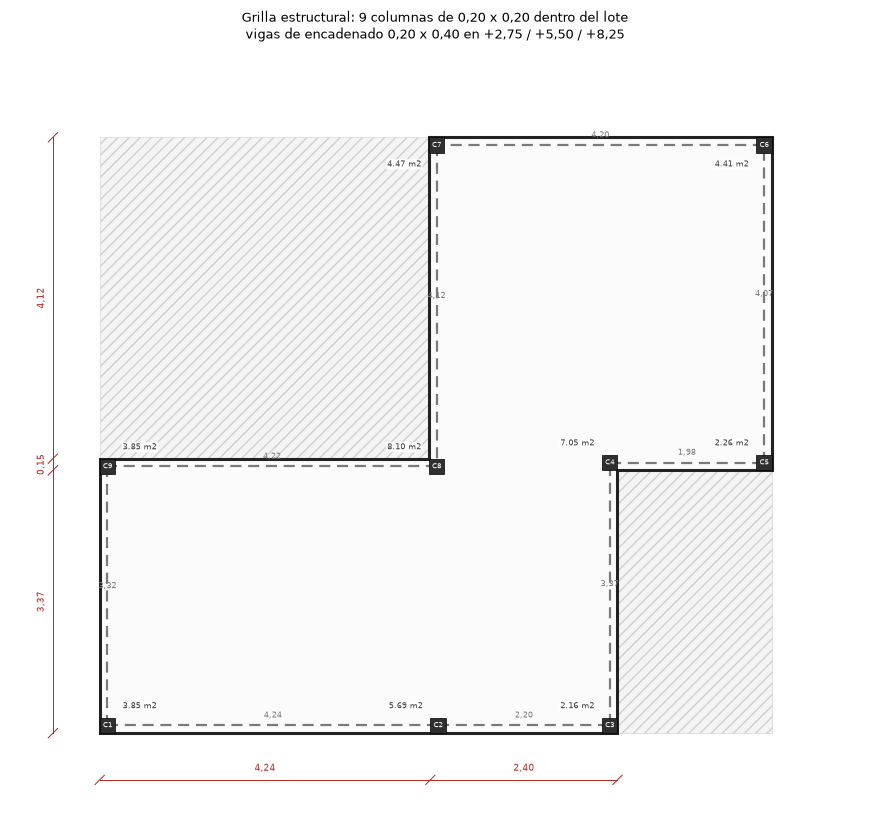

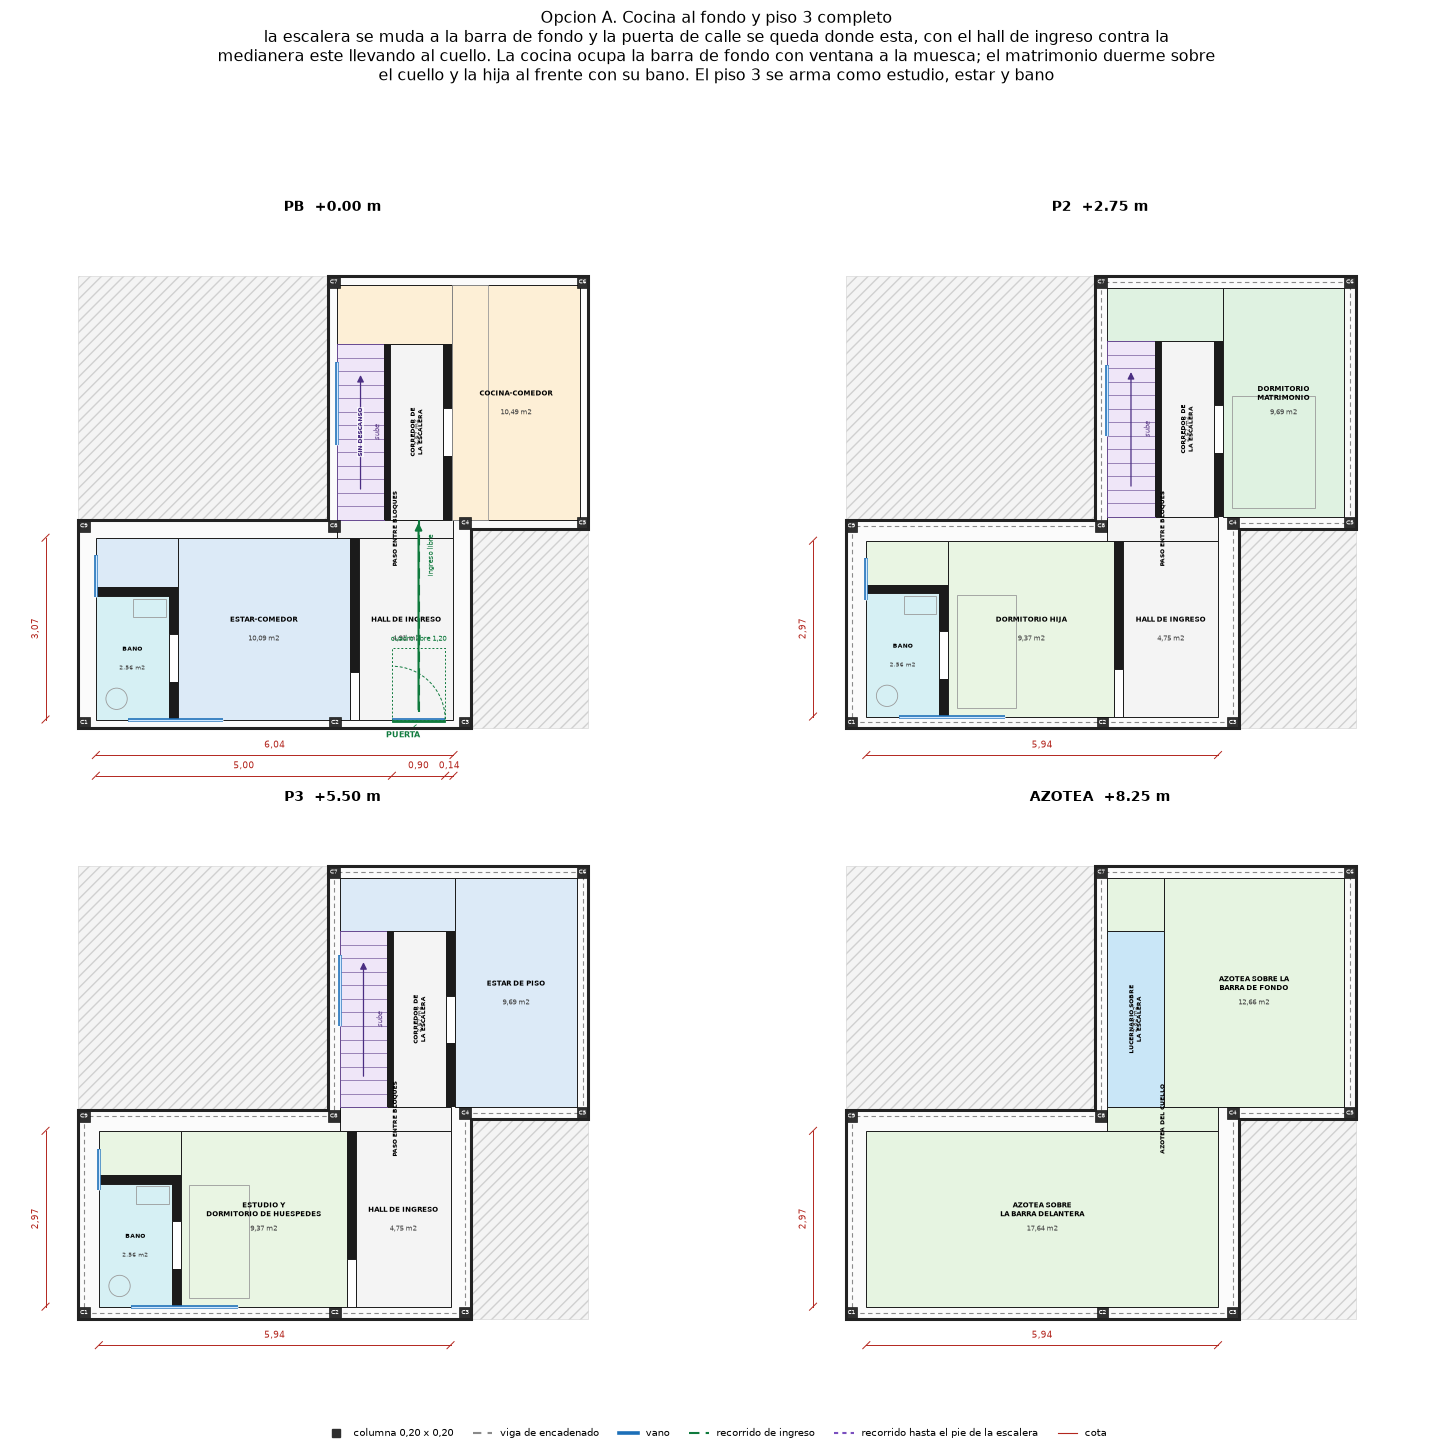

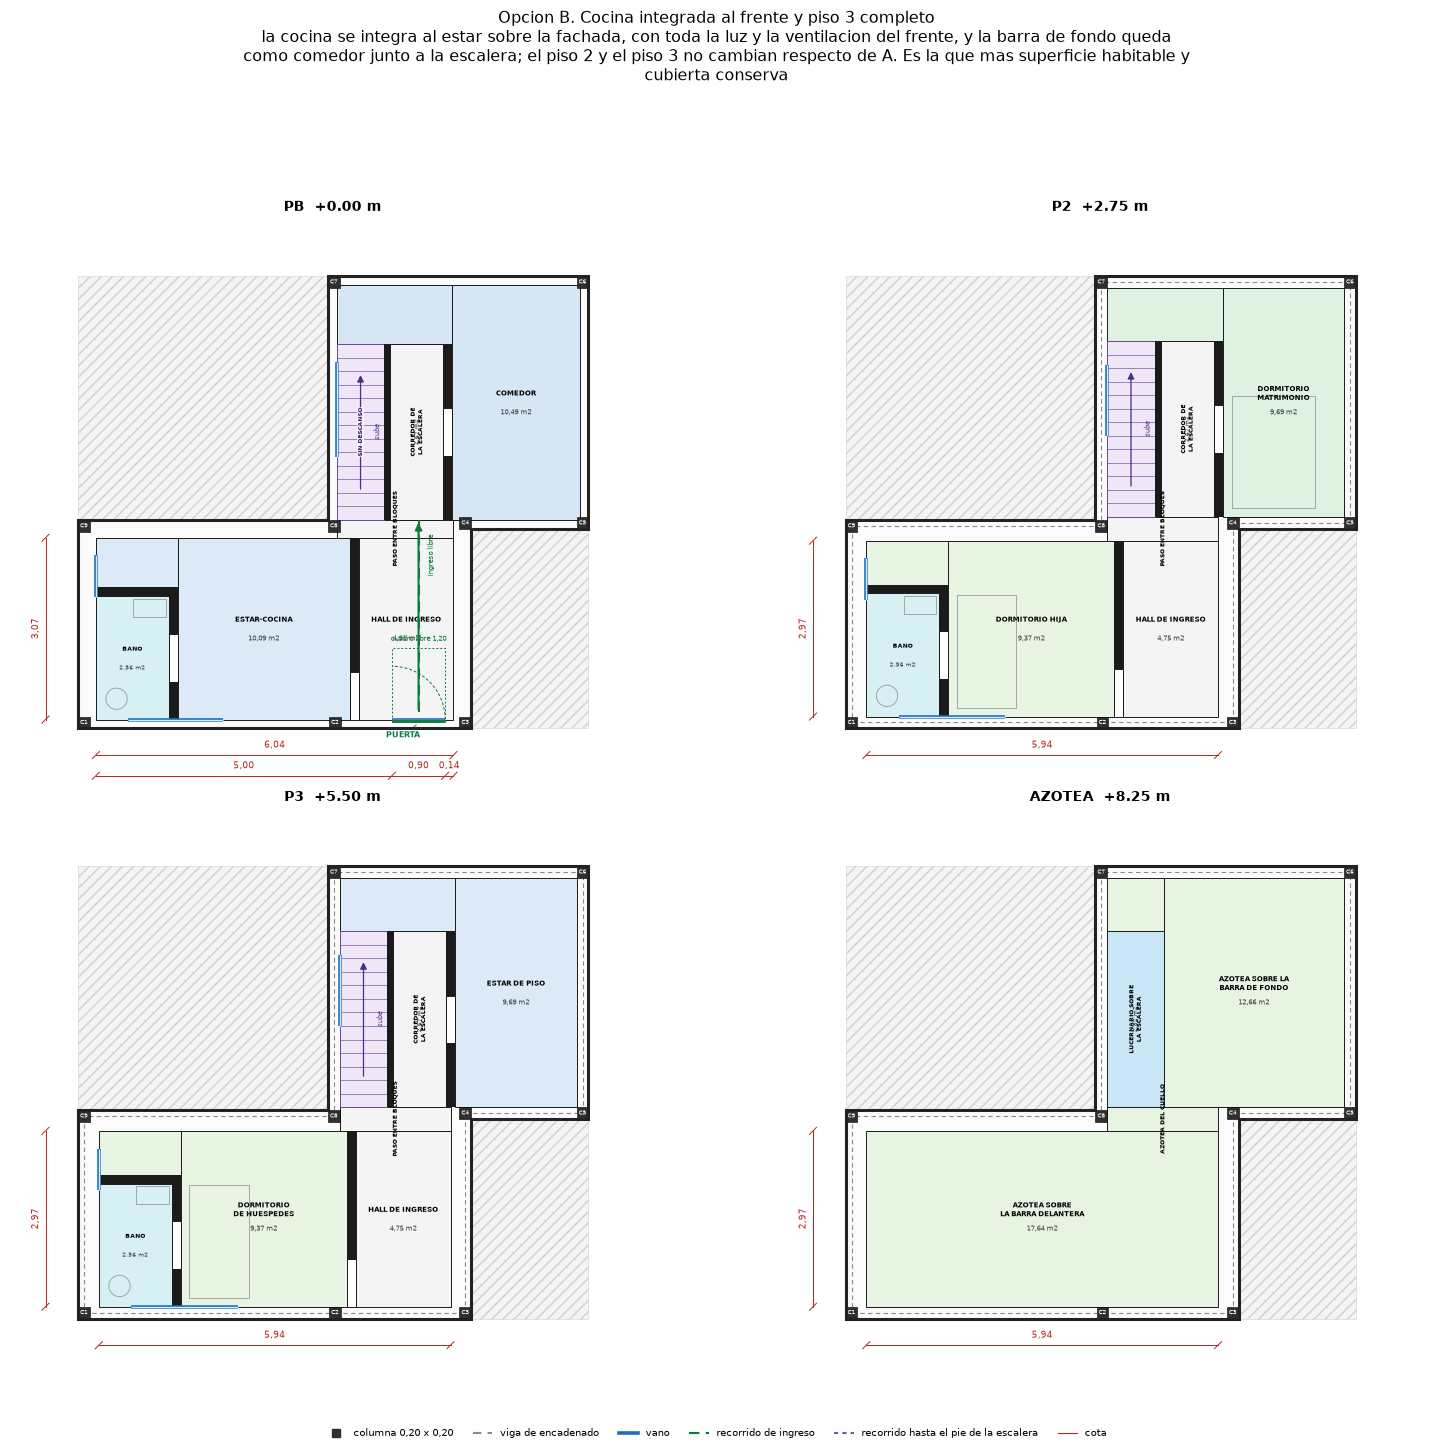

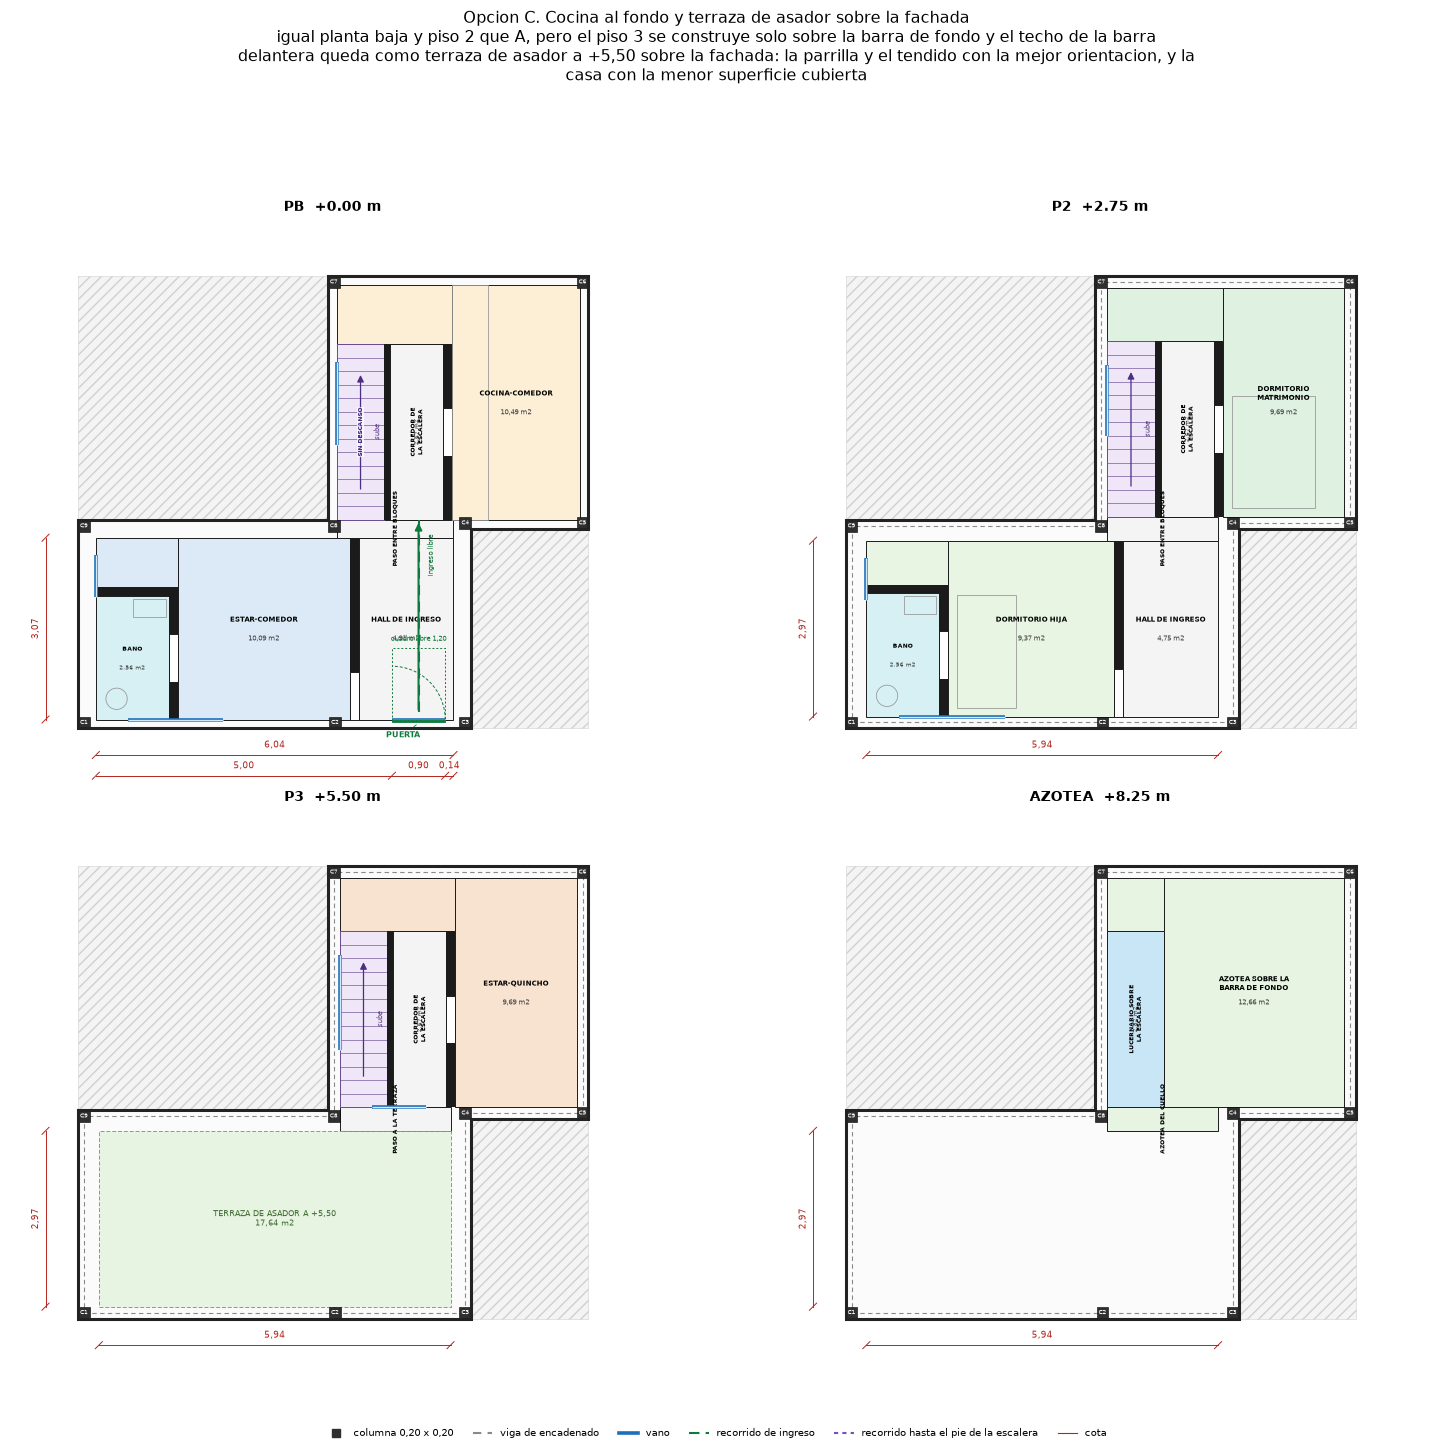

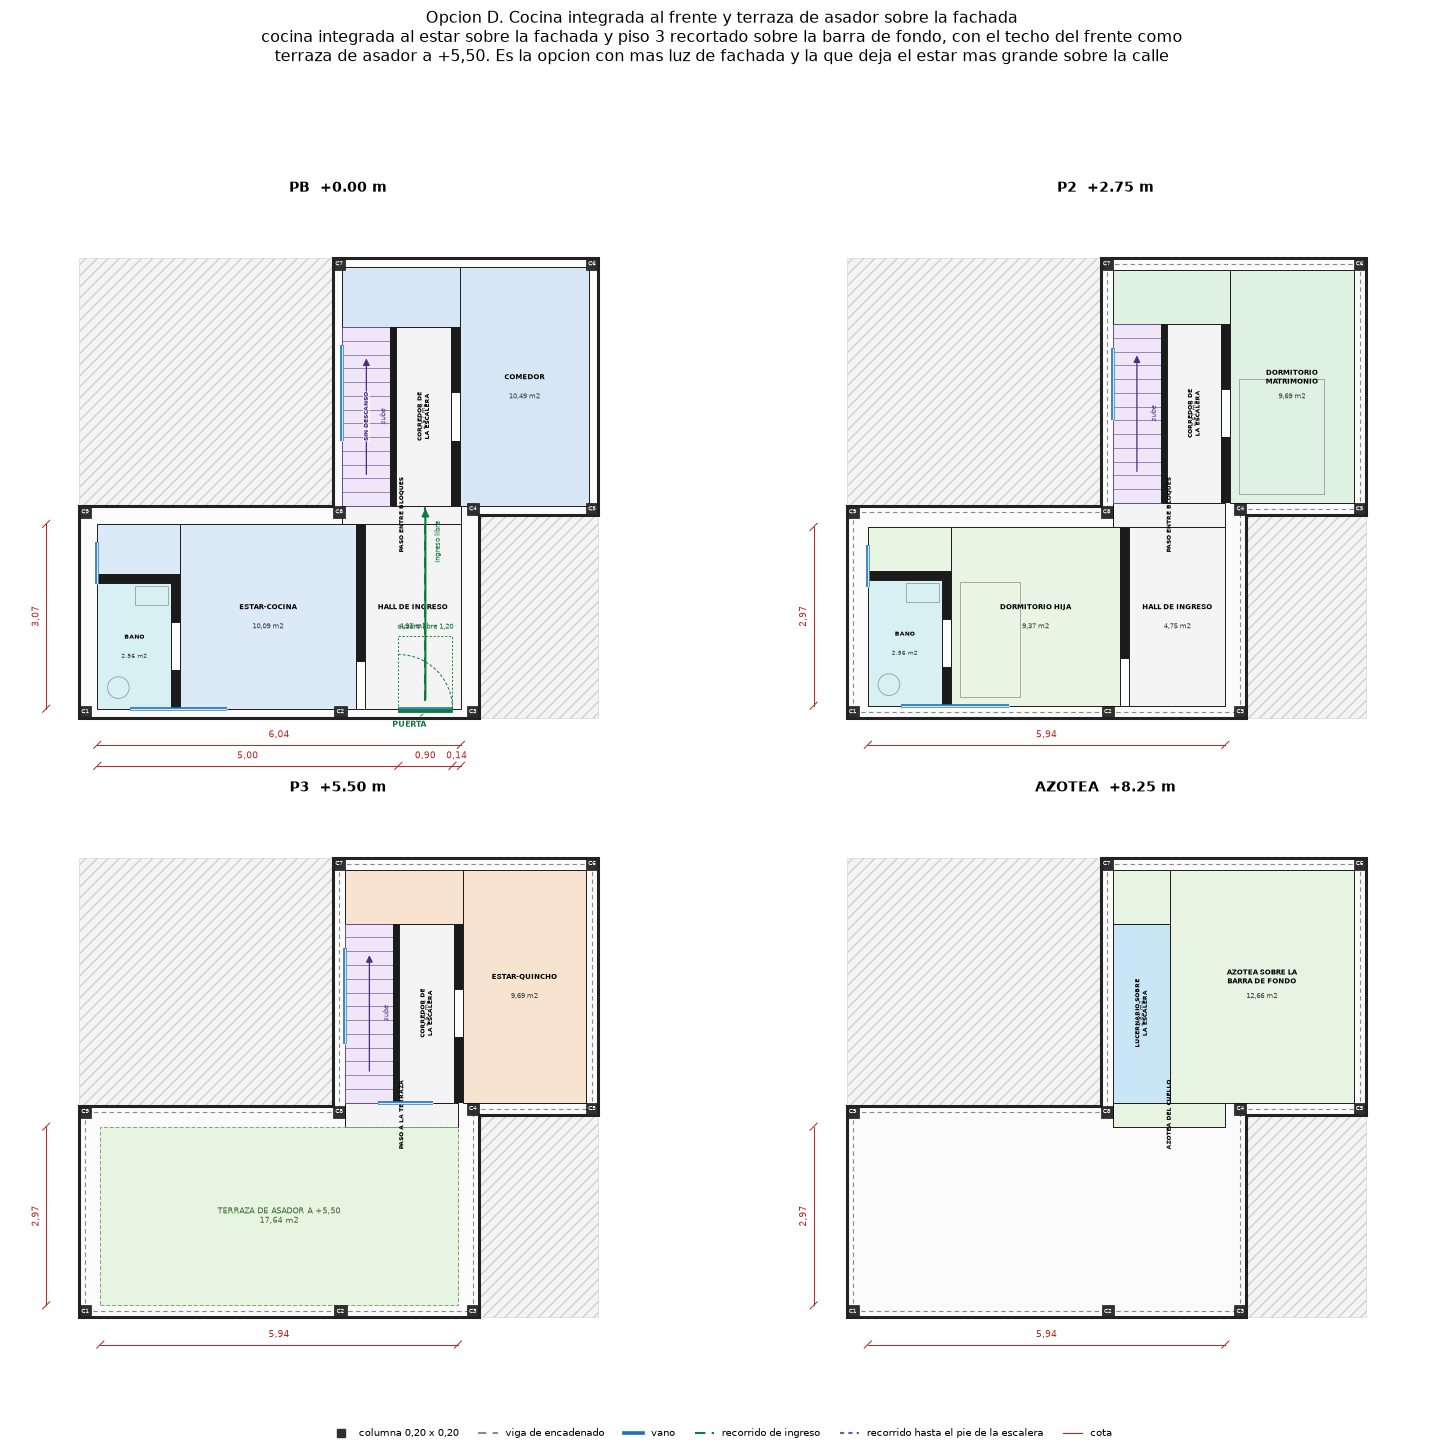

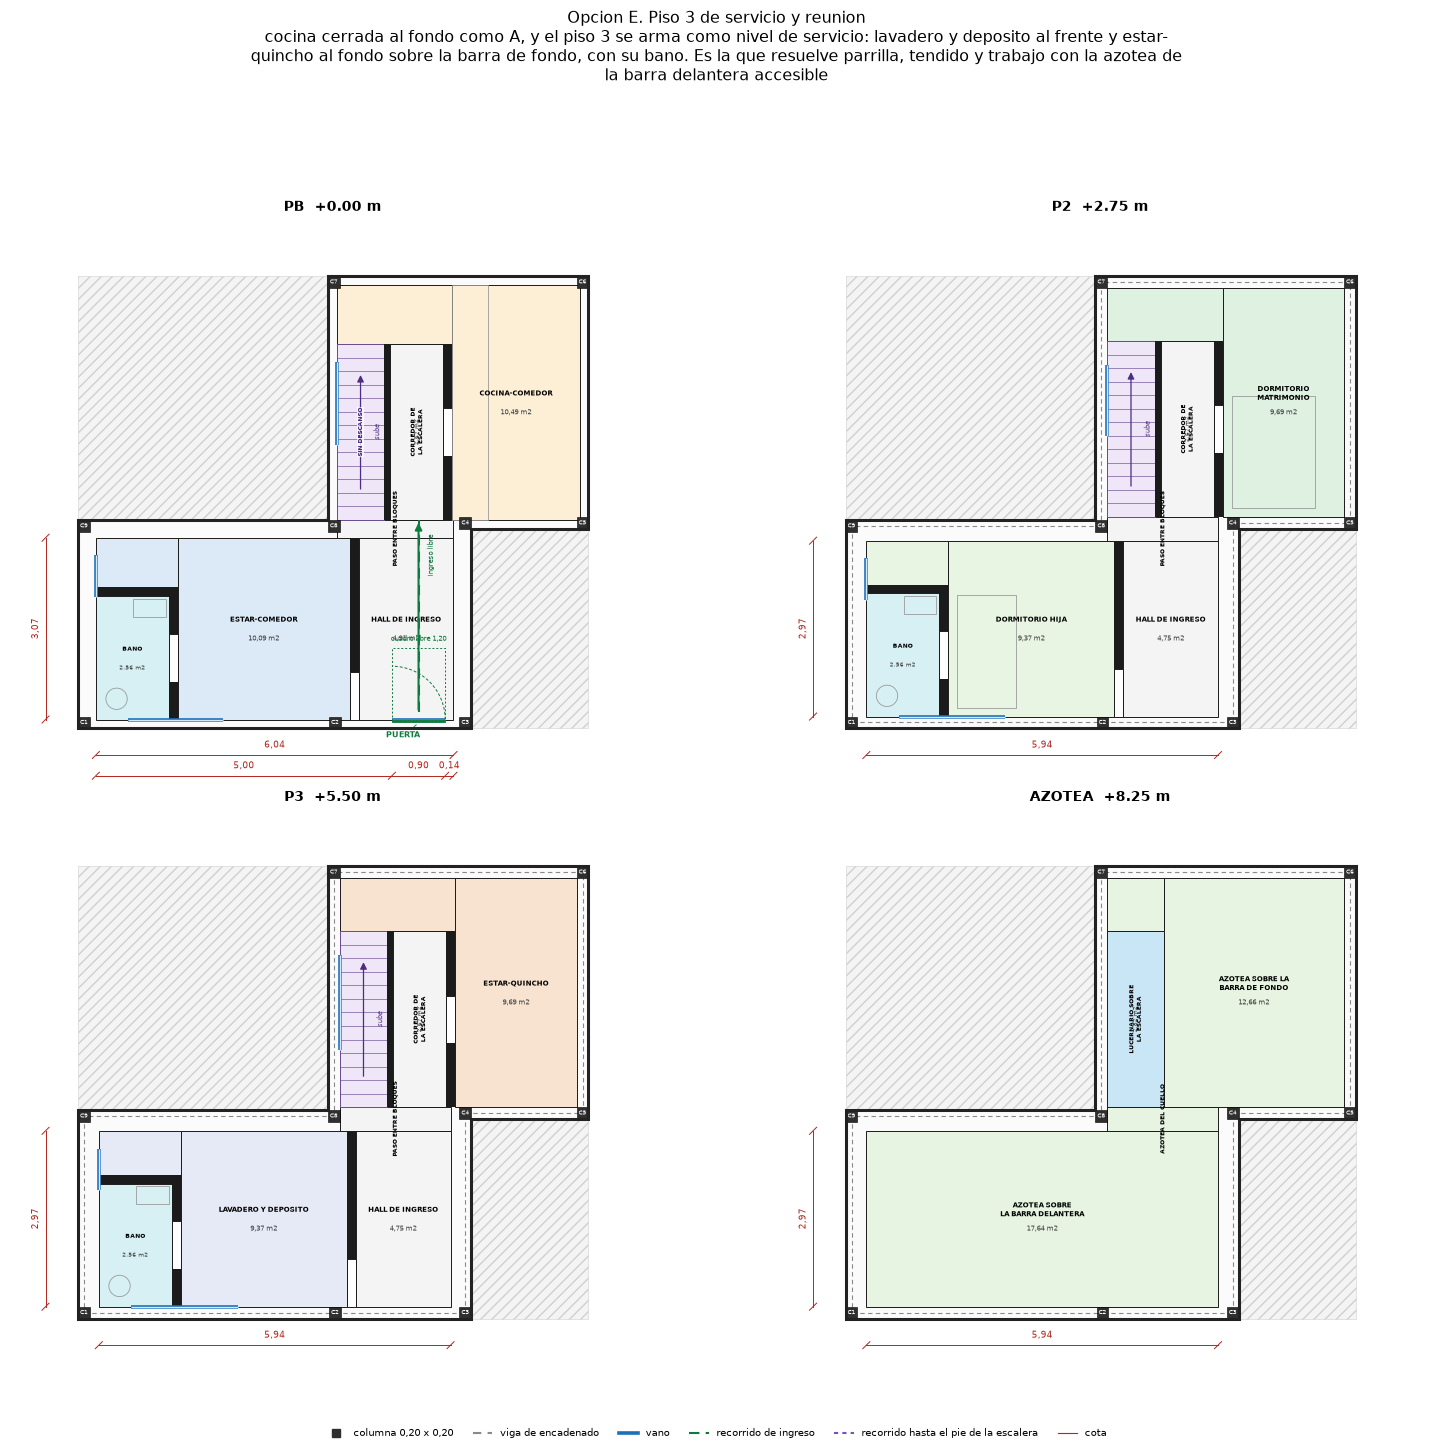

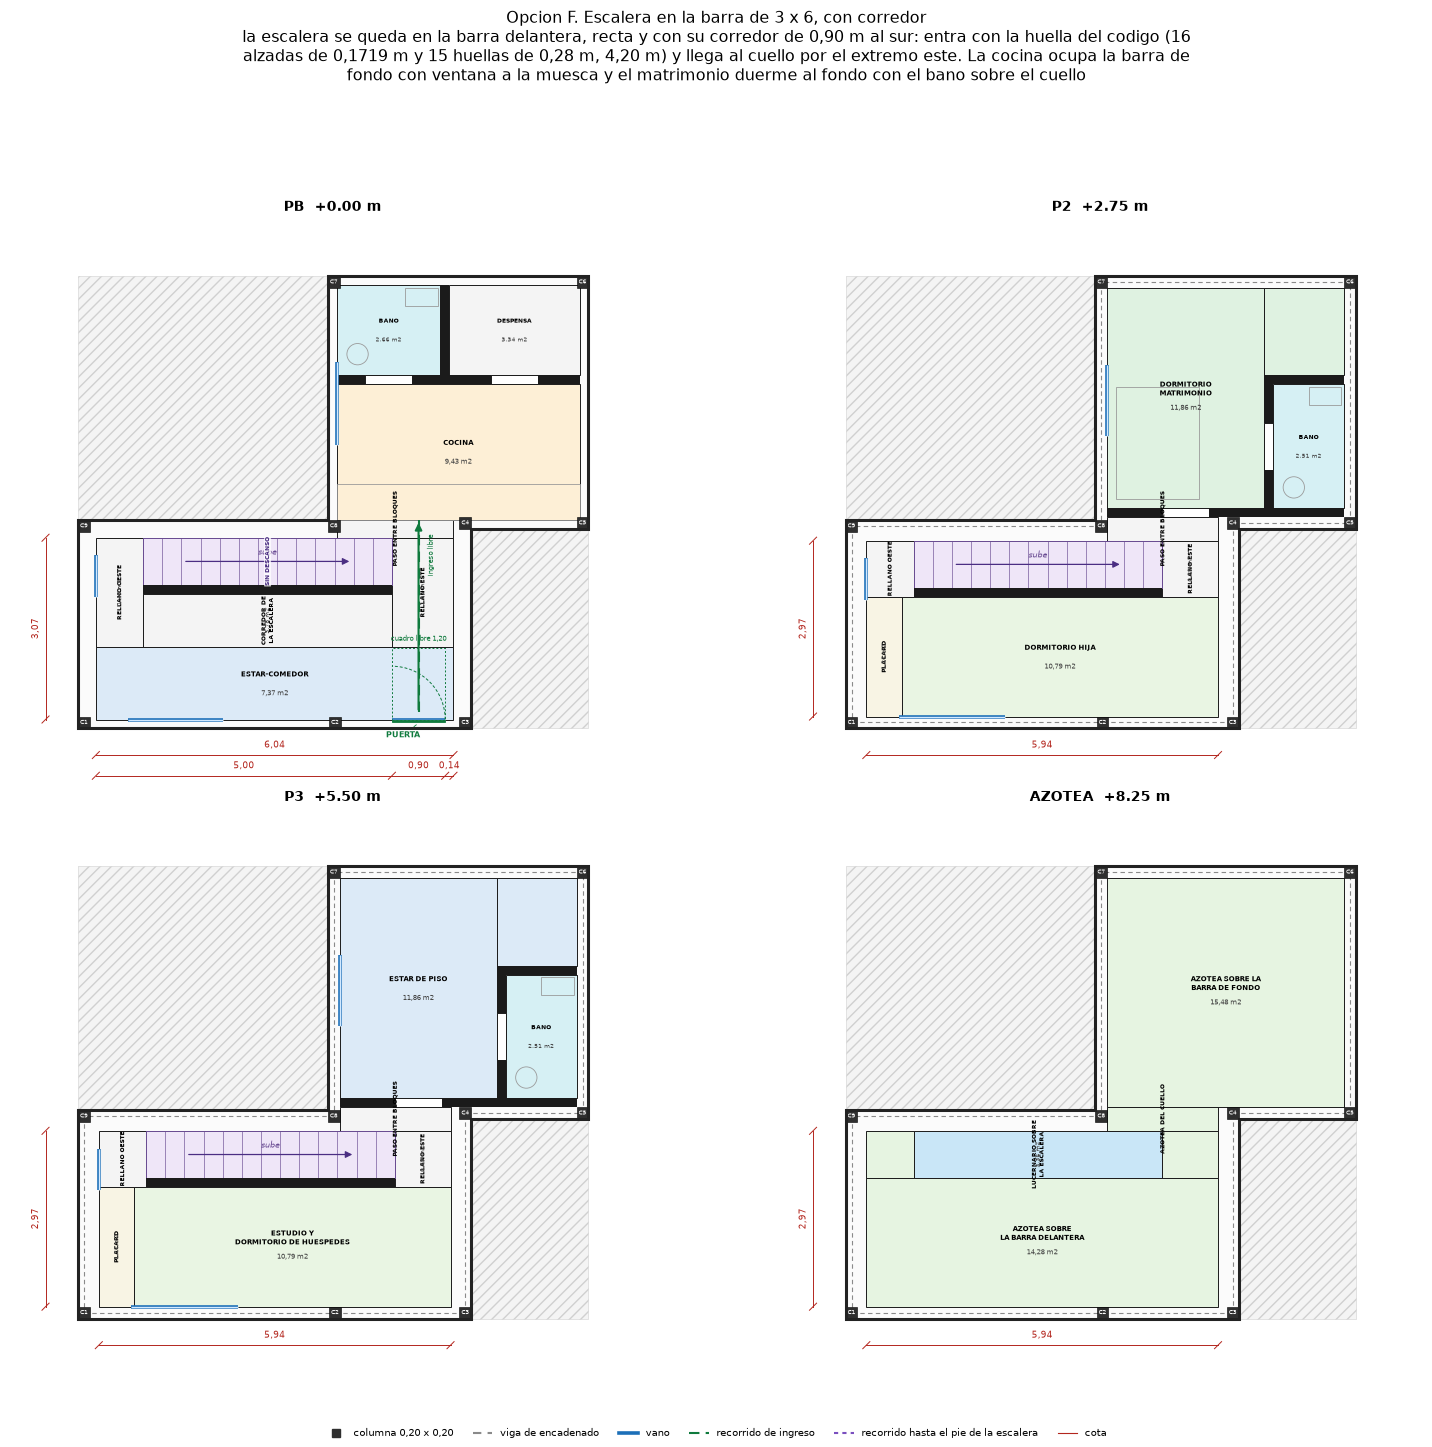

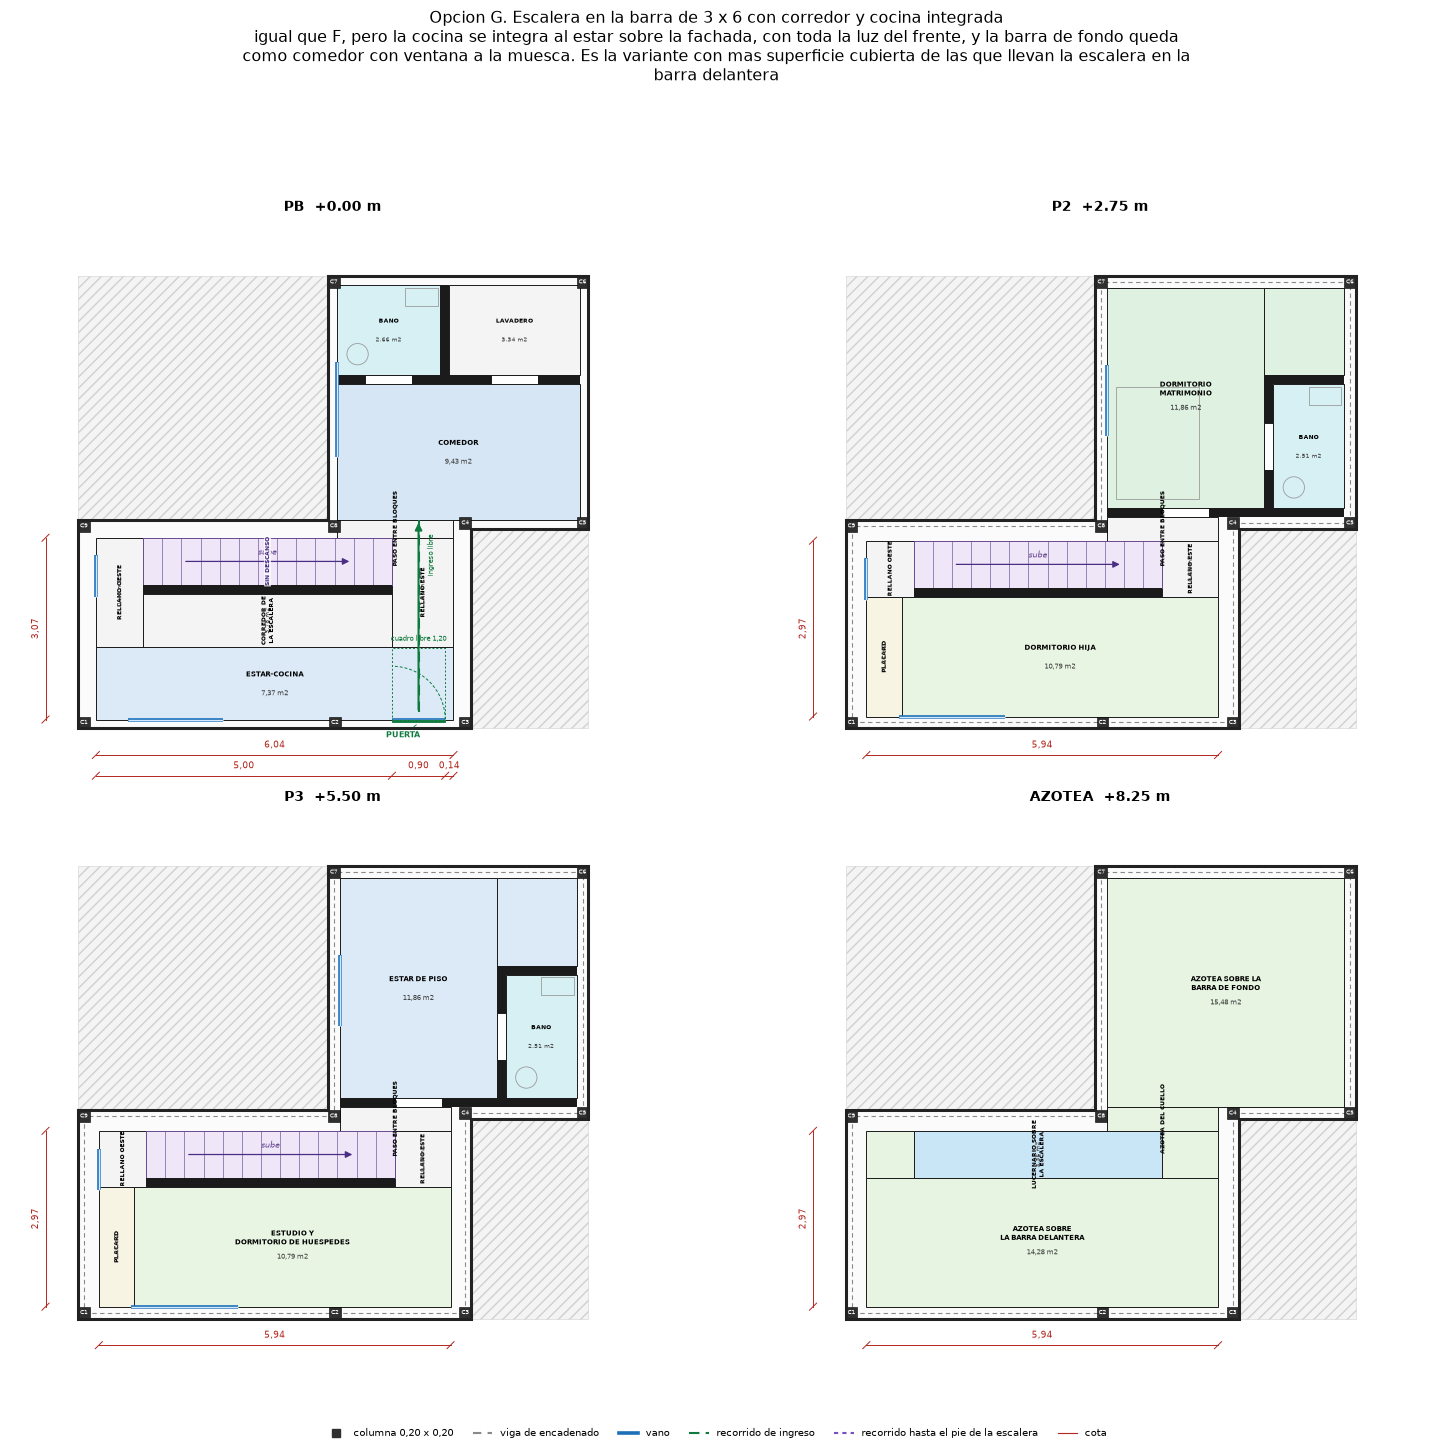

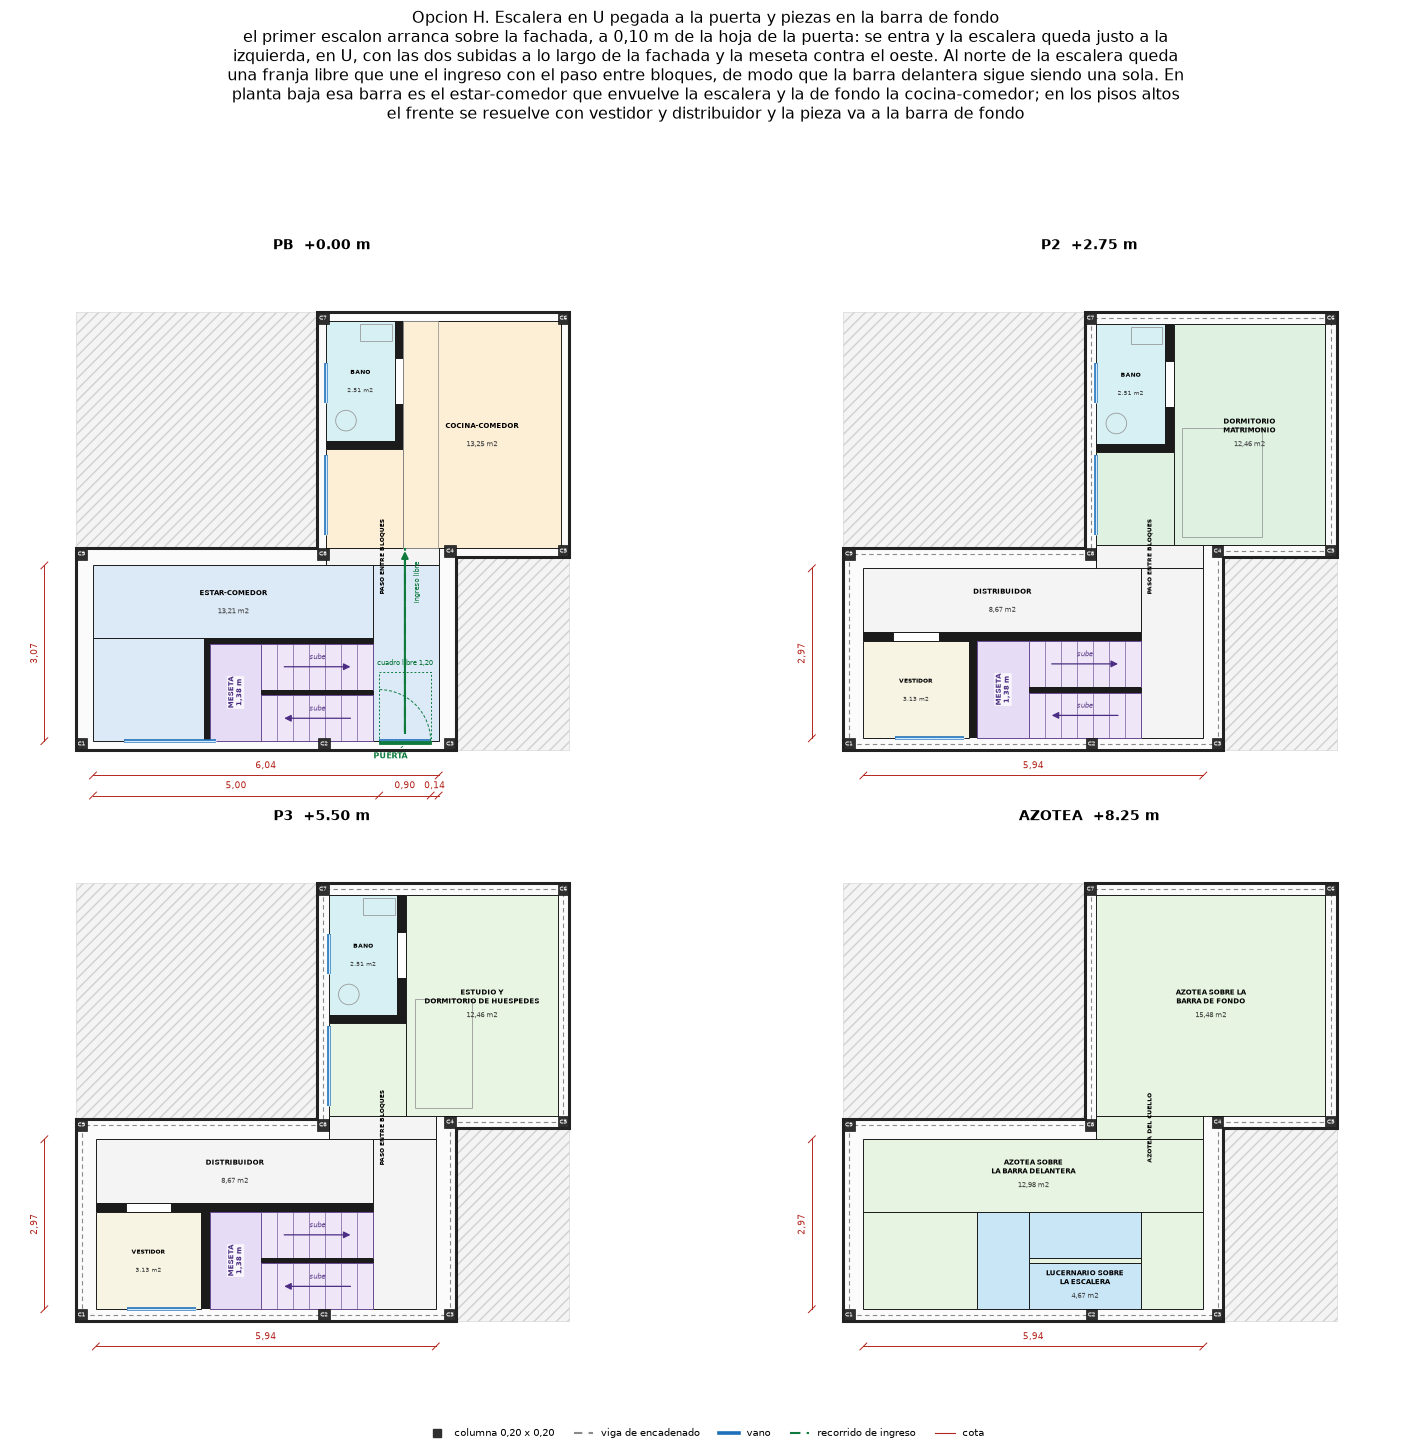

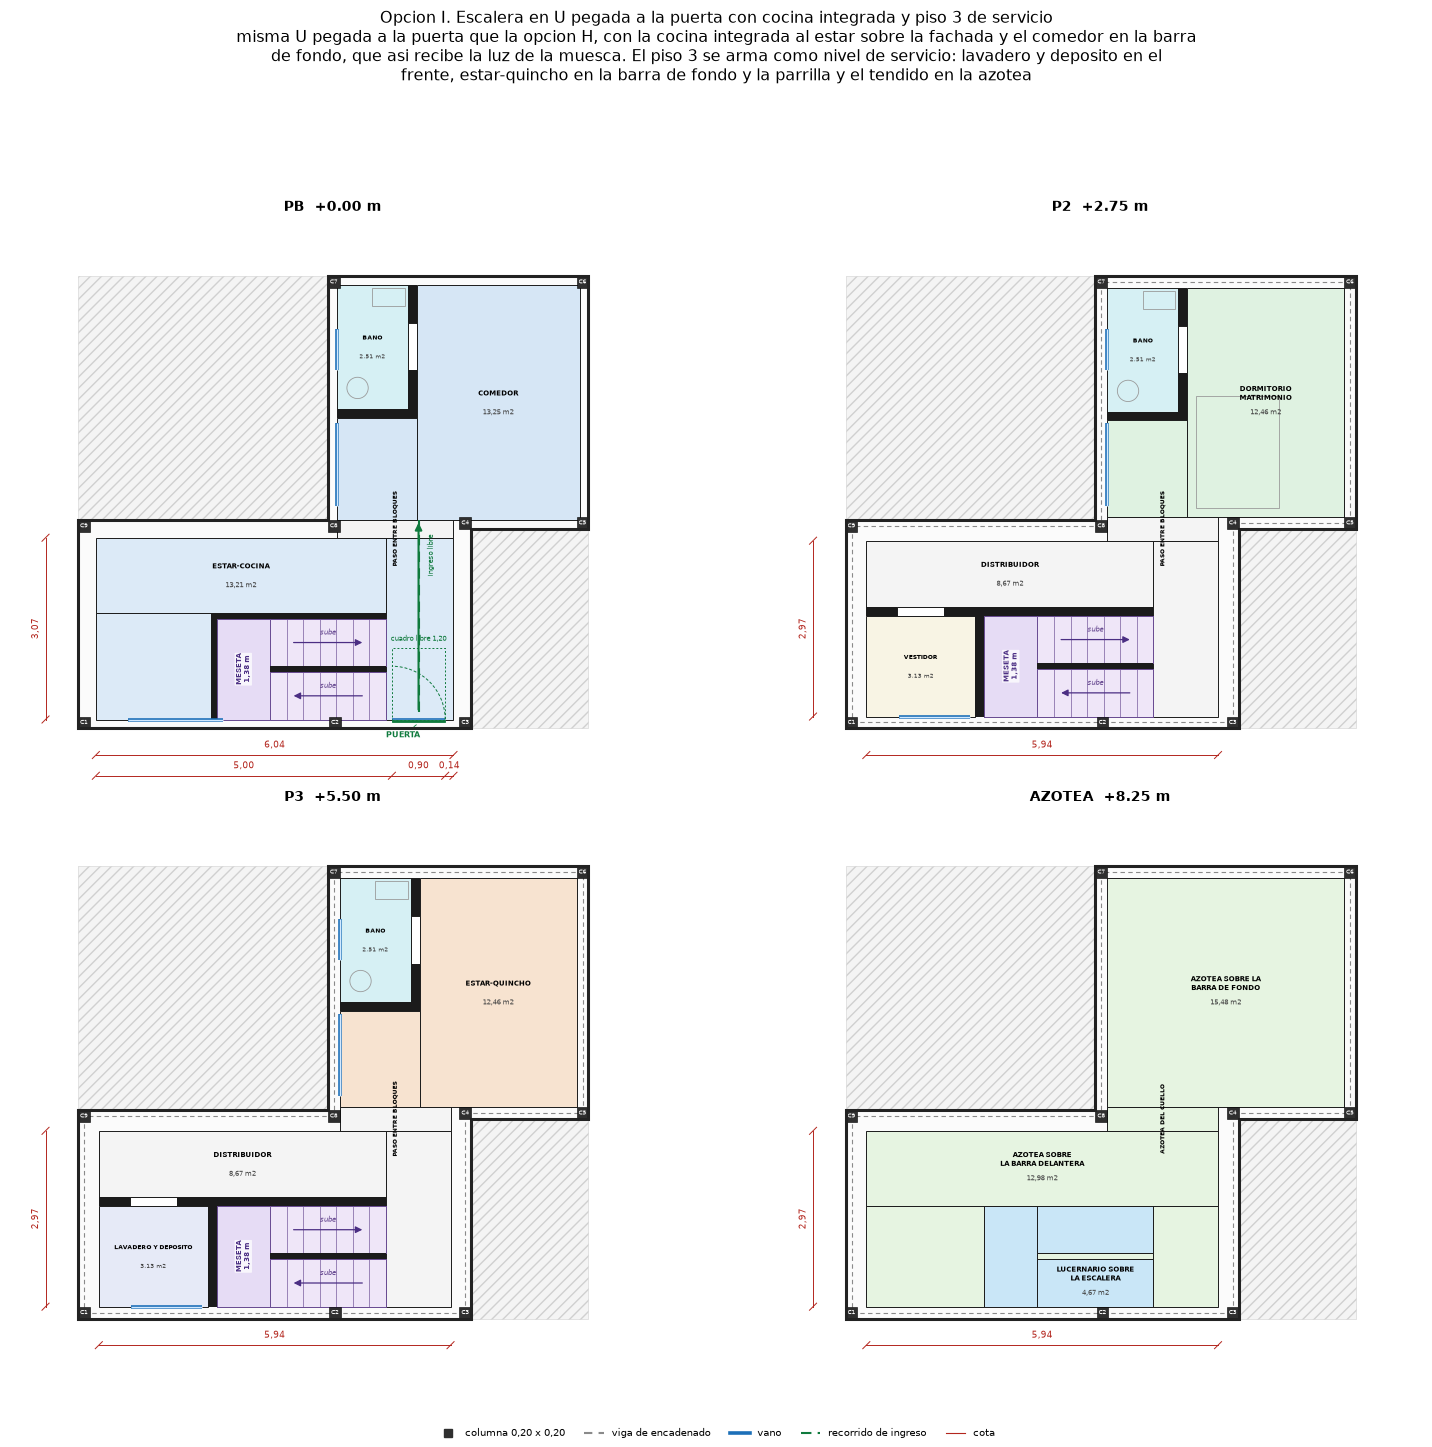

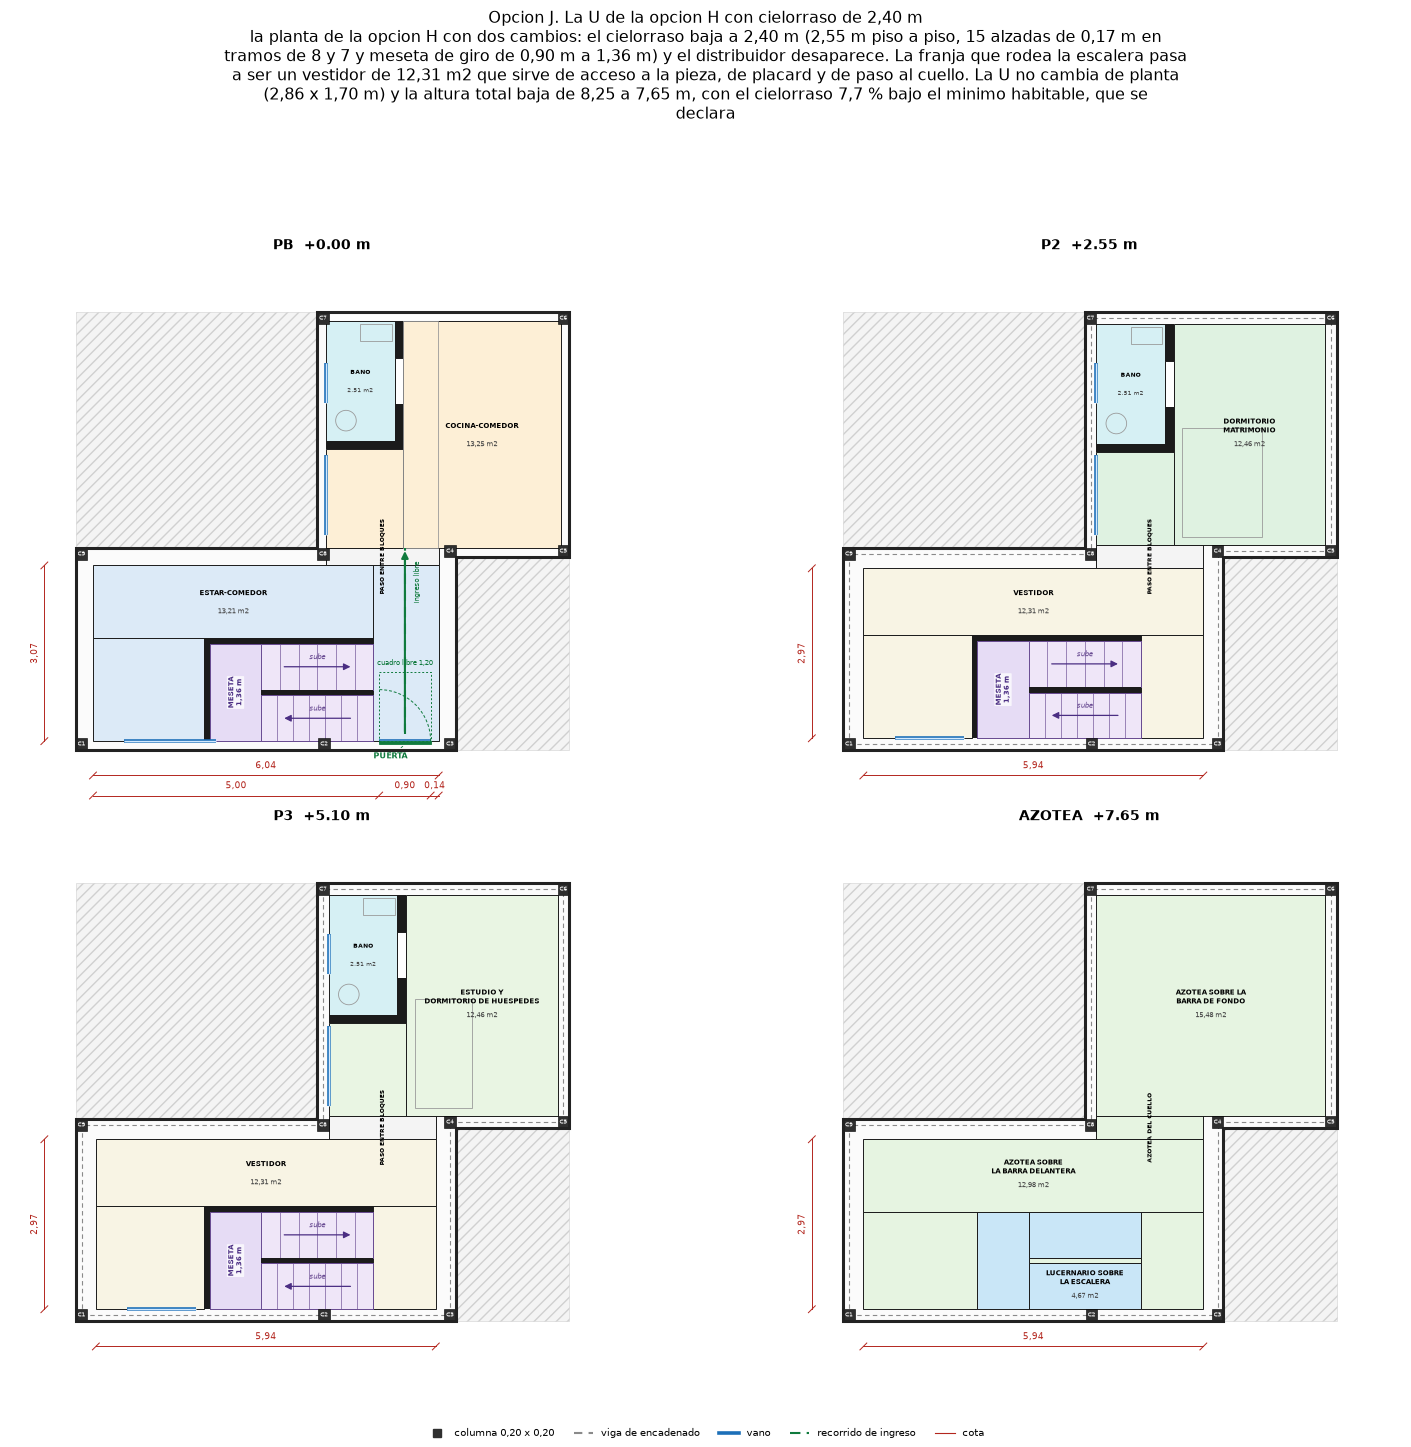

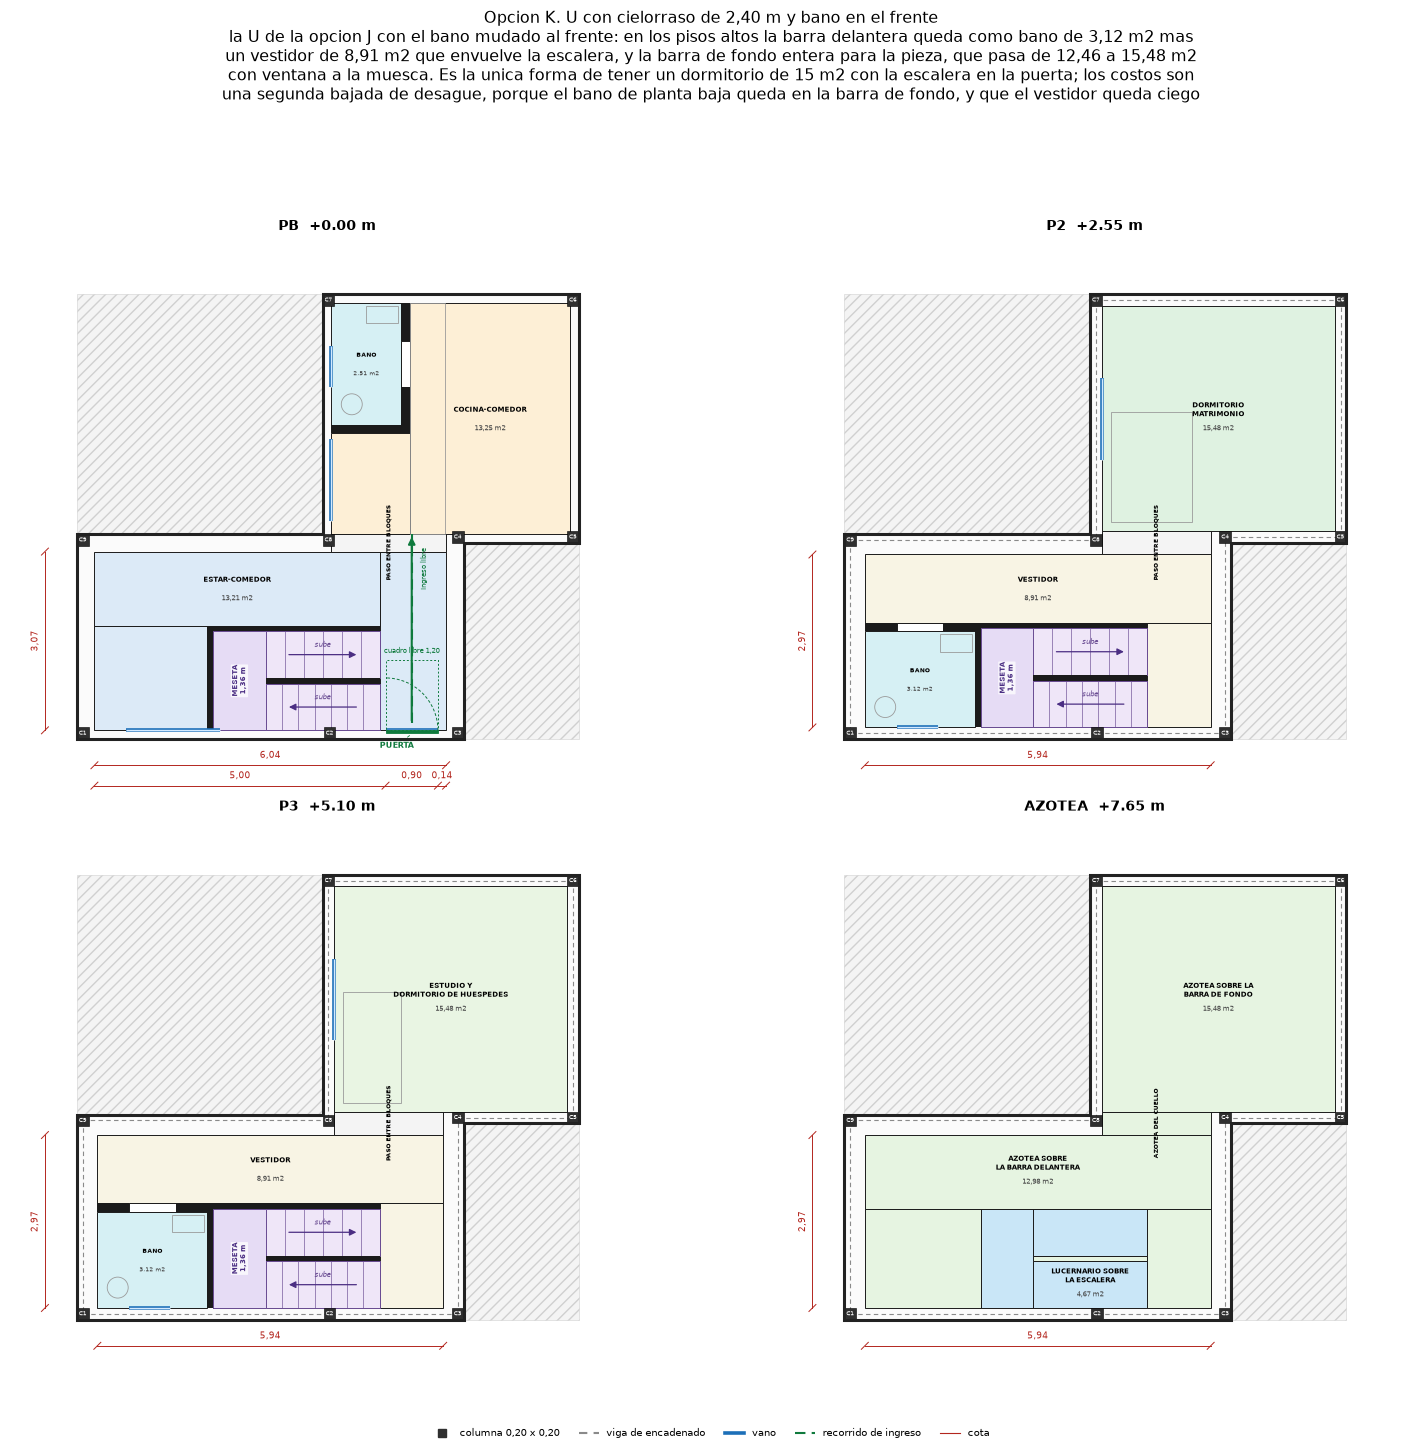

laminas generadas: 12


In [7]:
import textwrap

import matplotlib.pyplot as plt
from matplotlib.patches import Circle, Polygon as ParchePoligono
from matplotlib.patches import Rectangle as ParcheRectangulo
from matplotlib.patches import Arc as ParcheArco

COLOR_TIPO = {
    'estar': '#dceaf7', 'comedor': '#d6e6f5', 'quincho': '#f7e3d0', 'cocina': '#fdefd6',
    'dormitorio_ppal': '#dff2e1', 'dormitorio': '#e9f5e3', 'bano': '#d6f0f4',
    'circulacion': '#f4f4f4', 'escalera': '#eee0f6', 'lavadero': '#e6eaf7',
    'deposito': '#f4f4f4', 'placard': '#f8f4e4', 'terraza': '#e6f4e1',
    'lucernario': '#c9e6f7', 'estudio': '#e2ecfa', 'tabique': '#333333', 'cubierta': '#efefef',
}
COLOR_TRAZO = '#1b1b1b'
COLOR_COTA = '#b3261e'
COLOR_EJE = '#8a8a8a'
COLOR_ESCALERA = '#6a4c93'
COLOR_MOBILIARIO = '#9a9a9a'


def dibujar_cadena(ax, tramos_m, arranque, eje: str, cota_perp_m: float) -> None:
    bordes = [arranque[0] if eje == 'x' else arranque[1]]
    for tramo_m in tramos_m:
        bordes.append(bordes[-1] + tramo_m)
    if eje == 'x':
        ax.plot([bordes[0], bordes[-1]], [cota_perp_m, cota_perp_m], color=COLOR_COTA, lw=0.7, zorder=20)
    else:
        ax.plot([cota_perp_m, cota_perp_m], [bordes[0], bordes[-1]], color=COLOR_COTA, lw=0.7, zorder=20)
    for borde in bordes:
        if eje == 'x':
            ax.plot([borde - 0.06, borde + 0.06], [cota_perp_m - 0.06, cota_perp_m + 0.06],
                    color=COLOR_COTA, lw=0.7, zorder=20)
        else:
            ax.plot([cota_perp_m - 0.06, cota_perp_m + 0.06], [borde - 0.06, borde + 0.06],
                    color=COLOR_COTA, lw=0.7, zorder=20)
    for i, tramo_m in enumerate(tramos_m):
        centro_m = (bordes[i] + bordes[i + 1]) / 2
        etiqueta = f'{tramo_m:.2f}'.replace('.', ',')
        if eje == 'x':
            ax.text(centro_m, cota_perp_m + 0.09, etiqueta, ha='center', va='bottom',
                    fontsize=6.5, color=COLOR_COTA, zorder=20)
        else:
            ax.text(cota_perp_m - 0.09, centro_m, etiqueta, ha='right', va='center', rotation=90,
                    fontsize=6.5, color=COLOR_COTA, zorder=20)


def dibujar_escalera(ax, rects, ala: str = 'frente', huellas: int = None) -> None:
    """Dibuja el tramo recto unico: peldaños y flecha de subida en el sentido real."""
    for rect in rects:
        x0, y0, x1, y1 = rect
        ax.add_patch(ParcheRectangulo((x0, y0), x1 - x0, y1 - y0, facecolor='#efe6f8',
                                      edgecolor=COLOR_ESCALERA, lw=0.7, zorder=4))
        vertical = (y1 - y0) >= (x1 - x0)
        n_lineas = huellas if huellas else N_HUELLAS_TRAMO
        for i in range(1, n_lineas + 1):
            if vertical:
                y = y0 + (y1 - y0) * i / n_lineas
                ax.plot([x0, x1], [y, y], color=COLOR_ESCALERA, lw=0.45, zorder=5)
            else:
                x = x0 + (x1 - x0) * i / n_lineas
                ax.plot([x, x], [y0, y1], color=COLOR_ESCALERA, lw=0.45, zorder=5)
        centro_x, centro_y = (x0 + x1) / 2, (y0 + y1) / 2
        if vertical:
            # la barra delantera sube hacia el fondo (norte) y la de fondo hacia el cuello (sur)
            signo = 1.0 if ala == 'frente' else -1.0
            ax.annotate('', xy=(centro_x, centro_y + signo * (y1 - y0) * 0.34),
                        xytext=(centro_x, centro_y - signo * (y1 - y0) * 0.34),
                        arrowprops=dict(arrowstyle='-|>', color='#4b2e83', lw=0.9), zorder=7)
            ax.text(centro_x + 0.28, centro_y, 'sube', rotation=90, ha='center', va='center',
                    fontsize=5.2, color=COLOR_ESCALERA, style='italic', zorder=6)
        else:
            ax.annotate('', xy=(centro_x + (x1 - x0) * 0.34, centro_y),
                        xytext=(centro_x - (x1 - x0) * 0.34, centro_y),
                        arrowprops=dict(arrowstyle='-|>', color='#4b2e83', lw=0.9), zorder=7)
            ax.text(centro_x, centro_y + 0.16, 'sube', ha='center', va='center',
                    fontsize=5.6, color=COLOR_ESCALERA, style='italic', zorder=6)


def dibujar_escalera_u(ax, rects, huellas=HUELLAS_TRAMO_U,
                       meseta_m: float = None) -> None:
    """Dibuja la U de dos tramos a lo largo de la fachada: peldaños, meseta y sentido de subida."""
    if isinstance(huellas, int):
        huellas = (huellas, huellas)
    if meseta_m is None:
        meseta_m = ESCALERA_PUERTA_PB['altura_meseta_m']
    tramo_bajo, meseta, tramo_alto = rects
    for rect, sentido, n_huellas in ((tramo_bajo, -1.0, huellas[0]),
                                     (tramo_alto, 1.0, huellas[1])):
        x0, y0, x1, y1 = rect
        ax.add_patch(ParcheRectangulo((x0, y0), x1 - x0, y1 - y0, facecolor='#efe6f8',
                                      edgecolor=COLOR_ESCALERA, lw=0.7, zorder=4))
        for i in range(1, n_huellas + 1):
            x = x0 + (x1 - x0) * i / n_huellas
            ax.plot([x, x], [y0, y1], color=COLOR_ESCALERA, lw=0.45, zorder=5)
        centro_x, centro_y = (x0 + x1) / 2, (y0 + y1) / 2
        medio_m = (x1 - x0) * 0.32
        ax.annotate('', xy=(centro_x + sentido * medio_m, centro_y),
                    xytext=(centro_x - sentido * medio_m, centro_y),
                    arrowprops=dict(arrowstyle='-|>', color='#4b2e83', lw=0.9), zorder=7)
        ax.text(centro_x, centro_y + 0.17, 'sube', ha='center', va='center', fontsize=5.4,
                color=COLOR_ESCALERA, style='italic', zorder=6)
    x0, y0, x1, y1 = meseta
    ax.add_patch(ParcheRectangulo((x0, y0), x1 - x0, y1 - y0, facecolor='#e6dcf5',
                                  edgecolor=COLOR_ESCALERA, lw=0.7, zorder=4))
    ax.text((x0 + x1) / 2, (y0 + y1) / 2,
            f'MESETA\n{meseta_m:.2f} m'.replace('.', ','),
            ha='center', va='center', rotation=90, fontsize=4.8, color='#4b2e83', weight='bold',
            zorder=9, bbox=dict(boxstyle='round,pad=0.10', fc='white', ec='none', alpha=0.75))


def dibujar_mobiliario(ax, un_local: Local) -> None:
    x0, y0, x1, y1 = un_local.rectangulos[0]
    ancho_m, alto_m = x1 - x0, y1 - y0
    if un_local.tipo in ('dormitorio', 'dormitorio_ppal'):
        cama_ancho_m = 1.00 if un_local.tipo == 'dormitorio' else 1.40
        cama_largo_m = 1.90
        if ancho_m >= cama_ancho_m + 0.3 and alto_m >= cama_largo_m + 0.3:
            ax.add_patch(ParcheRectangulo((x0 + 0.15, y0 + 0.15), cama_ancho_m, cama_largo_m,
                                          facecolor='none', edgecolor=COLOR_MOBILIARIO, lw=0.6,
                                          zorder=8))
    elif un_local.tipo == 'cocina':
        profundidad_m = 0.60
        if ancho_m >= alto_m:
            ax.add_patch(ParcheRectangulo((x0, y0), ancho_m, profundidad_m, facecolor='none',
                                          edgecolor=COLOR_MOBILIARIO, lw=0.6, zorder=8))
        else:
            ax.add_patch(ParcheRectangulo((x0, y0), profundidad_m, alto_m, facecolor='none',
                                          edgecolor=COLOR_MOBILIARIO, lw=0.6, zorder=8))
    elif un_local.tipo == 'bano' and min(ancho_m, alto_m) >= 1.20:
        ax.add_patch(Circle((x0 + 0.35, y0 + 0.35), 0.18, facecolor='none',
                            edgecolor=COLOR_MOBILIARIO, lw=0.6, zorder=8))
        ax.add_patch(ParcheRectangulo((x1 - 0.60, y1 - 0.35), 0.55, 0.30, facecolor='none',
                                      edgecolor=COLOR_MOBILIARIO, lw=0.6, zorder=8))


def dibujar_nivel(ax, id_opcion: str, nombre_nivel: str) -> None:
    opcion = OPCIONES[id_opcion]
    nivel_datos = opcion['niveles'][nombre_nivel]
    nivel = {'PB': NIVEL_PB, 'P2': NIVEL_P2, 'P3': NIVEL_P3, 'AZOTEA': NIVEL_P2}[nombre_nivel]
    ax.set_aspect('equal')
    ax.axis('off')

    for muesca in ([(6.64, 0.00), (8.62, 0.00), (8.62, 3.37), (6.64, 3.37)],
                   [(0.00, 3.52), (4.22, 3.52), (4.22, 7.64), (0.00, 7.64)]):
        ax.add_patch(ParchePoligono(muesca, closed=True, facecolor='#f4f4f4',
                                    edgecolor='#d0d0d0', lw=0.4, hatch='///', zorder=0))
    ax.add_patch(ParchePoligono(LIMITES_XY_M, closed=True, facecolor='#fbfbfb',
                                edgecolor='none', zorder=0.5))

    for viga in VIGAS:
        if viga.nivel != nombre_nivel:
            continue
        (xa, ya), (xb, yb) = COLUMNAS_POR_ID[viga.desde].centro_xy, COLUMNAS_POR_ID[viga.hasta].centro_xy
        ax.plot([xa, xb], [ya, yb], color=COLOR_EJE, lw=0.8, ls=(0, (4, 3)), zorder=1)

    for un_local in nivel_datos['locales']:
        if un_local.tipo == 'tabique':
            for x0, y0, x1, y1 in un_local.rectangulos:
                ax.add_patch(ParcheRectangulo((x0, y0), x1 - x0, y1 - y0, facecolor=COLOR_TRAZO,
                                              edgecolor='none', zorder=6))
            continue
        color = COLOR_TIPO.get(un_local.tipo, '#ffffff')
        for x0, y0, x1, y1 in un_local.rectangulos:
            ax.add_patch(ParcheRectangulo((x0, y0), x1 - x0, y1 - y0, facecolor=color,
                                          edgecolor=COLOR_TRAZO, lw=0.7, zorder=3))
        dibujar_mobiliario(ax, un_local)
        if un_local.tipo in ('umbral', 'escalera'):
            continue
        if len(un_local.rectangulos) > 1:
            rect_mayor = max(un_local.rectangulos,
                             key=lambda r: (r[2] - r[0]) * (r[3] - r[1]))
            centro_x = (rect_mayor[0] + rect_mayor[2]) / 2
            centro_y = (rect_mayor[1] + rect_mayor[3]) / 2
        else:
            centro_x, centro_y = un_local.centro_xy
        ancho_m, alto_m = un_local.caja_xy
        angosto = min(ancho_m, alto_m) < 1.15
        rotacion = 90 if angosto else 0
        escala = 1.0 if un_local.area_m2 > 4.0 else 0.85
        rotulo = un_local.nombre.upper()
        if len(rotulo) > 20:
            palabras = rotulo.split(' ')
            corte = len(palabras) // 2
            rotulo = ' '.join(palabras[:corte]) + '\n' + ' '.join(palabras[corte:])
        ax.text(centro_x, centro_y + (0.15 if not angosto else 0.0), rotulo,
                ha='center', va='center', rotation=rotacion, fontsize=5.3 * escala, zorder=9,
                weight='bold')
        if un_local.area_m2 >= 0.80:
            ax.text(centro_x, centro_y - (0.17 if not angosto else 0.0),
                    f'{un_local.area_m2:.2f} m2'.replace('.', ','), ha='center', va='center',
                    rotation=rotacion, fontsize=4.9 * escala, color='#444444', zorder=9)

    for un_local in nivel_datos['locales']:
        if un_local.tipo != 'escalera':
            continue
        tramo = un_local.rectangulos[0]
        if len(un_local.rectangulos) == len(ESCALERA_PUERTA_PB['tramos']):
            altura = opcion.get('altura', {})
            dibujar_escalera_u(ax, un_local.rectangulos,
                               altura.get('huellas_tramo', HUELLAS_TRAMO_U),
                               altura.get('meseta_m', ESCALERA_PUERTA_PB['altura_meseta_m']))
            continue
        huellas = N_HUELLAS_LEY if (tramo[3] - tramo[1]) > 3.5 else N_HUELLAS_TRAMO
        dibujar_escalera(ax, un_local.rectangulos, opcion.get('ala', 'frente'), huellas)

    # las terrazas de otro nivel que se apoyan sobre este (opcion C: terraza a +5,50)
    for un_local in nivel_datos.get('exteriores', []):
        for x0, y0, x1, y1 in un_local.rectangulos:
            ax.add_patch(ParcheRectangulo((x0, y0), x1 - x0, y1 - y0, facecolor='#e6f4e1',
                                          edgecolor='#7aa86a', lw=0.7, ls=(0, (4, 2)), zorder=3))
        centro_x, centro_y = un_local.centro_xy
        ax.text(centro_x, centro_y, f'{un_local.nombre.upper()}\n{un_local.area_m2:.2f} m2'.replace('.', ','),
                ha='center', va='center', fontsize=5.6, color='#3f6b32', zorder=9)

    for vano in nivel_datos['vanos']:
        (xa, ya), (xb, yb), _ = segmento_vano(vano)
        ax.plot([xa, xb], [ya, yb], color='#1c6fb8', lw=2.6, solid_capstyle='butt', zorder=10)
        ax.plot([xa, xb], [ya, yb], color='#d2e9ff', lw=1.0, solid_capstyle='butt', zorder=11)

    for columna in COLUMNAS:
        x0, y0, x1, y1 = columna.rect
        ax.add_patch(ParcheRectangulo((x0, y0), x1 - x0, y1 - y0, facecolor='#2f2f2f',
                                      edgecolor='black', lw=0.4, zorder=12))
        ax.text((x0 + x1) / 2, (y0 + y1) / 2, columna.id, ha='center', va='center',
                fontsize=4.0, color='white', zorder=13)

    ax.add_patch(ParchePoligono(LIMITES_XY_M, closed=True, facecolor='none', edgecolor='#222222',
                                lw=2.2, zorder=15))

    if nombre_nivel == 'PB':
        # hoja de la puerta de calle con su giro, y cuadro libre de 1,20 m delante
        ax.add_patch(ParcheRectangulo((X_PUERTA_0, Y_FR_0 - 0.05), X_PUERTA_1 - X_PUERTA_0, 0.05,
                                      facecolor='#0f7a3d', edgecolor='#0f7a3d', lw=0.6, zorder=16))
        ax.add_patch(ParcheArco((X_PUERTA_0, Y_FR_0), 2 * (X_PUERTA_1 - X_PUERTA_0),
                                2 * (X_PUERTA_1 - X_PUERTA_0), theta1=0, theta2=90,
                                edgecolor='#0f7a3d', lw=0.7, ls=(0, (3, 2)), zorder=17))
        ax.add_patch(ParcheRectangulo((X_PUERTA_0, Y_FR_0), X_PUERTA_1 - X_PUERTA_0,
                                      DESPEJE_INGRESO_M, facecolor='none', edgecolor='#0f7a3d',
                                      lw=0.7, ls=(0, (2, 2)), zorder=17))
        ax.text((X_PUERTA_0 + X_PUERTA_1) / 2, Y_FR_0 + DESPEJE_INGRESO_M + 0.10,
                f'cuadro libre {DESPEJE_INGRESO_M:.2f}'.replace('.', ','), color='#0f7a3d',
                fontsize=5.2, ha='center', va='bottom', zorder=18)
        # el tramo recto no tiene descanso: se rotula sobre el propio tramo
        escalera_pb = next(local for local in nivel_datos['locales'] if local.tipo == 'escalera')
        tramo = escalera_pb.rectangulos[0]
        if len(escalera_pb.rectangulos) == 1:
            rotulo = ('SIN MESETA . HUELLA 0,28' if (tramo[3] - tramo[1]) > 3.5
                      else 'SIN DESCANSO')
            ax.text((tramo[0] + tramo[2]) / 2, (tramo[1] + tramo[3]) / 2, rotulo,
                    ha='center', va='center', fontsize=4.2, color='#4b2e83', weight='bold',
                    rotation=90, zorder=9,
                    bbox=dict(boxstyle='round,pad=0.10', fc='white', ec='none', alpha=0.75))
        # cadena de cotas de la fachada: corredor oeste, puerta y resto hasta la esquina
        dibujar_cadena(ax, [X_PUERTA_0 - X_FR_0, X_PUERTA_1 - X_PUERTA_0, X_FR_1 - X_PUERTA_1],
                       (X_FR_0, 0), 'x', -0.80)
        # recorrido de ingreso: la puerta, el hall y el cuello estan alineados en la misma banda,
        # de modo que el ingreso sube en linea recta hasta el paso entre bloques
        x_ruta = (X_PUERTA_0 + X_PUERTA_1) / 2
        ruta = [(x_ruta, Y_FR_0 + 0.12), (x_ruta, Y_CU_0 + 0.30)]
        ax.plot([p[0] for p in ruta], [p[1] for p in ruta], color='#0f7a3d', lw=1.5,
                ls=(0, (5, 3)), zorder=18)
        ax.annotate('', xy=ruta[-1], xytext=ruta[-2],
                    arrowprops=dict(arrowstyle='-|>', color='#0f7a3d', lw=1.5), zorder=18)
        ax.text(x_ruta + 0.14, Y_CU_0 - 0.30, 'ingreso libre', color='#0f7a3d',
                fontsize=4.8, rotation=90, va='center', zorder=18)
        ax.annotate('PUERTA', xy=(x_ruta, Y_FR_0 - 0.06), xytext=(x_ruta - 0.55, Y_FR_0 - 0.30),
                    color='#0f7a3d', fontsize=5.8, weight='bold', zorder=18,
                    arrowprops=dict(arrowstyle='-', color='#0f7a3d', lw=0.6))
        if (tramo[3] - tramo[1]) > 3.5:
            # la escalera esta pegada a la puerta: el recorrido dobla hacia el pie del tramo
            ruta_pie = [(x_ruta, Y_FR_0 + 0.22), (tramo[0] + 0.40, Y_FR_0 + 0.22),
                        (tramo[0] + 0.40, tramo[1] - 0.12)]
            ax.plot([p[0] for p in ruta_pie], [p[1] for p in ruta_pie], color='#7a4fbf', lw=1.3,
                    ls=(0, (2, 2)), zorder=18)
            ax.annotate('', xy=ruta_pie[-1], xytext=ruta_pie[-2],
                        arrowprops=dict(arrowstyle='-|>', color='#7a4fbf', lw=1.3), zorder=18)


    ancho_m = (nivel.x_der_frente - nivel.x_izq)
    alto_m = (nivel.y_fondo_frente - nivel.y_frente)
    dibujar_cadena(ax, [ancho_m], (nivel.x_izq, 0), 'x', -0.45)
    dibujar_cadena(ax, [alto_m], (0, nivel.y_frente), 'y', -0.55)
    cota = cotas_de(opcion)[nombre_nivel]
    ax.set_title(f'{nombre_nivel}  {cota:+.2f} m', fontsize=10, weight='bold')
    ax.set_xlim(-1.15, 9.75)
    ax.set_ylim(-1.10, 8.60)


def lamina_estructural() -> None:
    fig, ax = plt.subplots(figsize=(8.8, 9.6))
    ax.set_aspect('equal')
    ax.axis('off')
    for muesca in ([(6.64, 0.00), (8.62, 0.00), (8.62, 3.37), (6.64, 3.37)],
                   [(0.00, 3.52), (4.22, 3.52), (4.22, 7.64), (0.00, 7.64)]):
        ax.add_patch(ParchePoligono(muesca, closed=True, facecolor='#f4f4f4',
                                    edgecolor='#d0d0d0', lw=0.4, hatch='///', zorder=0))
    ax.add_patch(ParchePoligono(LIMITES_XY_M, closed=True, facecolor='#fbfbfb',
                                edgecolor='#222222', lw=2.2, zorder=1))
    for viga in VIGAS:
        if viga.nivel != 'P2':
            continue
        (xa, ya), (xb, yb) = COLUMNAS_POR_ID[viga.desde].centro_xy, COLUMNAS_POR_ID[viga.hasta].centro_xy
        ax.plot([xa, xb], [ya, yb], color='#7a7a7a', lw=1.6, ls=(0, (5, 3)), zorder=2)
        ax.text((xa + xb) / 2, (ya + yb) / 2 + 0.10, f'{viga.largo_m:.2f}'.replace('.', ','),
                ha='center', fontsize=6, color='#7a7a7a', zorder=3)
    for columna in COLUMNAS:
        x0, y0, x1, y1 = columna.rect
        ax.add_patch(ParcheRectangulo((x0, y0), x1 - x0, y1 - y0, facecolor='#2f2f2f',
                                      edgecolor='black', lw=0.5, zorder=6))
        ax.text((x0 + x1) / 2, (y0 + y1) / 2, columna.id, ha='center', va='center',
                fontsize=5.0, color='white', zorder=7)
        centro = ((x0 + x1) / 2, (y0 + y1) / 2)
        izquierda = centro[0] > 4.0
        ax.annotate(f'{TRIBUTARIA_M2[columna.id]:.2f} m2', xy=centro,
                    xytext=(-11 if izquierda else 11, -11 if centro[1] > 4.0 else 11),
                    textcoords='offset points', ha='right' if izquierda else 'left',
                    va='top' if centro[1] > 4.0 else 'bottom', fontsize=5.6, color='#3a3a3a',
                    zorder=7, bbox=dict(boxstyle='round,pad=0.16', fc='white', ec='none', alpha=0.85))
    dibujar_cadena(ax, [4.24, 2.40], (0.00, 0), 'x', -0.60)
    dibujar_cadena(ax, [3.37, 0.15, 4.12], (0, 0), 'y', -0.60)
    ax.set_title('Grilla estructural: 9 columnas de 0,20 x 0,20 dentro del lote\n'
                 'vigas de encadenado 0,20 x 0,40 en +2,75 / +5,50 / +8,25', fontsize=9.5)
    ax.set_xlim(-1.15, 9.75)
    ax.set_ylim(-1.05, 8.80)
    fig.tight_layout()
    plt.show()


def lamina_opcion(id_opcion: str) -> None:
    opcion = OPCIONES[id_opcion]
    fig, ejes = plt.subplots(2, 2, figsize=(15.5, 14.4))
    for eje, nombre_nivel in zip(ejes.ravel(), ('PB', 'P2', 'P3', 'AZOTEA')):
        dibujar_nivel(eje, id_opcion, nombre_nivel)
    # el titulo se envuelve: una tesis larga en una sola linea desborda el bbox de la figura
    fig.suptitle(f'{opcion["nombre"]}\n' + '\n'.join(textwrap.wrap(opcion['tesis'], 120)),
                 fontsize=11.5, y=0.995)
    escalera_pb = next(l for l in opcion['niveles']['PB']['locales'] if l.tipo == 'escalera')
    leyendas = [
        plt.Line2D([], [], color='#2f2f2f', marker='s', ls='', ms=6, label='columna 0,20 x 0,20'),
        plt.Line2D([], [], color=COLOR_EJE, ls=(0, (4, 3)), label='viga de encadenado'),
        plt.Line2D([], [], color='#1c6fb8', lw=2.6, label='vano'),
        plt.Line2D([], [], color='#0f7a3d', ls=(0, (5, 3)), label='recorrido de ingreso'),
    ]
    if len(escalera_pb.rectangulos) == 1:
        # con la U pegada a la puerta el pie esta en el ingreso: no hay recorrido que dibujar
        leyendas.append(plt.Line2D([], [], color='#7a4fbf', ls=(0, (2, 2)),
                                   label='recorrido hasta el pie de la escalera'))
    leyendas.append(plt.Line2D([], [], color=COLOR_COTA, lw=0.8, label='cota'))
    fig.legend(handles=leyendas, loc='lower center', ncol=len(leyendas), fontsize=7.0,
               frameon=False)
    fig.tight_layout(rect=(0, 0.03, 1, 0.93))
    plt.show()


lamina_estructural()
for id_opcion in OPCIONES:
    lamina_opcion(id_opcion)
print('laminas generadas:', 1 + len(OPCIONES))


## 8. Comparacion de las once opciones y veredicto

Comparación de superficies, luz, altura libre, cantidad de dormitorios y hallazgos de las once opciones, y veredicto de
auditoría por opción. Las opciones con la U pegada a la puerta no empinan la escalera ni declaran desvíos de
alzada: pagan la franja de 1,37 m que la U deja al norte de la barra delantera, que es circulación, con las piezas
de los pisos altos en la barra de fondo. J y K agregan el desvío de altura libre: 2,40 m de cielorraso en lugar
de 2,60 m, que baja la altura total de 8,25 a 7,65 m y no cambia la planta de la escalera.


--- comparacion ---
                                                     A       B       C       D       E       F       G       H       I       J       K
superficie cubierta total (m2)                   98.01   98.01   81.34   81.34   98.01   98.19   98.19   98.58   98.58   99.62  100.08
superficie exterior: azotea y terraza (m2)       31.05   31.05   31.05   31.05   31.05   30.51   30.51   29.20   29.20   29.20   29.20
superficie habitable (m2)                        66.36   66.36   54.44   54.44   57.00   69.76   69.76   58.90   58.90   58.90   66.17
habitable con luz de fachada (m2)                28.83   28.83   29.15   29.15   19.46   28.94   28.94   13.21   13.21   13.21   19.45
habitable que depende de la muesca (m2)          37.54   37.54   25.29   25.29   37.54   40.82   40.82   45.69   45.69   45.69   46.72
dormitorios                                          3       3       2       2       2       3       3       2       1       2       2
dormitorio principal (m2)          

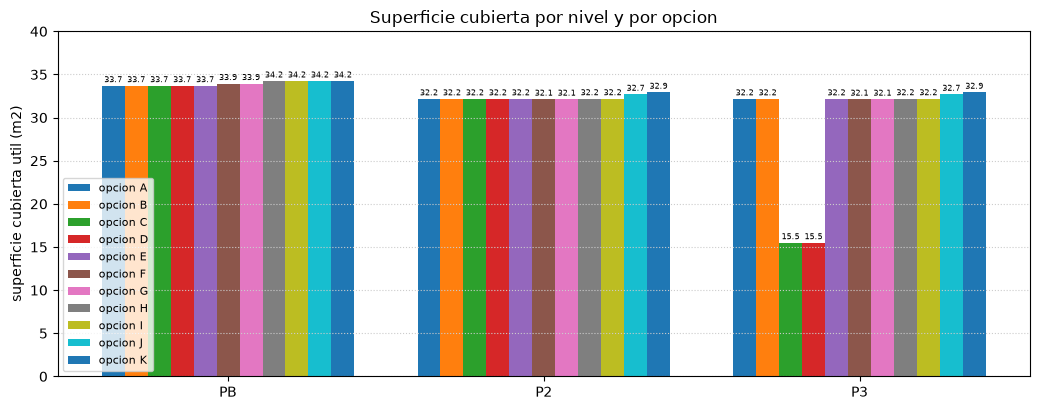


VEREDICTO DE AUDITORIA — VIVIENDA DE 3 PISOS SOBRE LOTE EN Z
Zona bioclimatica: III (IRAM 11603) | unidad base: 1 unidad = 1 m
Normas: IRAM 11601 / 11605 / 11630, CIRSOC 101 y 201, codigo de edificacion

Opcion A. Cocina al fondo y piso 3 completo: APROBADA CON OBSERVACIONES
   cubierta 98.01 m2 | exterior 31.05 m2 | dormitorios 3 | principal 9.69 m2 | secundario 9.37 m2
   errores 0 | avisos 17
Opcion B. Cocina integrada al frente y piso 3 completo: APROBADA CON OBSERVACIONES
   cubierta 98.01 m2 | exterior 31.05 m2 | dormitorios 3 | principal 9.69 m2 | secundario 9.37 m2
   errores 0 | avisos 18
Opcion C. Cocina al fondo y terraza de asador sobre la fachada: APROBADA CON OBSERVACIONES
   cubierta 81.34 m2 | exterior 31.05 m2 | dormitorios 2 | principal 9.69 m2 | secundario 9.37 m2
   errores 0 | avisos 14
Opcion D. Cocina integrada al frente y terraza de asador sobre la fachada: APROBADA CON OBSERVACIONES
   cubierta 81.34 m2 | exterior 31.05 m2 | dormitorios 2 | principal 9.69 m2 |

In [8]:
import textwrap


def numero(valor: float, decimales: int = 2) -> str:
    """Formatea un numero con coma decimal, como el resto de la memoria."""
    return f'{valor:.{decimales}f}'.replace('.', ',')


RESUMEN = {}
for id_opcion, opcion in OPCIONES.items():
    cubierta_m2 = exterior_m2 = habitable_m2 = fachada_m2 = muesca_m2 = 0.0
    for nombre_nivel, nivel in opcion['niveles'].items():
        for un_local in nivel['locales']:
            if un_local.tipo == 'terraza':
                exterior_m2 += un_local.area_m2
                continue
            if un_local.tipo in ('lucernario', 'tabique', 'umbral', 'cubierta'):
                continue
            cubierta_m2 += un_local.area_m2
            if un_local.tipo not in TIPOS_HABITABLES:
                continue
            habitable_m2 += un_local.area_m2
            propios = [v for v in nivel['vanos'] if v.local == un_local.nombre]
            if any(v.muro in ('M1', 'MT') for v in propios):
                fachada_m2 += un_local.area_m2
            elif any(v.luz_secundaria for v in propios):
                muesca_m2 += un_local.area_m2
        exterior_m2 += sum(l.area_m2 for l in nivel['exteriores'])
    errores = [h for h in HALLAZGOS if h['opcion'] == id_opcion and h['severidad'] == 'error']
    avisos = [h for h in HALLAZGOS if h['opcion'] == id_opcion and h['severidad'] == 'aviso']
    habitables = {(n, l.nombre): l for n, d in opcion['niveles'].items()
                  for l in d['locales'] if l.tipo in ('dormitorio_ppal', 'dormitorio', 'estar',
                                                      'quincho', 'comedor')}
    ppal_m2 = max((l.area_m2 for l in habitables.values() if l.tipo == 'dormitorio_ppal'), default=0.0)
    secundario_m2 = max((l.area_m2 for l in habitables.values() if l.tipo == 'dormitorio'), default=0.0)
    dormitorios_n = sum(1 for nivel_d in opcion['niveles'].values()
                        for un_local in nivel_d['locales']
                        if un_local.tipo in ('dormitorio', 'dormitorio_ppal'))
    RESUMEN[id_opcion] = {
        'cubierta_m2': cubierta_m2, 'exterior_m2': exterior_m2, 'habitable_m2': habitable_m2,
        'fachada_m2': fachada_m2, 'muesca_m2': muesca_m2, 'errores': len(errores),
        'avisos': len(avisos), 'ppal_m2': ppal_m2, 'secundario_m2': secundario_m2,
        'dormitorios_n': dormitorios_n, 'libre_m': altura_libre_de(opcion),
        'azotea_m': cotas_de(opcion)['AZOTEA'],
    }

print('--- comparacion ---')
print(f'{"":<46}' + ''.join(f'{i:>8}' for i in OPCIONES))
FILAS_COMPARACION = [
    ('superficie cubierta total (m2)', 'cubierta_m2', '{:.2f}'),
    ('superficie exterior: azotea y terraza (m2)', 'exterior_m2', '{:.2f}'),
    ('superficie habitable (m2)', 'habitable_m2', '{:.2f}'),
    ('habitable con luz de fachada (m2)', 'fachada_m2', '{:.2f}'),
    ('habitable que depende de la muesca (m2)', 'muesca_m2', '{:.2f}'),
    ('dormitorios', 'dormitorios_n', '{:d}'),
    ('dormitorio principal (m2)', 'ppal_m2', '{:.2f}'),
    ('dormitorio secundario (m2)', 'secundario_m2', '{:.2f}'),
    ('cielorraso libre (m)', 'libre_m', '{:.2f}'),
    ('cota de la azotea (m)', 'azotea_m', '{:.2f}'),
    ('errores bloqueantes', 'errores', '{:d}'),
    ('avisos', 'avisos', '{:d}'),
]
for etiqueta, clave, formato in FILAS_COMPARACION:
    valores = ''.join(f'{formato.format(RESUMEN[i][clave]):>8}' for i in OPCIONES)
    print(f'{etiqueta:<46}{valores}')
for id_opcion in OPCIONES:
    resumen = RESUMEN[id_opcion]
    fraccion = resumen['fachada_m2'] / resumen['habitable_m2'] if resumen['habitable_m2'] else 0.0
    print(f'opcion {id_opcion}: {fraccion:.0%} de la superficie habitable con luz directa de fachada')

fig, ax = plt.subplots(figsize=(10.5, 4.2))
niveles_dibujo = ('PB', 'P2', 'P3')
ids_opciones = list(OPCIONES)
ancho_barra = 0.8 / len(ids_opciones)
for i, id_opcion in enumerate(ids_opciones):
    valores = [sum(l.area_m2 for l in OPCIONES[id_opcion]['niveles'][n]['locales']
                   if l.tipo not in ('terraza', 'lucernario', 'tabique', 'umbral')) for n in niveles_dibujo]
    posiciones = [j + (i - (len(ids_opciones) - 1) / 2) * ancho_barra
                  for j in range(len(niveles_dibujo))]
    barras = ax.bar(posiciones, valores, width=ancho_barra, label=f'opcion {id_opcion}')
    ax.bar_label(barras, fmt='%.1f', fontsize=5.8, padding=1.2)
ax.set_xticks(range(len(niveles_dibujo)))
ax.set_xticklabels(niveles_dibujo)
ax.set_ylabel('superficie cubierta util (m2)')
ax.set_title('Superficie cubierta por nivel y por opcion')
ax.legend(fontsize=8)
ax.grid(axis='y', ls=':', color='#cccccc')
ax.set_ylim(0, 40)
fig.tight_layout()
plt.show()

print()
print('=' * 82)
print('VEREDICTO DE AUDITORIA — VIVIENDA DE 3 PISOS SOBRE LOTE EN Z')
print('=' * 82)
print(f'Zona bioclimatica: {ZONA_BIOCLIMATICA} (IRAM 11603) | unidad base: 1 unidad = 1 {UNIDAD_BASE}')
print(f'Normas: IRAM 11601 / 11605 / 11630, CIRSOC 101 y 201, codigo de edificacion')
print()
for id_opcion, opcion in OPCIONES.items():
    resumen = RESUMEN[id_opcion]
    if resumen['errores']:
        estado = 'RECHAZADA'
    elif resumen['avisos']:
        estado = 'APROBADA CON OBSERVACIONES'
    else:
        estado = 'APROBADA'
    print(f'{opcion["nombre"]}: {estado}')
    print(f'   cubierta {resumen["cubierta_m2"]:.2f} m2 | exterior {resumen["exterior_m2"]:.2f} m2 | '
          f'dormitorios {resumen["dormitorios_n"]} | principal {resumen["ppal_m2"]:.2f} m2 | '
          f'secundario {resumen["secundario_m2"]:.2f} m2')
    print(f'   errores {resumen["errores"]} | avisos {resumen["avisos"]}')
print()
print(textwrap.fill(
    f'Circulacion verificada por relleno de inundacion: el ingreso llega a todos los locales de '
    f'planta baja, el paso entre bloques mantiene 0,90 m libres o mas en todos los niveles y el '
    f'extremo oeste de la barra delantera se alcanza siempre. A a G suben en un tramo recto con '
    f'corredor de 0,90 m; H a K en una U de dos tramos pegada a la puerta, con las dos subidas a lo '
    f'largo de la fachada y el primer escalon a {numero(RETIRO_ESCALERA_PUERTA_M)} m de la hoja. Las '
    f'otras formas con giro -U en la profundidad, Z y L- se descartaron en la seccion 4b con la '
    f'misma malla, porque cortan la barra delantera o cierran el paso entre bloques.', 96))
print()
HALLAZGOS_GENERALES = [h for h in HALLAZGOS if h['opcion'] == 'todas']
if HALLAZGOS_GENERALES:
    print(f'Hallazgos generales (aplican a las {len(OPCIONES)} opciones)')
    for hallazgo in HALLAZGOS_GENERALES:
        marca = 'ERROR' if hallazgo['severidad'] == 'error' else 'AVISO'
        print(f'   [{marca}] {hallazgo["elemento"]}: {hallazgo["parametro"]} = {hallazgo["valor"]} '
              f'({hallazgo["referencia"]}) — {hallazgo["recomendacion"]}')
    print()
for id_opcion in OPCIONES:
    propios = [h for h in HALLAZGOS if h['opcion'] == id_opcion]
    if not propios:
        continue
    print(f'Observaciones de la opcion {id_opcion}')
    for hallazgo in propios:
        marca = 'ERROR' if hallazgo['severidad'] == 'error' else 'AVISO'
        print(f'   [{marca}] {hallazgo["elemento"]}: {hallazgo["parametro"]} = {hallazgo["valor"]} '
              f'({hallazgo["referencia"]}) — {hallazgo["recomendacion"]}')
    print()

candidatas = [i for i in OPCIONES if RESUMEN[i]['errores'] == 0]
# el ranking no puede premiar una casa chica con mucha luz: se exige primero una calidad de luz
# minima (25 % de la superficie habitable con fachada) y despues se maximiza la superficie
LUZ_FACHADA_MIN = 0.25
iluminadas = [i for i in candidatas if RESUMEN[i]['habitable_m2']
              and RESUMEN[i]['fachada_m2'] / RESUMEN[i]['habitable_m2'] >= LUZ_FACHADA_MIN]
if iluminadas:
    recomendada = max(iluminadas, key=lambda i: RESUMEN[i]['habitable_m2'])
    motivo = (f'maximiza la superficie habitable con al menos {LUZ_FACHADA_MIN:.0%} de ella con luz '
              f'directa de fachada, entre las que no tienen errores')
elif candidatas:
    recomendada = max(candidatas, key=lambda i: (RESUMEN[i]['fachada_m2'], RESUMEN[i]['cubierta_m2']))
    motivo = 'maximiza la superficie habitable con luz directa de fachada entre las que no tienen errores'
else:
    recomendada = min(OPCIONES, key=lambda i: (RESUMEN[i]['errores'], -RESUMEN[i]['fachada_m2']))
    motivo = 'es la que tiene menos errores bloqueantes'
print('RECOMENDACION')
print(textwrap.fill(f'Criterio: {motivo}.', 96, initial_indent='   ',
                    subsequent_indent='   '))
print(textwrap.fill(
    f'Gana la opcion {recomendada}, con {RESUMEN[recomendada]["fachada_m2"]:.2f} m2 de '
    f'{RESUMEN[recomendada]["habitable_m2"]:.2f} m2 habitables con luz de fachada, '
    f'{RESUMEN[recomendada]["cubierta_m2"]:.2f} m2 cubiertos y '
    f'{RESUMEN[recomendada]["exterior_m2"]:.2f} m2 exteriores.', 96, initial_indent='   ',
    subsequent_indent='   '))
mas_cubierta = max(OPCIONES, key=lambda i: RESUMEN[i]['cubierta_m2'])
if mas_cubierta == recomendada:
    desvios_de_lado = [h for h in HALLAZGOS if h['opcion'] == recomendada
                       and h['parametro'] == 'lado' and 'desvio declarado' in h['referencia']]
    cabecera = (f'   Tambien es la que mas superficie cubierta deja: '
                f'{RESUMEN[recomendada]["cubierta_m2"]:.2f} m2, con '
                f'{RESUMEN[recomendada]["avisos"]} avisos y ningun error bloqueante')
    print(cabecera + ', a cambio de' if desvios_de_lado else cabecera + '.')
    if desvios_de_lado:
        detalle = ' y '.join(f'{h["elemento"]} en {h["valor"]}' for h in desvios_de_lado)
        print(f'   {detalle}, contra los {DORM_SEC_LADO_MIN_M:.2f} m del codigo.')
else:
    print(f'   El costo de esa eleccion es superficie cubierta: la opcion {mas_cubierta} tiene '
          f'{RESUMEN[mas_cubierta]["cubierta_m2"]:.2f} m2, '
          f'{RESUMEN[mas_cubierta]["cubierta_m2"] - RESUMEN[recomendada]["cubierta_m2"]:.2f} m2 mas, '
          f'y {RESUMEN[mas_cubierta]["fachada_m2"]:.2f} m2 habitables con luz de fachada.')
    fuera_por_luz = [i for i in candidatas if i not in iluminadas]
    if fuera_por_luz:
        detalle = ', '.join(f'{i} ({RESUMEN[i]["fachada_m2"] / RESUMEN[i]["habitable_m2"]:.0%})'
                            for i in fuera_por_luz)
        print(textwrap.fill(
            f'Quedan fuera del criterio por luz de fachada {detalle}: con la U sobre la fachada solo '
            f'el ambiente de planta baja toma luz directa por M1 y la franja del norte es '
            f'circulacion, de modo que la mayor parte de la superficie habitable se ilumina por la '
            f'muesca. Es el precio de tener el primer escalon en la puerta.', 96,
            initial_indent='   ', subsequent_indent='   '))
print()
print(textwrap.fill(
    f'Las {len(OPCIONES)} comparten estructura y la puerta de calle en la posicion del levantamiento. '
    f'A a G llevan la escalera con corredor de 0,90 m: A a E en la barra de fondo y F y G en la barra '
    f'de 3 x 6. H a K la llevan pegada a la puerta, en U de dos tramos a lo largo de la fachada y '
    f'con la huella de ley, sin corredor.', 96, initial_indent='   ', subsequent_indent='   '))
print('   A a E ponen la escalera en la barra de fondo: el corredor cuesta 2,67 m2 por nivel y el')
print('   matrimonio queda en 9,69 m2 (declarado), pero el frente queda entero para la vida diaria.')
print('   F y G la dejan en la barra de 3 x 6: ahi entra recta y con la huella del codigo (0,28 m),')
print('   el matrimonio conserva 11,86 m2 con el bano en suite y la hija 10,79 m2 con placard; el')
print('   costo es que en planta baja esa barra queda con una banda de 1,22 m, que es galeria y no')
print('   estar.')
print()
frente_pb = next(l for l in OPCIONES['H']['niveles']['PB']['locales'] if l.nombre == 'estar-comedor')
fondo_p2 = next(l for l in OPCIONES['H']['niveles']['P2']['locales']
                if l.nombre == 'dormitorio matrimonio')
vestidor_j_m2 = next(l for l in OPCIONES['J']['niveles']['P2']['locales']
                    if l.nombre == 'vestidor').area_m2
vestidor_k_m2 = next(l for l in OPCIONES['K']['niveles']['P2']['locales']
                     if l.nombre == 'vestidor').area_m2
CIERRE_FAMILIA_3 = (
    f'H a K resuelven el pedido del cliente al pie de la letra: se entra y el primer escalon esta a '
    f'la izquierda, a {numero(RETIRO_ESCALERA_PUERTA_M)} m de la hoja, porque la U arranca sobre la '
    f'fachada. En H e I son 16 alzadas de 0,1719 m en dos tramos de 8, con meseta de 0,90 m a '
    f'1,38 m; en J y K, {ALTURA_U_BAJA["n_alzadas"]} alzadas de '
    f'{numero(ALTURA_U_BAJA["alzada_m"], 4)} m en tramos de {ALTURA_U_BAJA["tramos"][0]} y '
    f'{ALTURA_U_BAJA["tramos"][1]}, con la meseta a {numero(ALTURA_U_BAJA["meseta_m"])} m. Las dos '
    f'variantes entran con 14 huellas de 0,28 m, sin tramo recto largo y sin el desvio de alzada '
    f'que declaran A a E.'
    f'\n\n'
    f'El precio esta en la barra delantera. La U ocupa 1,70 m de sus 3,07 m de profundidad, de modo '
    f'que al norte queda una franja de {numero(ESCALERA_PUERTA_PB["franja_m"])} m que es circulacion '
    f'y no ambiente. En planta baja no molesta, porque el estar-comedor rodea la escalera y conserva '
    f'{numero(frente_pb.area_m2)} m2 con su ventana sobre M1; en los pisos altos el frente se '
    f'resuelve con vestidor -y distribuidor en H e I- y la pieza -matrimonio en P2, estudio y '
    f'huespedes en P3- va a la barra de fondo, con {numero(fondo_p2.area_m2)} m2 y ventana a la '
    f'muesca. La meseta de la U no es un descanso de reposo: es la plataforma de giro, cuenta como '
    f'una huella y cierra el desarrollo con las 14 huellas de los dos tramos.'
    f'\n\n'
    f'Por eso H a K tienen una pieza por piso alto y no dos: descontado el bano, la barra de fondo no '
    f'da dos dormitorios sobre los 8 m2 del codigo. Es el costo de entrar y tener la escalera ahi '
    f'mismo; A a G lo pagan al reves, con la escalera lejos de la puerta pero el frente libre.'
    f'\n\n'
    f'Las otras formas pegadas a la puerta se descartaron en la seccion 4b con numeros: la U con las '
    f'subidas en la profundidad cierra el paso entre bloques y deja el ambiente del frente sin '
    f'acceso; el Z y la L cortan la barra en dos y el ambiente del oeste queda incomunicado.'
)
for parrafo in CIERRE_FAMILIA_3.split('\n\n'):
    print(textwrap.fill(parrafo, 96, initial_indent='   ', subsequent_indent='   '))
print()
print(textwrap.fill(
    f'J y K prueban la variante de cielorraso bajo. J es la planta de H con '
    f'{ALTURA_U_BAJA["n_alzadas"]} alzadas de {numero(ALTURA_U_BAJA["alzada_m"], 4)} m: la U no '
    f'cambia de planta -sigue midiendo {numero(ALTURA_U_BAJA["largo_u_m"])} x '
    f'{numero(ANCHO_U_M)} m- y lo que baja es la altura total, de '
    f'{numero(ALTURA_U_BASE["total_m"])} a {numero(ALTURA_U_BAJA["total_m"])} m, a cambio de '
    f'{numero(ALTURA_U_BAJA["altura_libre_m"])} m de cielorraso, que se declara como desvio. '
    f'K usa esa misma altura para mudar el bano al frente: la barra de fondo queda entera para la '
    f'pieza, que pasa de 12,46 a 15,48 m2, con el costo de una segunda bajada de desague porque el '
    f'bano de planta baja sigue en la barra de fondo.', 96, initial_indent='   ',
    subsequent_indent='   '))
print(textwrap.fill(
    f'En las dos, ademas, desaparece el distribuidor: la franja que rodea la escalera pasa a ser un '
    f'vestidor que sirve de acceso a la pieza, de placard y de paso al cuello. Son '
    f'{numero(vestidor_j_m2)} m2 en J y {numero(vestidor_k_m2)} m2 en K, que dejan de contarse como '
    f'circulacion. No se pueden contar como ambiente habitable: la franja tiene 1,27 m de ancho y no '
    f'admite otro uso que el de paso y guardado. A cambio, la llegada de la escalera queda dentro de '
    f'la pieza: la planta alta es una suite, sin pasillo.', 96, initial_indent='   ',
    subsequent_indent='   '))
print()
print()
print('   Pendientes de cierre: servidumbre de las ventanas a la muesca; verificacion del corredor')
print('   de 1,50 m para los niveles altos; y firma del predimensionado por profesional estructural.')
